# Adversarial robustness training — improved version

**Why the original underperformed:** clean-model test ROC-AUC was 0.497 (chance). The adversarial numbers
were meaningless because ART fine-tuning started from a model that had not learned the task.

**Changes (all in the first 6 code cells; later cells untouched except small bookkeeping patches):**
1. **Face crops** instead of full frames (biggest fix). Haar detector, one stable box per clip, margin 1.3, 256px crops.
2. **More data**: 800 → 2000 videos, and fakes are sampled from *all five* methods (before: only the first method).
3. **Frozen BatchNorm stays in eval mode** (was drifting during Phase 1).
4. **Optimisation**: head LR 3e-4, backbone LR 1e-4, 5 blocks unfrozen, 3+12 epochs, cosine decay, weight decay 1e-2, patience 6.
5. **Checkpoint selection by val ROC-AUC** (F1@0.5 sat at 0.333 and could not rank epochs).
6. **Lighter augmentation** (less extra JPEG, ±5° rotation, no hue shift); sampler off since the data is balanced.
7. **Adversarial fine-tuning**: 0.1× LR, 5 epochs, 0.7/0.3 loss weights, cosine schedule, warning if the clean model is near chance.


In [1]:
# ============================================================
# CELL 1: Configuration, imports and shared utilities
# ============================================================
import os
# Reduce CUDA memory fragmentation (must be set before torch initializes its
# CUDA caching allocator, so this line stays first, before `import torch`).
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import copy
import gc
import json
import math
import random
import time
from contextlib import nullcontext
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch._utils  # noqa: F401
# Kaggle-environment fix (preserved): some torch/torchvision builds don't have
# `torch._utils` bound as an attribute of `torch` yet at this point, which
# makes `from torchvision import transforms` fail with
# "AttributeError: module 'torch' has no attribute '_utils'". Must run before
# any torchvision import.
import torch.nn as nn
import torch.nn.functional as Fn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.utils import make_grid
from torchvision.models import efficientnet_b1, EfficientNet_B1_Weights
import torchvision.transforms.functional as TF

import torch.multiprocessing as _mp
try:
    # Prefer "fork" so DataLoader worker processes inherit this process's
    # already-fixed `torch` module instead of re-importing it from scratch.
    _mp.set_start_method("fork", force=True)
except RuntimeError:
    pass  # start method already set for this kernel session; safe to ignore

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, balanced_accuracy_score, confusion_matrix,
    classification_report, roc_curve,
)
from tqdm import tqdm

try:
    from scipy.stats import binomtest as _binomtest
except Exception:          # very old scipy: fall back to a manual exact test below
    _binomtest = None

NOTEBOOK_START = time.time()   # used by the ART deadline and the multi-seed time guard

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# ============================================================
# CONFIGURATION
# ============================================================
CONFIG = {
    # ---- Data ----
    "data_root": "/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23",
    "seed": 42,                       # TRAINING seed of the main run
    "split_seed": 42,                 # identity split seed (shared by all training seeds)
    "extra_seeds": [],                # extra TRAINING seeds (last cell). v6 targets ONE ~6 h run, so this is off by
                                      # default; the time guard would skip them anyway on an 8 h budget.
    "time_budget_hours": 8.0,         # hard planning budget for the WHOLE notebook (user limit: 8-9 h)
    "art_deadline_hours": None,       # ART training stops starting new epochs after this much wall-clock time since
                                      # notebook start; None -> time_budget_hours - 2.3 (leaves time for the evaluation)

    # ---- Identity-disjoint split (review item 3) ----
    # Every identity (BOTH ids of a fake 'TARGET_SOURCE') is assigned to exactly one split.
    # A video is kept only if all of its ids are in the same split.
    "val_id_fraction": 0.15,
    "test_id_fraction": 0.20,         # was 0.15; larger test set -> tighter confidence intervals
    "split_search_trials": 300,       # random identity partitions tried; best eligible-count wins
    "train_per_class_cap": 800,       # max train videos per class (time budget for extraction)
    "eval_per_class_cap": 250,        # max val / test videos per class
    "train_fake_to_real_ratio": 2.0,  # v6: 2 fakes per real in TRAIN (v5 used 1.0 and overfit: train 95% vs val 88%).
                                      # A class-balanced WeightedRandomSampler is enabled automatically. Val/test are
                                      # unchanged (still 1:1), so v5 and v6 test numbers are directly comparable.

    # ---- Temporal sampling ----
    "seq_len": 16,                    # 16 EVENLY SAMPLED frames (np.linspace), not consecutive
    "frame_pool_size": 32,            # extracted per video; train picks 16 of them each epoch
    "img_size": 224,
    "clip_stride": 2,                 # consecutive-clip variant only (review item 12)
    "run_clip_variant": False,        # optional extra experiment (needs a second, shorter extraction)

    # ---- Face cropping (review item 8) ----
    "face_margin": 1.3,
    "face_crop_size": 256,
    "face_detect_every": 4,           # run the detector on every 4th pooled frame
    "face_min_detect_rate": 0.25,     # below this a clip falls back to a centre crop (and is flagged)
    "face_cache_input_dir": None,     # e.g. "/kaggle/input/<your-crops-dataset>/face_frames" to skip extraction
    "face_frames_dir": "/kaggle/working/face_frames",
    "face_frames_clip_dir": "/kaggle/working/face_frames_clip",

    # ---- Batching ----
    "batch_size": 8,
    "art_batch_size": 4,              # clean + adversarial are concatenated -> 8 videos per forward
    "eval_batch_size": 8,             # clean fp32 inference
    "eval_attack_batch_size": 4,      # fp32 attacks need more memory than AMP ones
    "num_workers": 2,                 # Kaggle fix (preserved): worker_init_fn below + fork start method

    # ---- Social-media DEGRADATION (random training augmentation, see scope note) ----
    "compression_prob": 0.3,
    "compression_downscale_range": (0.7, 1.0),
    "compression_jpeg_quality_range": (30, 70),
    "compression_blur_prob": 0.3,
    "compression_blur_kernel": 3,

    # ---- Spatial AUGMENTATION (moderate, preserves forensic artifacts) ----
    "aug_flip_prob": 0.5,
    "aug_rotation_range": (-5.0, 5.0),
    "aug_brightness_range": (0.9, 1.1),
    "aug_contrast_range": (0.9, 1.1),
    "aug_saturation_range": (0.95, 1.05),
    "aug_hue_range": (0.0, 0.0),
    "aug_crop_padding": 4,
    "aug_noise_prob": 0.2,
    "aug_noise_std": 0.01,

    # ---- Model architecture (unchanged) ----
    "lstm_hidden_size": 512,
    "lstm_num_layers": 2,
    "lstm_bidirectional": False,
    "dropout": 0.3,
    "use_temporal_attention": False,

    # ---- Clean training (review items 9, 10) ----
    "phase1_epochs": 0,               # frozen-backbone phase removed: it never learned (loss 0.693 for 3 epochs)
    "phase2_epochs": 16,              # v5 peaked at epoch 13 of 19; with 1.5x more data per epoch 16 is plenty
    "unfreeze_last_n_blocks": 5,
    "warmup_epochs": 1.0,             # linear LR warm-up at the start of Phase 2 (per step)
    "min_lr_ratio": 0.02,             # cosine floor, as a fraction of the peak LR
    "backbone_lr": 7e-5,              # was 1e-4  (lower Phase-2 peak LR)
    "head_lr": 2e-4,                  # was 3e-4
    "weight_decay": 2e-2,
    "grad_clip_norm": 5.0,
    "early_stopping_patience": 4,
    "label_smoothing": 0.05,
    "ema_decay": 0.998,               # weight averaging; the EMA weights are what gets validated/saved

    # ---- Adversarial fine-tuning (v6: longer, stronger, selected on a strong attack) ----
    "art_finetune_epochs": 14,        # v5: 6 epochs, and the selection score was STILL rising at the last one
    "art_steps_per_epoch": 350,       # cap on batches per ART "epoch" (350 x 4 = 1400 videos); keeps epochs ~6.5 min
    "art_lr_scale": 0.25,             # ART LRs = 0.25 x clean-training LRs
    "art_warmup_steps": 100,
    "art_epsilon": 2 / 255,           # training epsilon == first evaluation epsilon
    "art_eps_ramp_epochs": 2.0,       # epsilon ramps 0 -> art_epsilon over this many epochs (was 1)
    "art_loss": "pgd_at",             # "pgd_at" (Madry: clean + adversarial BCE on true labels) or "trades"
    "art_attack": "pgd",              # attack used to build training examples for pgd_at: "pgd" or "fgsm_rs"
    "art_pgd_steps": 5,               # v5: 3. Stronger inner attack; alpha = 2.5*eps/steps
    "pgd_step_mult": 2.5,             # alpha = pgd_step_mult * eps / steps
    "art_clean_loss_weight": 0.5,     # v5: 0.7/0.3 (adversarial loss stalled near ln2 = 0.693: the model hedged)
    "art_adv_loss_weight": 0.5,
    "trades_beta": 3.0,               # only used if art_loss == "trades" (loss = BCE(clean) + beta * KL(clean || adv))
    "ema_decay_art": 0.995,
    "run_loss_weight_comparison": False,   # optional (slow): also try 0.7/0.3 and 0.3/0.7
    "val_robust_n": 200,              # fixed balanced validation subset used for robust checkpoint selection (v5: 160)
    "val_robust_pgd_steps": 10,       # v5: PGD-5 (a much weaker attack than the one used on the test set)
    "robust_select_weight": 0.4,      # score = w * clean_val_AUC + (1-w) * PGD_val_AUC

    # ---- Sanity checks (review item 15) ----
    "sanity_n_videos": 64,
    "sanity_fgsm_eps_grid": [v / 255 for v in (0, 0.5, 1, 1.5, 2, 3, 4, 6, 8, 12, 16)],
    "sanity_pgd_eps": [1 / 255, 2 / 255, 4 / 255, 8 / 255],
    "sanity_pgd_steps": 5,

    # ---- Robustness evaluation: ALL attacks in fp32 ----
    "eval_use_amp": False,
    "robustness_fgsm_epsilons": [2 / 255, 4 / 255, 8 / 255],      # single-step: reported, never used alone
    # (name, epsilon, steps, random restarts) -- cross-entropy PGD
    "robustness_pgd_configs": [("PGD-10", 2 / 255, 10, 2),
                               ("PGD-10", 4 / 255, 10, 2),
                               ("PGD-20", 4 / 255, 20, 1)],
    # (epsilon, steps): momentum + step-decay PGD on the LOGIT-MARGIN loss with best-iterate tracking
    # (APGD-inspired; NOT the official AutoAttack). The margin loss cannot saturate, so it is the check against
    # gradient masking caused by a flat sigmoid/BCE loss.
    "robustness_margin_configs": [(2 / 255, 25), (4 / 255, 25)],
    "eps_sweep": [1 / 255, 2 / 255, 3 / 255, 4 / 255, 6 / 255, 8 / 255, 16 / 255],   # PGD-10 (1 restart) for monotonicity
    "eps_sweep_per_class": 50,
    "transfer_eps": 4 / 255,          # transfer check: craft on the clean-trained model, test on ART (black-box)
    "multiseed_pgd_configs": [("PGD-10", 2 / 255, 10, 2),
                              ("PGD-10", 4 / 255, 10, 2)],
    "main_attack_label": "PGD-10 4/255 (r2)",                     # used for confusion matrices / Grad-CAM
    "attack_eval_per_class": 100,     # every ATTACKED condition runs on the same balanced test subset (first N real +
                                      # N fake). v5 used 150; 100 keeps the stronger v6 attack suite inside the budget.
                                      # Clean full-test numbers are also reported. None -> attack the whole test set.
    "mask_check_tol": 0.05,           # tolerance used by the automatic gradient-masking checks

    # ---- Threshold selection (validation set ONLY; review items 2, 11) ----
    "threshold_method": "eer",        # "eer" (equal error rate) or "f1"
    "threshold_search_min": 0.05,     # was 0.30 (the old optimum sat exactly on the grid edge)
    "threshold_search_max": 0.95,
    "threshold_search_step": 0.01,

    # ---- Statistics (review item 7) ----
    "bootstrap_n": 1000,

    # ---- Checkpoints / artifacts ----
    "save_clean_checkpoint": "/kaggle/working/best_clean_model.pth",
    "save_art_checkpoint": "/kaggle/working/best_art_model.pth",
    "save_run_config_path": "/kaggle/working/run_config.json",
    "save_best_metrics_path": "/kaggle/working/best_metrics.json",

    # ---- System ----
    "device": torch.device("cuda" if torch.cuda.is_available() else "cpu"),
}

USE_AMP = (CONFIG["device"].type == "cuda")   # AMP is used for TRAINING only; evaluation attacks are fp32


def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_global_seed(CONFIG["seed"])


# ---- Shared utility functions ----
def free_cuda_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def unnormalize_frame(tensor_frame):
    mean = np.array(IMAGENET_MEAN)
    std = np.array(IMAGENET_STD)
    img = tensor_frame.detach().cpu().numpy().transpose(1, 2, 0)
    return np.clip(std * img + mean, 0, 1)


def compute_metrics(labels, probs, threshold=0.5):
    labels = np.asarray(labels).astype(int)
    probs = np.asarray(probs)
    preds = (probs >= threshold).astype(int)

    try:
        roc_auc = roc_auc_score(labels, probs)
    except ValueError:
        roc_auc = 0.0
    try:
        pr_auc = average_precision_score(labels, probs)
    except ValueError:
        pr_auc = 0.0

    cm = confusion_matrix(labels, preds, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)

    return {
        "threshold": threshold,
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, average="macro", zero_division=0),
        "recall": recall_score(labels, preds, average="macro", zero_division=0),
        "f1": f1_score(labels, preds, average="macro", zero_division=0),
        "precision_fake": precision_score(labels, preds, pos_label=1, zero_division=0),
        "recall_fake": recall_score(labels, preds, pos_label=1, zero_division=0),
        "f1_fake": f1_score(labels, preds, pos_label=1, zero_division=0),
        "precision_real": precision_score(labels, preds, pos_label=0, zero_division=0),
        "recall_real": recall_score(labels, preds, pos_label=0, zero_division=0),
        "f1_real": f1_score(labels, preds, pos_label=0, zero_division=0),
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "balanced_accuracy": balanced_accuracy_score(labels, preds),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


def print_metrics(tag, m):
    print(f"[{tag}] thr={m['threshold']:.3f}  Acc={m['accuracy']:.4f}  F1(macro)={m['f1']:.4f}  "
          f"ROC-AUC={m['roc_auc']:.4f}  PR-AUC={m['pr_auc']:.4f}  BalAcc={m['balanced_accuracy']:.4f}  "
          f"| TP={m['tp']} TN={m['tn']} FP={m['fp']} FN={m['fn']}")


# ---- Statistics helpers (review item 7) ----
def wilson_ci(k, n, z=1.96):
    """95% Wilson score interval for a binomial proportion k/n."""
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return (centre - half, centre + half)


def bootstrap_ci(labels, probs, threshold, n_boot=None, seed=0):
    """Percentile bootstrap (over videos) for accuracy and ROC-AUC. Returns dict of (low, high)."""
    n_boot = n_boot or CONFIG["bootstrap_n"]
    labels = np.asarray(labels).astype(int)
    probs = np.asarray(probs)
    rng = np.random.default_rng(seed)
    n = len(labels)
    accs, aucs = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        l, p = labels[idx], probs[idx]
        accs.append(float(np.mean((p >= threshold).astype(int) == l)))
        if l.min() != l.max():
            aucs.append(roc_auc_score(l, p))
    q = lambda a: (float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))) if len(a) else (float("nan"),) * 2
    return {"acc": q(accs), "auc": q(aucs)}


def mcnemar_exact(correct_a, correct_b):
    """Exact McNemar test on paired per-video correctness. Returns (b, c, p):
    b = A right & B wrong, c = A wrong & B right."""
    a = np.asarray(correct_a).astype(bool)
    b_ = np.asarray(correct_b).astype(bool)
    b = int((a & ~b_).sum())
    c = int((~a & b_).sum())
    n = b + c
    if n == 0:
        return b, c, 1.0
    k = min(b, c)
    if _binomtest is not None:
        return b, c, float(_binomtest(k, n, 0.5).pvalue)
    p = 2.0 * sum(math.comb(n, i) for i in range(k + 1)) / (2 ** n)
    return b, c, float(min(1.0, p))


def expected_calibration_error(labels, probs, n_bins=10):
    labels = np.asarray(labels).astype(int)
    probs = np.asarray(probs)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (probs >= lo) & (probs < hi if hi < 1.0 else probs <= hi)
        if m.sum() == 0:
            continue
        ece += m.mean() * abs(probs[m].mean() - labels[m].mean())
    return float(ece)


def fit_temperature(logits, labels):
    """Temperature scaling: one scalar T>0 minimising validation NLL of sigmoid(logit / T)."""
    z = torch.tensor(np.asarray(logits), dtype=torch.float32)
    y = torch.tensor(np.asarray(labels), dtype=torch.float32)
    log_t = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=100)

    def closure():
        opt.zero_grad()
        loss = Fn.binary_cross_entropy_with_logits(z / torch.exp(log_t), y)
        loss.backward()
        return loss

    opt.step(closure)
    return float(torch.exp(log_t).clamp(0.05, 20.0).item())


def sigmoid_np(z, T=1.0):
    return 1.0 / (1.0 + np.exp(-np.asarray(z, dtype=np.float64) / T))


print("=" * 70)
print("CONFIGURATION SUMMARY")
print("=" * 70)
print(f"Device                    : {CONFIG['device']}   (AMP for training only: {USE_AMP})")
print(f"Training seed / split seed: {CONFIG['seed']} / {CONFIG['split_seed']}   extra seeds: {CONFIG['extra_seeds']}")
print(f"ID fractions val/test     : {CONFIG['val_id_fraction']} / {CONFIG['test_id_fraction']}  (identity-disjoint)")
print(f"seq_len / frame_pool      : {CONFIG['seq_len']} (EVENLY SAMPLED frames) / {CONFIG['frame_pool_size']}")
print(f"img_size / batch_size     : {CONFIG['img_size']} / {CONFIG['batch_size']}   (ART batch {CONFIG['art_batch_size']} clean + {CONFIG['art_batch_size']} adv)")
print(f"Epochs phase1/phase2      : {CONFIG['phase1_epochs']} / {CONFIG['phase2_epochs']}  warmup={CONFIG['warmup_epochs']} epoch(s)")
print(f"backbone_lr / head_lr     : {CONFIG['backbone_lr']} / {CONFIG['head_lr']}  wd={CONFIG['weight_decay']}  "
      f"label_smoothing={CONFIG['label_smoothing']}  EMA={CONFIG['ema_decay']}")
print(f"LSTM hidden/layers/bidir  : {CONFIG['lstm_hidden_size']} / {CONFIG['lstm_num_layers']} / {CONFIG['lstm_bidirectional']}")
print(f"ART                       : loss={CONFIG['art_loss']} attack={CONFIG['art_attack']}-{CONFIG['art_pgd_steps']} "
      f"eps={CONFIG['art_epsilon'] * 255:.0f}/255 w(clean/adv)={CONFIG['art_clean_loss_weight']}/{CONFIG['art_adv_loss_weight']}  "
      f"epochs={CONFIG['art_finetune_epochs']} x {CONFIG['art_steps_per_epoch']} batches")
print(f"Train fake:real ratio     : {CONFIG['train_fake_to_real_ratio']}   | time budget {CONFIG['time_budget_hours']} h, "
      f"ART deadline {CONFIG['art_deadline_hours'] or CONFIG['time_budget_hours'] - 2.3:.1f} h after notebook start")
print(f"Eval attacks              : fp32, " + ", ".join(f"{n} {round(e * 255)}/255 (r{r})" for n, e, s, r in CONFIG["robustness_pgd_configs"])
      + ", " + ", ".join(f"BestMargin-{st} {round(e * 255)}/255" for e, st in CONFIG["robustness_margin_configs"]))
print(f"Threshold                 : {CONFIG['threshold_method']} on validation (calibrated probabilities)")
print("=" * 70)
print("NOTE on reproducibility: cuDNN's fused RNN (LSTM) backward kernel is not bit-exact")
print("deterministic even with cudnn.deterministic=True (a known PyTorch/cuDNN limitation).")


CONFIGURATION SUMMARY
Device                    : cuda   (AMP for training only: True)
Training seed / split seed: 42 / 42   extra seeds: []
ID fractions val/test     : 0.15 / 0.2  (identity-disjoint)
seq_len / frame_pool      : 16 (EVENLY SAMPLED frames) / 32
img_size / batch_size     : 224 / 8   (ART batch 4 clean + 4 adv)
Epochs phase1/phase2      : 0 / 16  warmup=1.0 epoch(s)
backbone_lr / head_lr     : 7e-05 / 0.0002  wd=0.02  label_smoothing=0.05  EMA=0.998
LSTM hidden/layers/bidir  : 512 / 2 / False
ART                       : loss=pgd_at attack=pgd-5 eps=2/255 w(clean/adv)=0.5/0.5  epochs=14 x 350 batches
Train fake:real ratio     : 2.0   | time budget 8.0 h, ART deadline 5.7 h after notebook start
Eval attacks              : fp32, PGD-10 2/255 (r2), PGD-10 4/255 (r2), PGD-20 4/255 (r1), BestMargin-25 2/255, BestMargin-25 4/255
Threshold                 : eer on validation (calibrated probabilities)
NOTE on reproducibility: cuDNN's fused RNN (LSTM) backward kernel is not bit-ex

In [2]:
# ============================================================
# CELL 2: Data -- identity-disjoint split, face crops, dataset, loaders
# ============================================================
# Review item 3: v4 grouped videos by the FIRST id of the folder name only. Fake videos are named
# TARGET_SOURCE, so the SOURCE person could sit in train while the same person appeared in a test
# video. Here every identity (both ids) is assigned to exactly ONE split and a video is kept only
# if all of its ids live in that split. (A connected-components grouping is NOT used: in FF++ the
# target/source pairs chain almost all identities into one giant component, which cannot be split.)
SPLITS = ("train", "val", "test")


def _video_ids(path):
    return tuple(t for t in Path(path).stem.split("_") if t)


def discover_all_videos(data_root):
    """List EVERY candidate video (cheap: no decoding). Selection happens after the split."""
    root_path = Path(data_root)
    real_folders = ["original", "Original", "real"]
    fake_folders = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures", "FaceShifter"]
    videos = []
    for rf in real_folders:
        r_path = root_path / rf
        if r_path.exists():
            for p in sorted(list(r_path.glob("*.mp4")) + list(r_path.glob("*/*.mp4"))):
                videos.append({"path": str(p), "label": 0, "method": "real", "ids": _video_ids(p)})
    for ff in fake_folders:
        f_path = root_path / ff
        if f_path.exists():
            for p in sorted(list(f_path.glob("*.mp4")) + list(f_path.glob("*/*.mp4"))):
                videos.append({"path": str(p), "label": 1, "method": ff, "ids": _video_ids(p)})
    return videos


def _assign_identities(all_ids, seed, val_frac, test_frac):
    ids = sorted(all_ids)
    random.Random(seed).shuffle(ids)
    n = len(ids)
    n_test, n_val = int(round(n * test_frac)), int(round(n * val_frac))
    id2split = {}
    for i, ident in enumerate(ids):
        id2split[ident] = "test" if i < n_test else ("val" if i < n_test + n_val else "train")
    return id2split


def _count_eligible(videos, id2split):
    counts = {s: {"real": 0, "fake": 0} for s in SPLITS}
    for v in videos:
        s = {id2split[i] for i in v["ids"]}
        if len(s) == 1:
            counts[next(iter(s))]["real" if v["label"] == 0 else "fake"] += 1
    return counts


def identity_disjoint_split(videos, split_seed, val_frac, test_frac, n_trials):
    all_ids = {i for v in videos for i in v["ids"]}
    best = None
    for t in range(n_trials):
        id2split = _assign_identities(all_ids, split_seed + t, val_frac, test_frac)
        c = _count_eligible(videos, id2split)
        bal = {s: min(c[s]["real"], c[s]["fake"]) for s in SPLITS}
        # label/model-independent objective: as many balanced eval videos as possible, then more train
        objective = min(bal["test"] / max(test_frac, 1e-9), bal["val"] / max(val_frac, 1e-9)) + 0.1 * bal["train"]
        if best is None or objective > best[0]:
            best = (objective, t, id2split, c)
    _, t_best, id2split, counts = best
    pools = {s: {"real": [], "fake": {}} for s in SPLITS}
    n_dropped = 0
    for v in videos:
        s = {id2split[i] for i in v["ids"]}
        if len(s) != 1:
            n_dropped += 1
            continue
        s = next(iter(s))
        if v["label"] == 0:
            pools[s]["real"].append(v)
        else:
            pools[s]["fake"].setdefault(v["method"], []).append(v)
    return id2split, pools, counts, n_dropped, t_best


def _balanced_sample(real_pool, fake_pools, n_real_cap, ratio, rng):
    reals = list(real_pool)
    rng.shuffle(reals)
    methods = sorted(fake_pools)
    fakes = {m: rng.sample(fake_pools[m], len(fake_pools[m])) for m in methods}
    n_fake_avail = sum(len(x) for x in fakes.values())
    n_real = min(len(reals), n_real_cap, int(n_fake_avail / ratio))
    n_fake = int(round(n_real * ratio))
    chosen_fake = []
    while len(chosen_fake) < n_fake:           # round-robin over manipulation methods
        progressed = False
        for m in methods:
            if fakes[m] and len(chosen_fake) < n_fake:
                chosen_fake.append(fakes[m].pop())
                progressed = True
        if not progressed:
            break
    return reals[:n_real], chosen_fake


all_videos = discover_all_videos(CONFIG["data_root"])
if not all_videos:
    raise ValueError("No videos found. Check CONFIG['data_root'] path.")
n_all_real = sum(1 for v in all_videos if v["label"] == 0)
print(f"Discovered {n_all_real} real and {len(all_videos) - n_all_real} fake videos under {CONFIG['data_root']}")

id2split, pools, elig_counts, n_dropped, best_trial = identity_disjoint_split(
    all_videos, CONFIG["split_seed"], CONFIG["val_id_fraction"], CONFIG["test_id_fraction"],
    CONFIG["split_search_trials"])
print(f"Identity partition: trial {best_trial}/{CONFIG['split_search_trials']} "
      f"({sum(v == 'train' for v in id2split.values())} / {sum(v == 'val' for v in id2split.values())} / "
      f"{sum(v == 'test' for v in id2split.values())} identities train/val/test)")
print(f"Videos dropped because their ids straddle two splits: {n_dropped}/{len(all_videos)}")

_rng = random.Random(CONFIG["split_seed"])
selected = {}
for s in SPLITS:
    cap = CONFIG["train_per_class_cap"] if s == "train" else CONFIG["eval_per_class_cap"]
    ratio = CONFIG["train_fake_to_real_ratio"] if s == "train" else 1.0
    r, f = _balanced_sample(pools[s]["real"], pools[s]["fake"], cap, ratio, _rng)
    selected[s] = r + f
    print(f"  {s:<5}: eligible real={elig_counts[s]['real']:5d} fake={elig_counts[s]['fake']:5d}  ->  "
          f"selected real={len(r):4d} fake={len(f):4d}")

import hashlib
for _s in ("val", "test"):
    _fp = hashlib.md5("|".join(sorted(v["path"] for v in selected[_s])).encode()).hexdigest()[:10]
    print(f"  {_s} set fingerprint: {_fp}  (identical across runs with the same split_seed / caps -> v5 vs v6 comparable)")

# Hard guarantee, over ALL ids of every selected video (not just the first token):
ids_by_split = {s: {i for v in selected[s] for i in v["ids"]} for s in SPLITS}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    inter = ids_by_split[a] & ids_by_split[b]
    assert not inter, f"Identity leakage between {a} and {b}: {sorted(inter)[:10]}"
print("Identity-overlap check (ALL ids of every video): PASSED -- no person appears in more than one split.")

# ---------------- Face detection / cropping (review item 8) ----------------
_CASCADE_FILES = ["haarcascade_frontalface_default.xml", "haarcascade_frontalface_alt2.xml"]
_FACE_CASCADES = [cv2.CascadeClassifier(cv2.data.haarcascades + f) for f in _CASCADE_FILES]
_FACE_CASCADES = [c for c in _FACE_CASCADES if not c.empty()]
if not _FACE_CASCADES:
    raise RuntimeError("No Haar cascade could be loaded from cv2.data.haarcascades")


def _detect_face_box(frame_bgr):
    h, w = frame_bgr.shape[:2]
    scale = 640.0 / max(h, w) if max(h, w) > 640 else 1.0
    small = cv2.resize(frame_bgr, None, fx=scale, fy=scale) if scale < 1.0 else frame_bgr
    gray = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)
    for cascade, min_neighbors in zip(_FACE_CASCADES, (5, 4)):   # 2nd cascade only if the 1st finds nothing
        faces = cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=min_neighbors, minSize=(40, 40))
        if len(faces) > 0:
            x, y, fw, fh = max(faces, key=lambda b: b[2] * b[3])
            return x / scale, y / scale, fw / scale, fh / scale
    return None


def _video_face_square(frames_bgr, margin):
    """One stable square crop per clip (median centre, largest accepted size); outlier boxes (false
    positives) are rejected first. Returns (x0, y0, x1, y1, detected_flag, detect_rate)."""
    h, w = frames_bgr[0].shape[:2]
    tried = frames_bgr[::max(1, CONFIG["face_detect_every"])]
    boxes = [bx for bx in (_detect_face_box(f) for f in tried) if bx is not None]
    if len(boxes) >= 3:
        cxs = np.array([x + fw / 2 for x, y, fw, fh in boxes])
        cys = np.array([y + fh / 2 for x, y, fw, fh in boxes])
        szs = np.array([max(fw, fh) for x, y, fw, fh in boxes])
        mcx, mcy, msz = np.median(cxs), np.median(cys), np.median(szs)
        keep = (np.abs(cxs - mcx) < 0.5 * msz) & (np.abs(cys - mcy) < 0.5 * msz) & (szs > 0.5 * msz) & (szs < 2.0 * msz)
        boxes = [b for b, k in zip(boxes, keep) if k]
    detect_rate = len(boxes) / max(len(tried), 1)
    if boxes and detect_rate >= CONFIG["face_min_detect_rate"]:
        cx = float(np.median([x + fw / 2 for x, y, fw, fh in boxes]))
        cy = float(np.median([y + fh / 2 for x, y, fw, fh in boxes]))
        size = max(max(fw, fh) for x, y, fw, fh in boxes) * margin
        detected = True
    else:                                      # fallback: central square (flagged in the QA stats)
        cx, cy, size, detected = w / 2, h / 2, 0.7 * min(h, w), False
    size = min(size, h, w)
    x0 = int(np.clip(cx - size / 2, 0, w - size))
    y0 = int(np.clip(cy - size / 2, 0, h - size))
    return x0, y0, int(x0 + size), int(y0 + size), detected, detect_rate


def _read_pool_frames(v_path, frame_pool_size):
    cap = cv2.VideoCapture(str(v_path))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total_frames >= frame_pool_size:
        indices = np.linspace(0, total_frames - 1, frame_pool_size, dtype=int)
    else:
        indices = np.arange(max(total_frames, 1))
    target_indices = set(int(i) for i in indices)
    frames, curr_frame = [], 0
    while cap.isOpened() and len(frames) < len(target_indices):
        ret, frame = cap.read()
        if not ret:
            break
        if curr_frame in target_indices:
            frames.append(frame)
        curr_frame += 1
    cap.release()
    return frames


def extract_selected_to_disk(videos, output_dir, frame_pool_size):
    """Extract face crops only for the videos chosen by the identity-disjoint selection.
    Existing crops (this run's cache, or CONFIG['face_cache_input_dir']) are re-used."""
    out_path = Path(output_dir)
    out_path.mkdir(parents=True, exist_ok=True)
    boxes_path = out_path / "_face_boxes.json"
    boxes = json.load(open(boxes_path)) if boxes_path.exists() else {}
    folder_of = {}
    n_fallback = n_new = 0
    print(f"Preparing face crops for {len(videos)} selected videos ({frame_pool_size} frames/video; "
          f"only videos without cached crops are decoded)...")

    for v in tqdm(videos, desc="Extracting Faces"):
        v_path = Path(v["path"])
        sub = "real" if v["label"] == 0 else "fake"
        name = f"{v_path.parent.name}__{v_path.stem}"
        candidates = []
        if CONFIG["face_cache_input_dir"]:
            candidates.append(Path(CONFIG["face_cache_input_dir"]) / sub / name)
        candidates.append(out_path / sub / name)
        reused = next((c for c in candidates
                       if c.exists() and len(list(c.glob("*.jpg"))) >= min(frame_pool_size, CONFIG["seq_len"])), None)
        if reused is not None:
            folder_of[v["path"]] = str(reused)
            continue

        frames = _read_pool_frames(v_path, frame_pool_size)
        if not frames:
            continue
        n_new += 1
        vid_out_dir = out_path / sub / name
        vid_out_dir.mkdir(parents=True, exist_ok=True)
        x0, y0, x1, y1, ok, rate = _video_face_square(frames, CONFIG["face_margin"])
        n_fallback += (not ok)
        cs = CONFIG["face_crop_size"]
        for k, fr in enumerate(frames):
            crop = cv2.resize(fr[y0:y1, x0:x1], (cs, cs), interpolation=cv2.INTER_AREA)
            cv2.imwrite(str(vid_out_dir / f"frame_{k:03d}.jpg"), crop, [int(cv2.IMWRITE_JPEG_QUALITY), 95])
        boxes[name] = {"box": [x0, y0, x1, y1], "hw": [int(frames[0].shape[0]), int(frames[0].shape[1])],
                       "detect_rate": float(rate), "ok": bool(ok)}
        folder_of[v["path"]] = str(vid_out_dir)

    json.dump(boxes, open(boxes_path, "w"))
    print(f"Newly extracted: {n_new} videos; detector fell back to a centre crop for {n_fallback} of them "
          f"(per-video detection rates are in {boxes_path}).")
    return folder_of, boxes


_all_selected = [v for s in SPLITS for v in selected[s]]
folder_of, FACE_BOXES = extract_selected_to_disk(_all_selected, CONFIG["face_frames_dir"], CONFIG["frame_pool_size"])


def balance_by_min(records, seed):
    real = [r for r in records if r[1] == 0]
    fake = [r for r in records if r[1] == 1]
    n = min(len(real), len(fake))
    rng = random.Random(seed)
    rng.shuffle(real)
    rng.shuffle(fake)
    out = real[:n] + fake[:n]
    rng.shuffle(out)
    return out


record_info = {}          # folder -> {"method", "ids", "split", "video_path"}
split_records = {}
for s in SPLITS:
    recs = []
    for v in selected[s]:
        folder = folder_of.get(v["path"])
        if folder is None:                         # unreadable video: skipped
            continue
        recs.append((folder, v["label"]))
        record_info[folder] = {"method": v["method"], "ids": v["ids"], "split": s, "video_path": v["path"]}
    if s != "train" or CONFIG["train_fake_to_real_ratio"] == 1.0:
        recs = balance_by_min(recs, CONFIG["split_seed"])     # trims only if a video failed to decode
    split_records[s] = recs

train_records, val_records, test_records = split_records["train"], split_records["val"], split_records["test"]
extracted_records = train_records + val_records + test_records


def split_report(name, records):
    n_real = sum(1 for _, l in records if l == 0)
    n_fake = sum(1 for _, l in records if l == 1)
    n_ids = len({i for f, _ in records for i in record_info[f]["ids"]})
    print(f"{name:<6}: {len(records):5d} videos  |  real={n_real:5d}  fake={n_fake:5d}  |  identities={n_ids:4d}")


print("=" * 60)
print("IDENTITY-DISJOINT SPLIT REPORT")
print("=" * 60)
split_report("Train", train_records)
split_report("Val", val_records)
split_report("Test", test_records)
print("=" * 60)


# ---------------- Dataset ----------------
_VALID_MIN = torch.tensor([(0.0 - m) / s for m, s in zip(IMAGENET_MEAN, IMAGENET_STD)]).view(3, 1, 1)
_VALID_MAX = torch.tensor([(1.0 - m) / s for m, s in zip(IMAGENET_MEAN, IMAGENET_STD)]).view(3, 1, 1)


def apply_social_media_compression(img_rgb, scale_factor, should_blur, quality):
    h, w, _ = img_rgb.shape
    new_h, new_w = max(1, int(h * scale_factor)), max(1, int(w * scale_factor))
    img_resized = cv2.resize(img_rgb, (new_w, new_h), interpolation=cv2.INTER_AREA)
    img_resized = cv2.resize(img_resized, (w, h), interpolation=cv2.INTER_LINEAR)

    if should_blur:
        k = CONFIG["compression_blur_kernel"]
        k = k if k % 2 == 1 else k + 1
        img_resized = cv2.GaussianBlur(img_resized, (k, k), 0)

    encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
    _, encimg = cv2.imencode('.jpg', img_resized, encode_param)
    decimg = cv2.imdecode(encimg, 1)
    return decimg


class PreextractedVideoDataset(Dataset):
    def __init__(self, sample_records, seq_len=16, img_size=224, is_train=True):
        self.sample_records = sample_records
        self.seq_len = seq_len
        self.img_size = img_size
        self.is_train = is_train

    def __len__(self):
        return len(self.sample_records)

    def _sample_frame_indices(self, n_available, rng):
        if n_available <= self.seq_len:
            return list(range(n_available))

        bounds = np.linspace(0, n_available, self.seq_len + 1).astype(int)
        indices = []
        for i in range(self.seq_len):
            lo, hi = int(bounds[i]), int(bounds[i + 1])
            hi = max(hi, lo + 1)
            if self.is_train:
                indices.append(rng.randint(lo, hi - 1))
            else:
                indices.append((lo + hi - 1) // 2)
        return indices

    def __getitem__(self, idx):
        folder_path, label = self.sample_records[idx]
        folder = Path(folder_path)
        frame_files = sorted(list(folder.glob("*.jpg")))
        n_available = len(frame_files)

        rng = random.Random() if self.is_train else random.Random(0)

        frame_indices = self._sample_frame_indices(n_available, rng)
        selected_files = [frame_files[i] for i in frame_indices]

        should_compress = self.is_train and rng.random() < CONFIG["compression_prob"]
        compress_quality = (rng.randint(*CONFIG["compression_jpeg_quality_range"])
                             if should_compress else None)
        should_blur = should_compress and rng.random() < CONFIG["compression_blur_prob"]
        scale_factor = rng.uniform(*CONFIG["compression_downscale_range"])

        if self.is_train:
            do_flip = rng.random() < CONFIG["aug_flip_prob"]
            rotation_angle = rng.uniform(*CONFIG["aug_rotation_range"])
            brightness_factor = rng.uniform(*CONFIG["aug_brightness_range"])
            contrast_factor = rng.uniform(*CONFIG["aug_contrast_range"])
            saturation_factor = rng.uniform(*CONFIG["aug_saturation_range"])
            hue_factor = rng.uniform(*CONFIG["aug_hue_range"])
            crop_padding = CONFIG["aug_crop_padding"]
            crop_top = rng.randint(0, 2 * crop_padding)
            crop_left = rng.randint(0, 2 * crop_padding)
            add_noise = rng.random() < CONFIG["aug_noise_prob"]

        processed_frames = []
        for f_path in selected_files:
            img = cv2.imread(str(f_path))
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            if should_compress:
                img_rgb = apply_social_media_compression(
                    img_rgb, scale_factor, should_blur, compress_quality
                )

            pil_img = transforms.ToPILImage()(img_rgb)
            pil_img = TF.resize(pil_img, (self.img_size, self.img_size))

            if self.is_train:
                pil_img = TF.rotate(pil_img, rotation_angle)
                pil_img = TF.pad(pil_img, padding=crop_padding, padding_mode='reflect')
                pil_img = TF.crop(pil_img, top=crop_top, left=crop_left,
                                   height=self.img_size, width=self.img_size)
                if do_flip:
                    pil_img = TF.hflip(pil_img)
                pil_img = TF.adjust_brightness(pil_img, brightness_factor)
                pil_img = TF.adjust_contrast(pil_img, contrast_factor)
                pil_img = TF.adjust_hue(pil_img, hue_factor)
                pil_img = TF.adjust_saturation(pil_img, saturation_factor)

            tensor_frame = TF.to_tensor(pil_img)
            tensor_frame = TF.normalize(tensor_frame, mean=IMAGENET_MEAN, std=IMAGENET_STD)

            if self.is_train and add_noise:
                tensor_frame = tensor_frame + torch.randn_like(tensor_frame) * CONFIG["aug_noise_std"]
            # Review item 6: every input is a VALID image (noise is added after normalisation, so clamp)
            tensor_frame = torch.max(torch.min(tensor_frame, _VALID_MAX), _VALID_MIN)

            processed_frames.append(tensor_frame)

        while len(processed_frames) < self.seq_len:
            if len(processed_frames) > 0:
                processed_frames.append(processed_frames[-1].clone())
            else:
                processed_frames.append(torch.zeros(3, self.img_size, self.img_size))

        video_tensor = torch.stack(processed_frames[:self.seq_len])
        label_tensor = torch.tensor(label, dtype=torch.float32)
        return video_tensor, label_tensor


# ---- Datasets ----
train_dataset = PreextractedVideoDataset(train_records, seq_len=CONFIG["seq_len"],
                                          img_size=CONFIG["img_size"], is_train=True)
val_dataset = PreextractedVideoDataset(val_records, seq_len=CONFIG["seq_len"],
                                        img_size=CONFIG["img_size"], is_train=False)
test_dataset = PreextractedVideoDataset(test_records, seq_len=CONFIG["seq_len"],
                                         img_size=CONFIG["img_size"], is_train=False)


# --- DATALOADER WORKER INITIALIZATION FIX (preserved) ---
def worker_init_fn(worker_id):
    """Ensures torch._utils is loaded in worker processes before torchvision attempts to use it."""
    import torch
    import torch._utils


train_labels_arr = np.array([r[1] for r in train_records])
class_counts = np.bincount(train_labels_arr, minlength=2)
print(f"Train class counts -> real={class_counts[0]}, fake={class_counts[1]} "
      f"(ratio 1:{class_counts[1] / max(class_counts[0], 1):.2f})")

# The sampler is only needed if the train split is deliberately imbalanced (train_fake_to_real_ratio != 1).
USE_SAMPLER = bool(abs(class_counts[1] / max(class_counts[0], 1) - 1.0) > 0.05)
_sample_weights = (1.0 / np.maximum(class_counts, 1))[train_labels_arr]


def make_train_loader(batch_size):
    kw = dict(batch_size=batch_size, num_workers=CONFIG["num_workers"], worker_init_fn=worker_init_fn,
              drop_last=True, pin_memory=True)
    if USE_SAMPLER:
        sampler = WeightedRandomSampler(weights=torch.as_tensor(_sample_weights, dtype=torch.double),
                                        num_samples=len(_sample_weights), replacement=True)
        return DataLoader(train_dataset, sampler=sampler, **kw)
    return DataLoader(train_dataset, shuffle=True, **kw)


def make_eval_loader(dataset, batch_size):
    return DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=CONFIG["num_workers"],
                      worker_init_fn=worker_init_fn, pin_memory=True)


train_loader = make_train_loader(CONFIG["batch_size"])
train_loader_art = make_train_loader(CONFIG["art_batch_size"])
val_loader = make_eval_loader(val_dataset, CONFIG["eval_batch_size"])
test_loader = make_eval_loader(test_dataset, CONFIG["eval_batch_size"])

# Balanced test subset on which every ATTACKED condition is evaluated (same videos for both models -> paired tests)
_n_atk = CONFIG["attack_eval_per_class"]
_t_real = [r for r in test_records if r[1] == 0]
_t_fake = [r for r in test_records if r[1] == 1]
if _n_atk:
    _t_real, _t_fake = _t_real[:_n_atk], _t_fake[:_n_atk]
test_attack_records = _t_real + _t_fake
test_attack_loader = make_eval_loader(
    PreextractedVideoDataset(test_attack_records, seq_len=CONFIG["seq_len"], img_size=CONFIG["img_size"], is_train=False),
    CONFIG["eval_attack_batch_size"])

# Fixed, balanced validation subset for robust checkpoint selection / sanity sweeps (review items 2, 15)
_half = CONFIG["val_robust_n"] // 2
_vr_real = [r for r in val_records if r[1] == 0][:_half]
_vr_fake = [r for r in val_records if r[1] == 1][:_half]
val_robust_records = _vr_real + _vr_fake
val_robust_loader = make_eval_loader(
    PreextractedVideoDataset(val_robust_records, seq_len=CONFIG["seq_len"], img_size=CONFIG["img_size"], is_train=False),
    CONFIG["eval_attack_batch_size"])
_sh = CONFIG["sanity_n_videos"] // 2
sanity_records = [r for r in val_records if r[1] == 0][:_sh] + [r for r in val_records if r[1] == 1][:_sh]
sanity_loader = make_eval_loader(
    PreextractedVideoDataset(sanity_records, seq_len=CONFIG["seq_len"], img_size=CONFIG["img_size"], is_train=False),
    CONFIG["eval_attack_batch_size"])

print(f"\nSetup complete! Train batches: {len(train_loader)} (ART: {len(train_loader_art)}) | "
      f"Val batches: {len(val_loader)} | Test batches: {len(test_loader)}")
print(f"Sampler: {'WeightedRandomSampler ENABLED (train is intentionally imbalanced)' if USE_SAMPLER else 'not needed -- train split is balanced by construction'}")
print(f"Attack-evaluation test subset: {len(test_attack_records)} videos\nRobust-selection val subset: {len(val_robust_records)} videos | sanity subset: {len(sanity_records)} videos")


Discovered 1000 real and 5000 fake videos under /kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23
Identity partition: trial 11/300 (650 / 150 / 200 identities train/val/test)
Videos dropped because their ids straddle two splits: 2520/6000
  train: eligible real=  650 fake= 2120  ->  selected real= 650 fake=1300
  val  : eligible real=  150 fake=  150  ->  selected real= 150 fake= 150
  test : eligible real=  200 fake=  210  ->  selected real= 200 fake= 200
  val set fingerprint: 4f4c3669be  (identical across runs with the same split_seed / caps -> v5 vs v6 comparable)
  test set fingerprint: 792a744257  (identical across runs with the same split_seed / caps -> v5 vs v6 comparable)
Identity-overlap check (ALL ids of every video): PASSED -- no person appears in more than one split.
Preparing face crops for 2650 selected videos (32 frames/video; only videos without cached crops are decoded)...


Extracting Faces: 100%|██████████| 2650/2650 [1:44:55<00:00,  2.38s/it]

Newly extracted: 2650 videos; detector fell back to a centre crop for 5 of them (per-video detection rates are in /kaggle/working/face_frames/_face_boxes.json).
IDENTITY-DISJOINT SPLIT REPORT
Train :  1950 videos  |  real=  650  fake= 1300  |  identities= 650
Val   :   300 videos  |  real=  150  fake=  150  |  identities= 150
Test  :   400 videos  |  real=  200  fake=  200  |  identities= 200
Train class counts -> real=650, fake=1300 (ratio 1:2.00)

Setup complete! Train batches: 243 (ART: 487) | Val batches: 38 | Test batches: 50
Sampler: WeightedRandomSampler ENABLED (train is intentionally imbalanced)
Attack-evaluation test subset: 200 videos
Robust-selection val subset: 200 videos | sanity subset: 64 videos


Class distribution per split:
Split  Real  Fake
Train   650  1300
  Val   150   150
 Test   200   200

Videos per split and manipulation method:
Split           Test  Train  Val
Method                          
Deepfakes         40    260   30
Face2Face         40    260   30
FaceShifter       40    260   30
FaceSwap          40    260   30
NeuralTextures    40    260   30
real             200    650  150


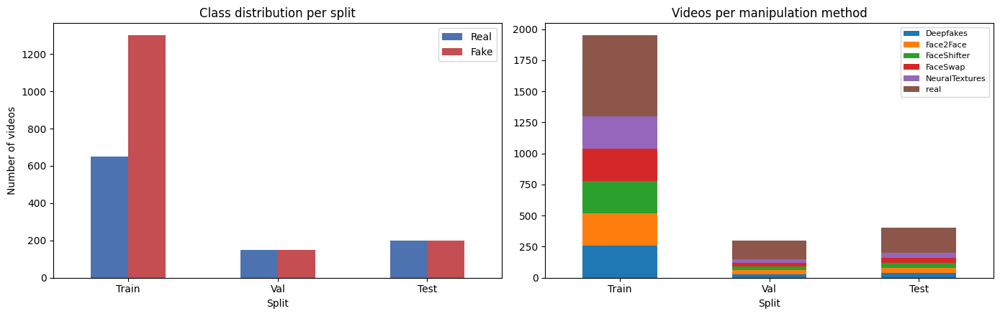


Face-detector statistics over 2650 videos with stored boxes: mean detection rate=0.98, median=1.00, videos below 50% detection=12, centre-crop fallbacks=5


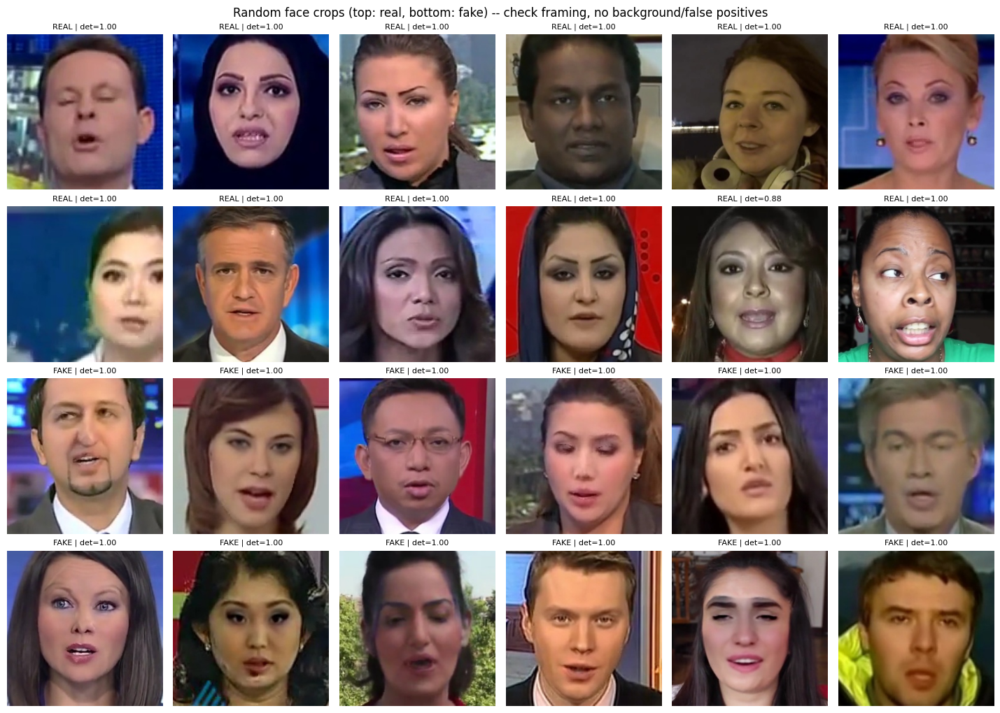

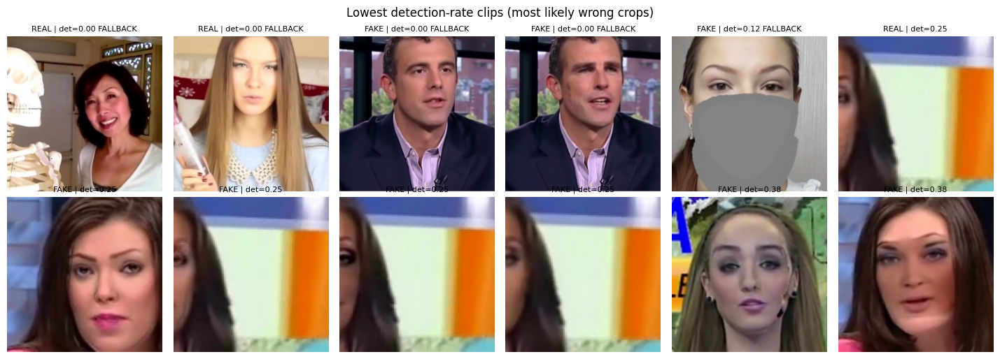

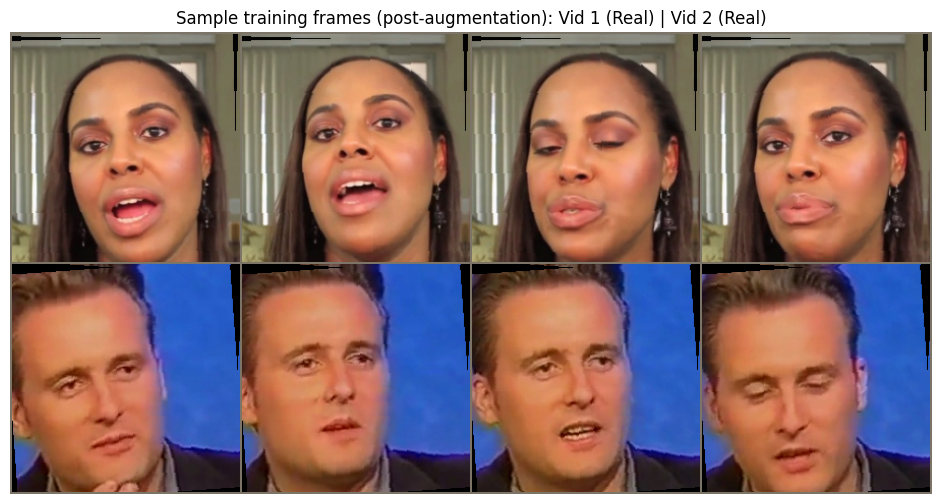


TIP (review item 8): after this run, 'Save Version' and add /kaggle/working/face_frames as a Kaggle dataset; set CONFIG['face_cache_input_dir'] to its path to skip extraction next time.


In [3]:
# ============================================================
# CELL 3: Data distribution analysis and face-crop QA (review item 8)
# ============================================================
# (The v4 sampler demo was removed: on balanced data it compared 0 all-fake batches with 0.)

split_counts = pd.DataFrame([
    {"Split": name,
     "Real": sum(1 for _, l in recs if l == 0),
     "Fake": sum(1 for _, l in recs if l == 1)}
    for name, recs in [("Train", train_records), ("Val", val_records), ("Test", test_records)]
])
print("Class distribution per split:")
print(split_counts.to_string(index=False))

method_rows = []
for name, recs in [("Train", train_records), ("Val", val_records), ("Test", test_records)]:
    cnt = pd.Series([record_info[f]["method"] for f, _ in recs]).value_counts()
    for m, c in cnt.items():
        method_rows.append({"Split": name, "Method": m, "Videos": int(c)})
method_df = pd.DataFrame(method_rows)
print("\nVideos per split and manipulation method:")
print(method_df.pivot(index="Method", columns="Split", values="Videos").fillna(0).astype(int).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
split_counts.set_index("Split")[["Real", "Fake"]].plot(kind="bar", ax=axes[0], color=["#4C72B0", "#C44E52"])
axes[0].set_title("Class distribution per split")
axes[0].set_ylabel("Number of videos")
axes[0].tick_params(axis="x", rotation=0)
method_df.pivot(index="Split", columns="Method", values="Videos").fillna(0).loc[["Train", "Val", "Test"]].plot(
    kind="bar", stacked=True, ax=axes[1])
axes[1].set_title("Videos per manipulation method")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("/kaggle/working/class_distribution_by_split_and_method.png", dpi=150)
plt.show()

# ---- Face-crop quality: detection rates and a visual grid (inspect this before trusting any result) ----
def _box_info(folder):
    return FACE_BOXES.get(Path(folder).name)


infos = [(f, l, _box_info(f)) for f, l in extracted_records]
rates = [i["detect_rate"] for _, _, i in infos if i is not None]
n_fb = sum(1 for _, _, i in infos if i is not None and not i["ok"])
n_unknown = sum(1 for _, _, i in infos if i is None)
if rates:
    print(f"\nFace-detector statistics over {len(rates)} videos with stored boxes: "
          f"mean detection rate={np.mean(rates):.2f}, median={np.median(rates):.2f}, "
          f"videos below 50% detection={sum(r < 0.5 for r in rates)}, centre-crop fallbacks={n_fb}")
if n_unknown:
    print(f"({n_unknown} videos came from a cache without box metadata; they cannot be scored.)")


def _mid_frame(folder):
    files = sorted(Path(folder).glob("*.jpg"))
    return cv2.cvtColor(cv2.imread(str(files[len(files) // 2])), cv2.COLOR_BGR2RGB)


def show_crop_grid(items, title, path, ncols=6):
    nrows = int(math.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.4 * ncols, 2.6 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, (folder, label, info) in zip(axes, items):
        ax.imshow(_mid_frame(folder))
        rate = f"{info['detect_rate']:.2f}" if info else "n/a"
        ax.set_title(f"{'FAKE' if label else 'REAL'} | det={rate}" + ("" if (info is None or info['ok']) else " FALLBACK"),
                     fontsize=8)
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.savefig(path, dpi=130)
    plt.show()


_qa_rng = random.Random(0)
real_items = [x for x in infos if x[1] == 0]
fake_items = [x for x in infos if x[1] == 1]
qa_items = _qa_rng.sample(real_items, min(12, len(real_items))) + _qa_rng.sample(fake_items, min(12, len(fake_items)))
show_crop_grid(qa_items, "Random face crops (top: real, bottom: fake) -- check framing, no background/false positives",
               "/kaggle/working/face_crop_qa_random.png")

scored = sorted([x for x in infos if x[2] is not None], key=lambda x: x[2]["detect_rate"])[:12]
if scored:
    show_crop_grid(scored, "Lowest detection-rate clips (most likely wrong crops)", "/kaggle/working/face_crop_qa_worst.png")

# ---- Sample training frames (post-augmentation) ----
images, labels = next(iter(train_loader))
images_to_show = torch.cat([images[0, :4], images[1, :4]], dim=0)
grid = make_grid(images_to_show, nrow=4)
mean_t = torch.tensor(IMAGENET_MEAN, device=grid.device).view(3, 1, 1)
std_t = torch.tensor(IMAGENET_STD, device=grid.device).view(3, 1, 1)
grid_unnorm = torch.clamp(grid * std_t + mean_t, 0.0, 1.0)
label_mapping = {0: "Real", 1: "Fake"}
titles = f"Vid 1 ({label_mapping[int(labels[0].item())]}) | Vid 2 ({label_mapping[int(labels[1].item())]})"
plt.figure(figsize=(12, 6))
plt.imshow(grid_unnorm.permute(1, 2, 0).cpu().numpy())
plt.title(f"Sample training frames (post-augmentation): {titles}")
plt.axis("off")
plt.show()
print("\nTIP (review item 8): after this run, 'Save Version' and add /kaggle/working/face_frames as a Kaggle "
      "dataset; set CONFIG['face_cache_input_dir'] to its path to skip extraction next time.")


In [4]:
# ============================================================
# CELL 4: Model architecture (unchanged from v4)
# ============================================================
# MAIN model: EfficientNet-B1 (pretrained, frame-level feature extractor) -> 1280 -> Linear
# projection -> 512 -> 2-layer UNIDIRECTIONAL LSTM (hidden=512) -> MEAN pooling -> classifier ->
# 1 logit. The attention-pooling path exists only as an optional switch and is NOT enabled.

class TemporalAttentionPooling(nn.Module):
    """Optional (ablation-only) alternative to mean pooling."""
    def __init__(self, input_dim):
        super().__init__()
        self.attn = nn.Sequential(
            nn.Linear(input_dim, input_dim // 2),
            nn.Tanh(),
            nn.Linear(input_dim // 2, 1),
        )

    def forward(self, x):
        scores = self.attn(x)
        weights = torch.softmax(scores, dim=1)
        pooled = torch.sum(weights * x, dim=1)
        return pooled, weights.squeeze(-1)


class FFPPDeepfakeDetectorV2(nn.Module):
    def __init__(self, lstm_hidden_size=None, num_layers=None, bidirectional=None,
                 dropout=None, use_attention=None):
        super().__init__()
        lstm_hidden_size = lstm_hidden_size or CONFIG["lstm_hidden_size"]
        num_layers = num_layers or CONFIG["lstm_num_layers"]
        bidirectional = CONFIG["lstm_bidirectional"] if bidirectional is None else bidirectional
        dropout = CONFIG["dropout"] if dropout is None else dropout
        use_attention = CONFIG["use_temporal_attention"] if use_attention is None else use_attention

        # ---- EfficientNet-B1 spatial feature extractor (pretrained, unchanged) ----
        weights = EfficientNet_B1_Weights.DEFAULT
        base_model = efficientnet_b1(weights=weights)
        self.feature_extractor = nn.Sequential(*list(base_model.children())[:-1])  # [stages, avgpool]
        self.feature_dim = 1280
        self.dropout_cnn = nn.Dropout(p=dropout)
        self.flatten = nn.Flatten()

        # ---- Projection: 1280 -> 512 ----
        self.projection = nn.Sequential(
            nn.Linear(self.feature_dim, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
        )

        # ---- Temporal model: 2-layer UNIDIRECTIONAL LSTM by default ----
        self.bidirectional = bidirectional
        self.use_attention = use_attention
        self.lstm = nn.LSTM(
            input_size=512,
            hidden_size=lstm_hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=(dropout if num_layers > 1 else 0.0),
        )
        lstm_out_dim = lstm_hidden_size * (2 if bidirectional else 1)

        self.temporal_pool = TemporalAttentionPooling(lstm_out_dim) if use_attention else None

        # ---- Classification head ----
        self.classifier = nn.Sequential(
            nn.Linear(lstm_out_dim, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(256, 1),
        )

        self.last_attention_weights = None

    def forward(self, x, verbose_shape_check=False):
        batch_size, seq_len, c, h, w = x.shape
        assert (c, h, w) == (3, CONFIG["img_size"], CONFIG["img_size"]), (
            f"Expected input channels/H/W = (3,{CONFIG['img_size']},{CONFIG['img_size']}), got {(c, h, w)}"
        )
        if verbose_shape_check:
            print(f"  Input                    : {tuple(x.shape)}")

        x = x.view(batch_size * seq_len, c, h, w)
        if verbose_shape_check:
            print(f"  Reshaped for CNN         : {tuple(x.shape)}")

        features = self.feature_extractor(x)
        features = self.flatten(features)
        if verbose_shape_check:
            print(f"  EfficientNet-B1 output   : {tuple(features.shape)}")
        assert features.shape[1] == self.feature_dim, (
            f"Expected {self.feature_dim}-D EfficientNet-B1 features, got {features.shape[1]}"
        )

        features = self.dropout_cnn(features)
        features = self.projection(features)
        if verbose_shape_check:
            print(f"  After projection (->512) : {tuple(features.shape)}")
        assert features.shape[1] == 512, f"Expected 512-D projected features, got {features.shape[1]}"

        features = features.view(batch_size, seq_len, -1)
        if verbose_shape_check:
            print(f"  Reshaped for LSTM        : {tuple(features.shape)}")

        lstm_out, _ = self.lstm(features)
        if verbose_shape_check:
            print(f"  LSTM output              : {tuple(lstm_out.shape)}")

        if self.use_attention:
            pooled, attn_weights = self.temporal_pool(lstm_out)
            self.last_attention_weights = attn_weights.detach()
        else:
            pooled = torch.mean(lstm_out, dim=1)
            self.last_attention_weights = None
        if verbose_shape_check:
            print(f"  Pooled ({'attention' if self.use_attention else 'mean':<9}) : {tuple(pooled.shape)}")

        out = self.classifier(pooled)
        if verbose_shape_check:
            print(f"  Classifier output        : {tuple(out.shape)}")

        out = out.squeeze(1)
        if verbose_shape_check:
            print(f"  Final logits (per video) : {tuple(out.shape)}")
        return out

    def train(self, mode=True):
        """FIX: model.train() used to put the FROZEN backbone's BatchNorm layers in train
        mode, so their running stats drifted every batch while their weights stayed frozen.
        BN layers with no trainable params are now kept in eval mode."""
        super().train(mode)
        if mode:
            for m in self.feature_extractor.modules():
                if isinstance(m, nn.modules.batchnorm._BatchNorm) and \
                        not any(p.requires_grad for p in m.parameters()):
                    m.eval()
        return self

    # ---- Staged transfer-learning helpers ----
    def freeze_backbone(self):
        for p in self.feature_extractor.parameters():
            p.requires_grad = False

    def unfreeze_last_n_blocks(self, n):
        backbone_blocks = list(self.feature_extractor[0].children())
        for block in backbone_blocks[-n:]:
            for p in block.parameters():
                p.requires_grad = True

    def backbone_param_groups(self, backbone_lr, head_lr):
        backbone_params = [p for p in self.feature_extractor.parameters() if p.requires_grad]
        head_params = (
            list(self.projection.parameters())
            + list(self.lstm.parameters())
            + (list(self.temporal_pool.parameters()) if self.use_attention else [])
            + list(self.classifier.parameters())
        )
        groups = [{"params": head_params, "lr": head_lr}]
        if backbone_params:
            groups.append({"params": backbone_params, "lr": backbone_lr})
        return groups


def build_model(**overrides):
    m = FFPPDeepfakeDetectorV2(**overrides).to(CONFIG["device"])
    m.freeze_backbone()  # backbone starts frozen; run_staged_training unfreezes the last N blocks
    return m


model = build_model()
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Model initialized:")
print(f"  EfficientNet-B1 -> projection(1280->512) -> "
      f"{'Bi' if CONFIG['lstm_bidirectional'] else ''}LSTM(hidden={CONFIG['lstm_hidden_size']}, "
      f"layers={CONFIG['lstm_num_layers']}, bidirectional={CONFIG['lstm_bidirectional']}) -> "
      f"{'attention' if CONFIG['use_temporal_attention'] else 'mean'} pooling -> classifier(256) -> 1 logit")
print(f"  Total params: {total_params:,} | Trainable (Phase 1, backbone frozen): {trainable_params:,}")

print("\nShape verification (dummy forward pass, batch_size=2):")
with torch.no_grad():
    dummy_input = torch.randn(2, CONFIG["seq_len"], 3, CONFIG["img_size"], CONFIG["img_size"],
                               device=CONFIG["device"])
    _ = model(dummy_input, verbose_shape_check=True)
print("Shape verification passed.")


Downloading: "https://download.pytorch.org/models/efficientnet_b1-c27df63c.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b1-c27df63c.pth


100%|██████████| 30.1M/30.1M [00:00<00:00, 108MB/s] 


Model initialized:
  EfficientNet-B1 -> projection(1280->512) -> LSTM(hidden=512, layers=2, bidirectional=False) -> mean pooling -> classifier(256) -> 1 logit
  Total params: 11,503,137 | Trainable (Phase 1, backbone frozen): 4,989,953

Shape verification (dummy forward pass, batch_size=2):
  Input                    : (2, 16, 3, 224, 224)
  Reshaped for CNN         : (32, 3, 224, 224)
  EfficientNet-B1 output   : (32, 1280)
  After projection (->512) : (32, 512)
  Reshaped for LSTM        : (2, 16, 512)
  LSTM output              : (2, 16, 512)
  Pooled (mean     ) : (2, 512)
  Classifier output        : (2, 1)
  Final logits (per video) : (2,)
Shape verification passed.


In [5]:
# ============================================================
# CELL 5: Clean training
# ============================================================
# v6: the clean model now trains on 2 fakes per real (class-balanced sampler) to reduce the overfitting seen in v5.
# Review items 9 + 10: no frozen-backbone phase (it never learned); last blocks unfrozen from the start
# with a linear warm-up and per-step cosine decay; lower peak LR; label smoothing; EMA weight averaging;
# 20 epochs. Checkpoints are selected on validation ROC-AUC of the EMA weights. The adversarially
# fine-tuned model (Cell 11) is initialised FROM this checkpoint -- never trained from scratch.

T_MAIN_START = time.time()
EMPTY_CACHE_EVERY_N_BATCHES = 25

# Plain BCE is used for validation/attacks/ART; label smoothing is used for CLEAN training only.
criterion = nn.BCEWithLogitsLoss()


class SmoothBCEWithLogits(nn.Module):
    def __init__(self, smoothing=0.0):
        super().__init__()
        self.smoothing = smoothing

    def forward(self, logits, targets):
        t = targets * (1.0 - self.smoothing) + 0.5 * self.smoothing
        return Fn.binary_cross_entropy_with_logits(logits, t)


train_criterion = SmoothBCEWithLogits(CONFIG["label_smoothing"])
print(f"Train label distribution -> real={int((train_labels_arr == 0).sum())}, fake={int((train_labels_arr == 1).sum())}  "
      f"| loss: BCE with label smoothing {CONFIG['label_smoothing']} (validation uses plain BCE)")
print(f"Mixed precision (autocast + GradScaler) for training: {'ENABLED (CUDA)' if USE_AMP else 'DISABLED (CPU)'}")


class ModelEMA:
    """Exponential moving average of the weights (and BN statistics). `module` is the averaged model
    that gets validated, checkpointed and later deployed."""
    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.module.lstm.flatten_parameters()
        self.decay = decay
        self.n = 0

    @torch.no_grad()
    def update(self, model):
        self.n += 1
        d = min(self.decay, (1.0 + self.n) / (10.0 + self.n))
        msd = model.state_dict()
        for k, v in self.module.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(msd[k].detach(), alpha=1.0 - d)
            else:
                v.copy_(msd[k])


def build_optimizer(model):
    param_groups = model.backbone_param_groups(
        backbone_lr=CONFIG["backbone_lr"], head_lr=CONFIG["head_lr"]
    )
    return torch.optim.AdamW(param_groups, lr=CONFIG["head_lr"], weight_decay=CONFIG["weight_decay"])


def build_scheduler(optimizer, total_steps, warmup_steps=0, min_ratio=0.02):
    """PER-STEP linear warm-up followed by cosine decay to min_ratio x the peak LR."""
    total_steps = max(int(total_steps), 1)
    warmup_steps = int(warmup_steps)

    def lr_lambda(step):
        if warmup_steps > 0 and step < warmup_steps:
            return max(1e-3, (step + 1) / warmup_steps)
        p = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return min_ratio + (1.0 - min_ratio) * 0.5 * (1.0 + math.cos(math.pi * min(p, 1.0)))

    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


def selection_score(m):
    """Clean checkpoint selection = validation ROC-AUC (threshold-free). The decision threshold is tuned
    afterwards, on calibrated validation probabilities (Cell 8)."""
    return m["roc_auc"]


def bernoulli_kl(p_logits, q_logits):
    """Mean KL( Bernoulli(sigmoid(p_logits)) || Bernoulli(sigmoid(q_logits)) ), computed stably from logits."""
    p = torch.sigmoid(p_logits)
    return (p * (Fn.logsigmoid(p_logits) - Fn.logsigmoid(q_logits)) +
            (1 - p) * (Fn.logsigmoid(-p_logits) - Fn.logsigmoid(-q_logits))).mean()


def train_epoch(model, loader, optimizer, loss_fn, scaler, use_amp, scheduler=None, ema=None,
                adversarial=False, adv_cfg=None, grad_clip_norm=None, desc="Training", max_steps=None):
    """One epoch (optionally capped at `max_steps` batches). If `adversarial`, adversarial examples are generated in
    ATTACK mode (BN/dropout frozen), then ONE train-mode forward runs on the concatenated [clean ; adversarial] batch
    (review item 6), so both losses see the same network.
    adv_cfg: dict(epsilon, ramp_steps, state, loss, attack, steps, mult, clean_w, adv_w, beta).
    loss == "pgd_at": total = clean_w*BCE(clean) + adv_w*BCE(adv)   (adv examples built on the TRUE labels)
    loss == "trades": total = BCE(clean) + beta*KL(p_clean || p_adv) (adv examples maximise that KL, label-free)."""
    model.train()
    run_loss = run_clean = run_adv = 0.0
    n_samples = 0
    all_preds, all_labels = [], []
    n_batches = min(len(loader), max_steps) if max_steps else len(loader)

    for batch_idx, (videos, labels) in enumerate(tqdm(loader, desc=desc, leave=False, total=n_batches)):
        if max_steps and batch_idx >= max_steps:
            break
        videos = videos.to(CONFIG["device"], non_blocking=True)
        labels = labels.to(CONFIG["device"], non_blocking=True)
        bs = videos.size(0)

        if adversarial:
            st = adv_cfg["state"]
            eps_t = adv_cfg["epsilon"] * min(1.0, (st["step"] + 1) / max(1, adv_cfg["ramp_steps"]))
            st["step"] += 1
            adv_videos = generate_training_adversarial(model, videos, labels, eps_t, adv_cfg, use_amp)
            model.train()                                   # explicit: attack helper restored it, but be sure
            inp = torch.cat([videos, adv_videos], dim=0)
        else:
            inp = videos

        optimizer.zero_grad(set_to_none=True)
        ctx = torch.amp.autocast("cuda") if use_amp else nullcontext()
        with ctx:
            logits = model(inp)
        logits = logits.float()
        if adversarial:
            clean_loss = loss_fn(logits[:bs], labels)
            if adv_cfg["loss"] == "trades":
                adv_loss = bernoulli_kl(logits[:bs], logits[bs:])
                loss = clean_loss + adv_cfg["beta"] * adv_loss
            else:
                adv_loss = loss_fn(logits[bs:], labels)
                loss = adv_cfg["clean_w"] * clean_loss + adv_cfg["adv_w"] * adv_loss
        else:
            clean_loss = loss_fn(logits, labels)
            loss = clean_loss

        if use_amp:
            scaler.scale(loss).backward()
            if grad_clip_norm:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip_norm)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            if grad_clip_norm:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip_norm)
            optimizer.step()
        if scheduler is not None:
            scheduler.step()
        if ema is not None:
            ema.update(model)

        run_loss += loss.item() * bs
        run_clean += clean_loss.item() * bs
        if adversarial:
            run_adv += adv_loss.item() * bs
        n_samples += bs
        all_preds.extend(torch.sigmoid(logits[:bs]).detach().float().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

        del logits, loss, clean_loss, inp
        if adversarial:
            del adv_videos, adv_loss
        if (batch_idx + 1) % EMPTY_CACHE_EVERY_N_BATCHES == 0:
            free_cuda_memory()

    preds_bin = (np.array(all_preds) >= 0.5).astype(int)
    metrics = {
        "loss": run_loss / n_samples,
        "clean_loss": run_clean / n_samples,
        "acc": accuracy_score(all_labels, preds_bin),
    }
    if adversarial:
        metrics["adv_loss"] = run_adv / n_samples
    return metrics


def validate_epoch(model, loader, loss_fn, threshold=0.5, use_amp=USE_AMP):
    model.eval()
    all_preds, all_labels = [], []
    running_loss, n = 0.0, 0
    with torch.no_grad():
        for videos, labels in tqdm(loader, desc="Validating", leave=False):
            videos = videos.to(CONFIG["device"], non_blocking=True)
            labels = labels.to(CONFIG["device"], non_blocking=True)
            ctx = torch.amp.autocast("cuda") if use_amp else nullcontext()
            with ctx:
                logits = model(videos)
            loss = loss_fn(logits.float(), labels)
            bs = videos.size(0)
            running_loss += loss.item() * bs
            n += bs
            all_preds.extend(torch.sigmoid(logits.float()).cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    m = compute_metrics(all_labels, all_preds, threshold=threshold)
    m["loss"] = running_loss / n
    return m


def run_staged_training(model, save_path, history_tag="clean"):
    """Optional Phase 1 (backbone frozen; skipped when phase1_epochs=0) -> Phase 2 (last N blocks unfrozen,
    1-epoch warm-up + cosine). Early stopping and checkpointing use validation ROC-AUC of the EMA weights."""
    history = []
    best_val_auc = -1.0
    epochs_without_improvement = 0
    global_epoch = 0
    ema = ModelEMA(model, CONFIG["ema_decay"])
    steps_per_epoch = len(train_loader)

    phases = [
        ("Phase 1 (backbone frozen)", CONFIG["phase1_epochs"], False),
        ("Phase 2 (fine-tuning)", CONFIG["phase2_epochs"], True),
    ]

    for phase_name, n_epochs, do_unfreeze in phases:
        if n_epochs <= 0:
            print(f"{phase_name}: skipped (0 epochs)")
            continue
        if do_unfreeze:
            model.unfreeze_last_n_blocks(CONFIG["unfreeze_last_n_blocks"])

        optimizer = build_optimizer(model)
        warmup_steps = int(CONFIG["warmup_epochs"] * steps_per_epoch) if do_unfreeze else 0
        scheduler = build_scheduler(optimizer, n_epochs * steps_per_epoch, warmup_steps, CONFIG["min_lr_ratio"])
        scaler = torch.amp.GradScaler("cuda") if USE_AMP else None

        trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"\n{'=' * 60}\n{phase_name} -- {n_epochs} epochs -- trainable params: {trainable:,}"
              f"{' -- warm-up ' + str(warmup_steps) + ' steps' if warmup_steps else ''}\n{'=' * 60}")

        for epoch_in_phase in range(n_epochs):
            global_epoch += 1
            t_ep = time.time()
            train_metrics = train_epoch(
                model, train_loader, optimizer, train_criterion, scaler, USE_AMP,
                scheduler=scheduler, ema=ema, grad_clip_norm=CONFIG["grad_clip_norm"],
            )
            val_metrics = validate_epoch(ema.module, val_loader, criterion, threshold=0.5, use_amp=USE_AMP)
            current_lr = optimizer.param_groups[0]["lr"]

            print(f"\nEpoch {global_epoch} ({phase_name}, {epoch_in_phase + 1}/{n_epochs})  [{time.time() - t_ep:.0f}s]")
            print(f"  Train Loss: {train_metrics['loss']:.4f} | Train Acc: {train_metrics['acc']:.4f}")
            print(f"  Val (EMA) Loss: {val_metrics['loss']:.4f} | Acc: {val_metrics['accuracy']:.4f} | "
                  f"F1(macro): {val_metrics['f1']:.4f} | ROC-AUC: {val_metrics['roc_auc']:.4f}")
            print(f"  Learning rate (head): {current_lr:.2e}")

            history.append({
                "epoch": global_epoch, "phase": phase_name, "lr": current_lr,
                **{f"train_{k}": v for k, v in train_metrics.items()},
                **{f"val_{k}": v for k, v in val_metrics.items()},
            })

            if selection_score(val_metrics) > best_val_auc:
                best_val_auc = selection_score(val_metrics)
                epochs_without_improvement = 0
                torch.save({"model_state_dict": ema.module.state_dict(),
                            "val_score": best_val_auc, "epoch": global_epoch, "weights": "ema"}, save_path)
                print(f"  --> Best {history_tag} model saved (val ROC-AUC={best_val_auc:.4f}) -> {save_path}")
            else:
                epochs_without_improvement += 1

            if epochs_without_improvement >= CONFIG["early_stopping_patience"]:
                print(f"  Early stopping triggered ({history_tag}) after {global_epoch} total epochs.")
                del optimizer, scheduler, scaler
                free_cuda_memory()
                return history, best_val_auc

        del optimizer, scheduler, scaler
        free_cuda_memory()

    return history, best_val_auc


def train_clean_model(seed, save_path):
    set_global_seed(seed)
    m = build_model()
    hist, best = run_staged_training(m, save_path, history_tag="clean")
    return m, hist, best


print("=" * 60)
print("CLEAN BASELINE TRAINING (no adversarial examples)")
print("=" * 60)
clean_model, clean_history, clean_best_val_auc = train_clean_model(CONFIG["seed"], CONFIG["save_clean_checkpoint"])
print(f"\nClean baseline training complete. Best validation ROC-AUC (EMA weights): {clean_best_val_auc:.4f}")


Train label distribution -> real=650, fake=1300  | loss: BCE with label smoothing 0.05 (validation uses plain BCE)
Mixed precision (autocast + GradScaler) for training: ENABLED (CUDA)
CLEAN BASELINE TRAINING (no adversarial examples)
Phase 1 (backbone frozen): skipped (0 epochs)

Phase 2 (fine-tuning) -- 16 epochs -- trainable params: 11,394,795 -- warm-up 243 steps



Epoch 1 (Phase 2 (fine-tuning), 1/16)  [186s]
  Train Loss: 0.6825 | Train Acc: 0.5432
  Val (EMA) Loss: 0.6174 | Acc: 0.7167 | F1(macro): 0.7155 | ROC-AUC: 0.7534
  Learning rate (head): 2.00e-04
  --> Best clean model saved (val ROC-AUC=0.7534) -> /kaggle/working/best_clean_model.pth



Epoch 2 (Phase 2 (fine-tuning), 2/16)  [172s]
  Train Loss: 0.5775 | Train Acc: 0.7274
  Val (EMA) Loss: 0.4400 | Acc: 0.8067 | F1(macro): 0.8065 | ROC-AUC: 0.8859
  Learning rate (head): 1.98e-04
  --> Best clean model saved (val ROC-AUC=0.8859) -> /kaggle/working/best_clean_model.pth



Epoch 3 (Phase 2 (fine-tuning), 3/16)  [174s]
  Train Loss: 0.4854 | Train Acc: 0.7855
  Val (EMA) Loss: 0.4251 | Acc: 0.8000 | F1(macro): 0.7997 | ROC-AUC: 0.8900
  Learning rate (head): 1.92e-04
  --> Best clean model saved (val ROC-AUC=0.8900) -> /kaggle/working/best_clean_model.pth



Epoch 4 (Phase 2 (fine-tuning), 4/16)  [171s]
  Train Loss: 0.4414 | Train Acc: 0.8174
  Val (EMA) Loss: 0.4025 | Acc: 0.8267 | F1(macro): 0.8249 | ROC-AUC: 0.9059
  Learning rate (head): 1.81e-04
  --> Best clean model saved (val ROC-AUC=0.9059) -> /kaggle/working/best_clean_model.pth


...


Epoch 8 (Phase 2 (fine-tuning), 8/16)  [175s]
  Train Loss: 0.3187 | Train Acc: 0.8987
  Val (EMA) Loss: 0.3375 | Acc: 0.8667 | F1(macro): 0.8661 | ROC-AUC: 0.9315
  Learning rate (head): 1.12e-04
  --> Best clean model saved (val ROC-AUC=0.9315) -> /kaggle/working/best_clean_model.pth



Epoch 9 (Phase 2 (fine-tuning), 9/16)  [170s]
  Train Loss: 0.3096 | Train Acc: 0.8961
  Val (EMA) Loss: 0.3432 | Acc: 0.8633 | F1(macro): 0.8627 | ROC-AUC: 0.9289
  Learning rate (head): 9.18e-05



Epoch 10 (Phase 2 (fine-tuning), 10/16)  [173s]
  Train Loss: 0.2741 | Train Acc: 0.9126
  Val (EMA) Loss: 0.3398 | Acc: 0.8800 | F1(macro): 0.8797 | ROC-AUC: 0.9314
  Learning rate (head): 7.17e-05



Epoch 11 (Phase 2 (fine-tuning), 11/16)  [171s]
  Train Loss: 0.2723 | Train Acc: 0.9223
  Val (EMA) Loss: 0.3473 | Acc: 0.8800 | F1(macro): 0.8797 | ROC-AUC: 0.9310
  Learning rate (head): 5.30e-05



Epoch 12 (Phase 2 (fine-tuning), 12/16)  [171s]
  Train Loss: 0.2679 | Train Acc: 0.9187
  Val (EMA) Loss: 0.3489 | Acc: 0.8833 | F1(macro): 0.8830 | ROC-AUC: 0.9285
  Learning rate (head): 3.64e-05
  Early stopping triggered (clean) after 12 total epochs.

Clean baseline training complete. Best validation ROC-AUC (EMA weights): 0.9315


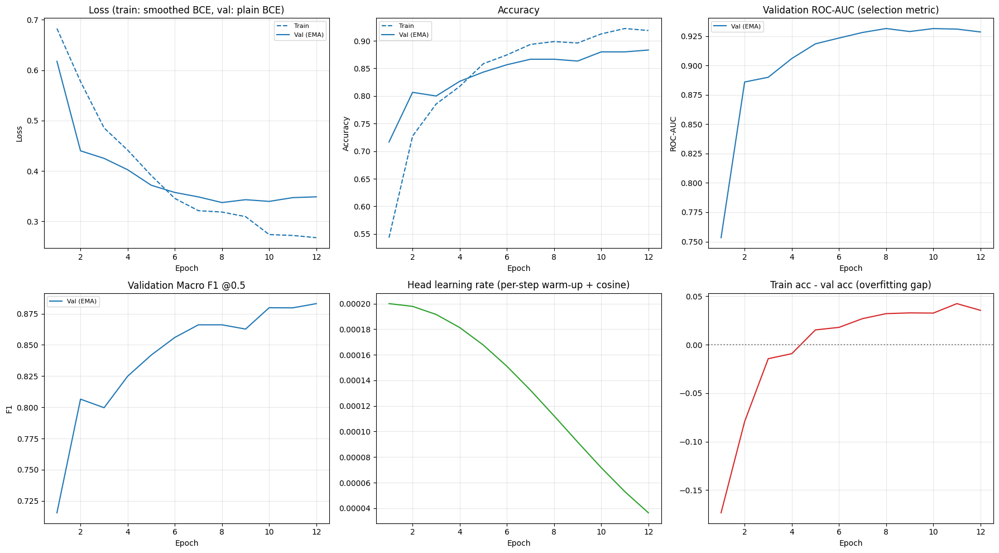

CLEAN MODEL -- BEST VALIDATION EPOCH SUMMARY (EMA weights)
Best epoch: 8  (Phase 2 (fine-tuning)) of 12 run
  Val Loss     : 0.3375
  Val Accuracy : 0.8667
  Val F1(macro): 0.8661
  Val ROC-AUC  : 0.9315

(Consistency check passed: best_row's ROC-AUC matches the value returned by training.)


In [6]:
# ============================================================
# CELL 6: Clean validation curves
# ============================================================
# Training curves for the clean run, plus a summary of the epoch that was actually selected as
# "best" (by validation ROC-AUC of the EMA weights).

clean_df = pd.DataFrame(clean_history)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))


def plot_metric(ax, key_train, key_val, title, ylabel):
    if key_train and key_train in clean_df:
        ax.plot(clean_df["epoch"], clean_df[key_train], "--", label="Train", color="tab:blue")
    if key_val in clean_df:
        ax.plot(clean_df["epoch"], clean_df[key_val], label="Val (EMA)", color="tab:blue")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)


plot_metric(axes[0, 0], "train_loss", "val_loss", "Loss (train: smoothed BCE, val: plain BCE)", "Loss")
plot_metric(axes[0, 1], "train_acc", "val_accuracy", "Accuracy", "Accuracy")
plot_metric(axes[0, 2], None, "val_roc_auc", "Validation ROC-AUC (selection metric)", "ROC-AUC")
plot_metric(axes[1, 0], None, "val_f1", "Validation Macro F1 @0.5", "F1")
axes[1, 1].plot(clean_df["epoch"], clean_df["lr"], color="tab:green")
axes[1, 1].set_title("Head learning rate (per-step warm-up + cosine)")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].grid(alpha=0.3)
axes[1, 2].plot(clean_df["epoch"], clean_df["train_acc"] - clean_df["val_accuracy"], color="tab:red")
axes[1, 2].axhline(0, color="gray", linestyle=":")
axes[1, 2].set_title("Train acc - val acc (overfitting gap)")
axes[1, 2].set_xlabel("Epoch")
axes[1, 2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/clean_training_curves.png", dpi=150)
plt.show()

best_row = clean_df.loc[clean_df["val_roc_auc"].idxmax()]
print("=" * 60)
print("CLEAN MODEL -- BEST VALIDATION EPOCH SUMMARY (EMA weights)")
print("=" * 60)
print(f"Best epoch: {int(best_row['epoch'])}  ({best_row['phase']}) of {int(clean_df['epoch'].max())} run")
print(f"  Val Loss     : {best_row['val_loss']:.4f}")
print(f"  Val Accuracy : {best_row['val_accuracy']:.4f}")
print(f"  Val F1(macro): {best_row['val_f1']:.4f}")
print(f"  Val ROC-AUC  : {best_row['val_roc_auc']:.4f}")
assert abs(best_row["val_roc_auc"] - clean_best_val_auc) < 1e-9, (
    "Mismatch between the best-AUC row found here and the value returned by "
    "run_staged_training -- checkpoint selection logic is inconsistent."
)
print("\n(Consistency check passed: best_row's ROC-AUC matches the value returned by training.)")


In [7]:
# ============================================================
# CELL 7: Best checkpoint loading, prediction helpers, calibration, thresholds
# ============================================================
# The best-validation-ROC-AUC checkpoint is loaded IN PLACE here, before any test-set evaluation.
# The checkpoint stores the EMA weights, so what is evaluated is exactly what was selected.

free_cuda_memory()

clean_checkpoint = torch.load(CONFIG["save_clean_checkpoint"], map_location=CONFIG["device"], weights_only=False)
clean_model.load_state_dict(clean_checkpoint["model_state_dict"])
clean_model.eval()

print(f"Loaded checkpoint from {CONFIG['save_clean_checkpoint']}")
print(f"  Saved at epoch {clean_checkpoint['epoch']} with validation ROC-AUC = {clean_checkpoint['val_score']:.4f}")
assert abs(clean_checkpoint["val_score"] - clean_best_val_auc) < 1e-9, (
    f"Checkpoint's recorded val ROC-AUC ({clean_checkpoint['val_score']:.4f}) does not match "
    f"the best value tracked during training ({clean_best_val_auc:.4f}) -- investigate before evaluating."
)
print("Verified: the model now in memory is the BEST validation checkpoint, not the last epoch's weights.")
last_epoch_in_history = int(clean_df["epoch"].max())
if clean_checkpoint["epoch"] < last_epoch_in_history:
    print(f"(Note: best epoch {clean_checkpoint['epoch']} is earlier than the final epoch {last_epoch_in_history} run -- "
          f"later epochs did not improve validation ROC-AUC.)")


# ---- Prediction helpers (shared by every later cell) ----
def get_logits(model, loader, attack_fn=None, use_amp=None, desc="Evaluating"):
    """Returns (labels, raw logits) in loader order. attack_fn(model, videos, labels)->adv_videos or None.
    Default precision = CONFIG['eval_use_amp'] (False: fp32 for clean passes AND attacks, review item 5)."""
    use_amp = CONFIG["eval_use_amp"] if use_amp is None else use_amp
    model.eval()
    all_logits, all_labels = [], []
    for videos, labels in tqdm(loader, desc=desc, leave=False):
        videos = videos.to(CONFIG["device"], non_blocking=True)
        labels_dev = labels.to(CONFIG["device"], non_blocking=True)
        if attack_fn is not None:
            videos = attack_fn(model, videos, labels_dev)
        with torch.no_grad():
            ctx = torch.amp.autocast("cuda") if (use_amp and CONFIG["device"].type == "cuda") else nullcontext()
            with ctx:
                logits = model(videos)
        all_logits.append(logits.float().cpu().numpy())
        all_labels.append(labels.numpy())
    return np.concatenate(all_labels).astype(int), np.concatenate(all_logits)


def select_threshold(labels, probs):
    """Threshold selection on VALIDATION data only. Returns the EER threshold (FPR = FNR), the macro-F1-optimal
    threshold on a widened grid, and the one selected by CONFIG['threshold_method']."""
    fpr, tpr, thr = roc_curve(labels, probs)
    fnr = 1.0 - tpr
    i = int(np.nanargmin(np.abs(fpr - fnr)))
    eer_thr = float(np.clip(thr[i], 0.0, 1.0))
    grid = np.arange(CONFIG["threshold_search_min"], CONFIG["threshold_search_max"] + 1e-9,
                      CONFIG["threshold_search_step"])
    f1s = [compute_metrics(labels, probs, float(t))["f1"] for t in grid]
    f1_thr = float(grid[int(np.argmax(f1s))])
    selected = eer_thr if CONFIG["threshold_method"] == "eer" else f1_thr
    return {"eer": eer_thr, "f1": f1_thr, "selected": selected,
            "eer_value": float((fpr[i] + fnr[i]) / 2), "grid_edge_hit": bool(f1_thr in (grid[0], grid[-1]))}


def calibrate_and_threshold(model, tag=""):
    """Temperature scaling (review item 10) + threshold (review items 2, 11), both fit on validation only."""
    labels, logits = get_logits(model, val_loader, None, desc=f"val {tag}")
    nll_before = float(Fn.binary_cross_entropy_with_logits(torch.tensor(logits), torch.tensor(labels).float()))
    T = fit_temperature(logits, labels)
    probs = sigmoid_np(logits, T)
    nll_after = float(Fn.binary_cross_entropy_with_logits(torch.tensor(logits / T), torch.tensor(labels).float()))
    ece_before = expected_calibration_error(labels, sigmoid_np(logits, 1.0))
    ece_after = expected_calibration_error(labels, probs)
    thr = select_threshold(labels, probs)
    print(f"[{tag}] temperature T={T:.3f}  val NLL {nll_before:.4f}->{nll_after:.4f}  ECE {ece_before:.4f}->{ece_after:.4f}  "
          f"| threshold EER={thr['eer']:.3f} (EER={thr['eer_value']:.3f})  F1-opt={thr['f1']:.3f}  "
          f"-> using {CONFIG['threshold_method']}={thr['selected']:.3f}")
    if thr["grid_edge_hit"]:
        print(f"  NOTE: the F1-optimal threshold sits on the edge of the search grid -- prefer the threshold-free "
              f"ROC-AUC for comparisons.")
    return T, thr["selected"], thr


print("\nCalibration + threshold for the clean model (validation set only):")
clean_T, clean_selected_threshold, clean_thr_info = calibrate_and_threshold(clean_model, "Clean-trained")


Loaded checkpoint from /kaggle/working/best_clean_model.pth
  Saved at epoch 8 with validation ROC-AUC = 0.9315
Verified: the model now in memory is the BEST validation checkpoint, not the last epoch's weights.
(Note: best epoch 8 is earlier than the final epoch 12 run -- later epochs did not improve validation ROC-AUC.)

Calibration + threshold for the clean model (validation set only):


[Clean-trained] temperature T=1.168  val NLL 0.3387->0.3343  ECE 0.0535->0.0511  | threshold EER=0.369 (EER=0.140)  F1-opt=0.400  -> using eer=0.369



FINAL CLEAN TEST EVALUATION (identity-disjoint test set)
Test videos: 400  (real=200, fake=200)
ROC-AUC (threshold-INDEPENDENT): 0.9456
PR-AUC  (threshold-INDEPENDENT): 0.9505

--- Threshold-DEPENDENT metrics @ 0.5 (default) ---
[Clean test @0.5] thr=0.500  Acc=0.8800  F1(macro)=0.8800  ROC-AUC=0.9456  PR-AUC=0.9505  BalAcc=0.8800  | TP=174 TN=178 FP=22 FN=26

--- Threshold-DEPENDENT metrics @ 0.369 (validation-selected, eer) ---
[Clean test @selected] thr=0.369  Acc=0.8750  F1(macro)=0.8749  ROC-AUC=0.9456  PR-AUC=0.9505  BalAcc=0.8750  | TP=180 TN=170 FP=30 FN=20
  Real -> P=0.8947  R=0.8500  F1=0.8718
  Fake -> P=0.8571  R=0.9000  F1=0.8780

95% intervals: accuracy 0.8750  Wilson [0.8390, 0.9039]  bootstrap [0.8425, 0.9075]   |   ROC-AUC bootstrap [0.9227, 0.9641]
Differences smaller than these intervals (e.g. 1 video out of the test set) are NOT evidence of a real effect.

Classification report @ selected threshold (0.369):
              precision    recall  f1-score   support

  

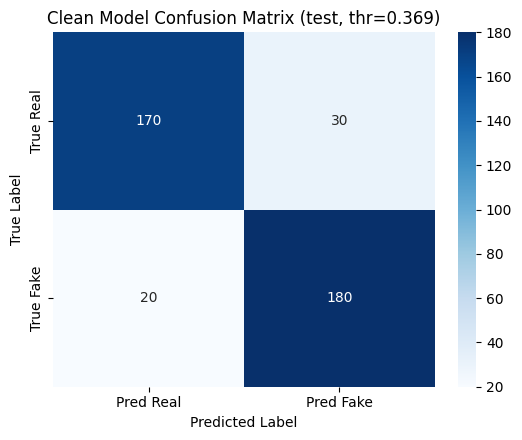


TP=180  TN=170  FP=30  FN=20


In [8]:
# ============================================================
# CELL 8: Final clean test evaluation
# ============================================================
# The threshold and the temperature were chosen on the VALIDATION set only (Cell 7), then frozen and
# applied once to the test set. ROC-AUC is the threshold-free metric; everything else is reported at
# 0.5 and at the selected threshold. Review items 7 and 11: confidence intervals + per-method rates.

def per_method_report(records, labels, probs, threshold):
    """Per manipulation method: videos, detection rate (recall on fakes) / specificity (reals), mean P(fake).
    `records` must be in the same order as the predictions (the loaders never shuffle)."""
    methods = np.array([record_info[f]["method"] for f, _ in records])
    preds = (np.asarray(probs) >= threshold).astype(int)
    rows = []
    for m in sorted(set(methods)):
        idx = methods == m
        is_real = (m == "real")
        correct = (preds[idx] == 0) if is_real else (preds[idx] == 1)
        lo, hi = wilson_ci(int(correct.sum()), int(idx.sum()))
        rows.append({"Method": m, "Videos": int(idx.sum()),
                     "Specificity" if is_real else "Detection rate": float(correct.mean()),
                     "95% CI": f"[{lo:.3f}, {hi:.3f}]", "Mean P(fake)": float(np.mean(probs[idx]))})
    return pd.DataFrame(rows)


# ---- Test predictions: computed ONCE (fp32), reused for every threshold ----
clean_test_labels, clean_test_logits = get_logits(clean_model, test_loader, None, desc="test")
clean_test_probs = sigmoid_np(clean_test_logits, clean_T)

clean_test_metrics_default = compute_metrics(clean_test_labels, clean_test_probs, threshold=0.5)
clean_test_metrics_selected = compute_metrics(clean_test_labels, clean_test_probs, threshold=clean_selected_threshold)

print("\n" + "=" * 60)
print("FINAL CLEAN TEST EVALUATION (identity-disjoint test set)")
print("=" * 60)
print(f"Test videos: {len(clean_test_labels)}  (real={int((clean_test_labels == 0).sum())}, fake={int((clean_test_labels == 1).sum())})")
print(f"ROC-AUC (threshold-INDEPENDENT): {clean_test_metrics_default['roc_auc']:.4f}")
print(f"PR-AUC  (threshold-INDEPENDENT): {clean_test_metrics_default['pr_auc']:.4f}")

print("\n--- Threshold-DEPENDENT metrics @ 0.5 (default) ---")
print_metrics("Clean test @0.5", clean_test_metrics_default)
print(f"\n--- Threshold-DEPENDENT metrics @ {clean_selected_threshold:.3f} (validation-selected, {CONFIG['threshold_method']}) ---")
print_metrics("Clean test @selected", clean_test_metrics_selected)
for cls, key in [("Real", "real"), ("Fake", "fake")]:
    print(f"  {cls} -> P={clean_test_metrics_selected[f'precision_{key}']:.4f}  "
          f"R={clean_test_metrics_selected[f'recall_{key}']:.4f}  F1={clean_test_metrics_selected[f'f1_{key}']:.4f}")

# ---- Confidence intervals (review item 7) ----
n_test = len(clean_test_labels)
k_correct = int(round(clean_test_metrics_selected["accuracy"] * n_test))
w_lo, w_hi = wilson_ci(k_correct, n_test)
boot = bootstrap_ci(clean_test_labels, clean_test_probs, clean_selected_threshold, seed=CONFIG["seed"])
print(f"\n95% intervals: accuracy {clean_test_metrics_selected['accuracy']:.4f}  Wilson [{w_lo:.4f}, {w_hi:.4f}]  "
      f"bootstrap [{boot['acc'][0]:.4f}, {boot['acc'][1]:.4f}]   |   ROC-AUC bootstrap [{boot['auc'][0]:.4f}, {boot['auc'][1]:.4f}]")
print("Differences smaller than these intervals (e.g. 1 video out of the test set) are NOT evidence of a real effect.")

preds_selected = (clean_test_probs >= clean_selected_threshold).astype(int)
print(f"\nClassification report @ selected threshold ({clean_selected_threshold:.3f}):")
print(classification_report(clean_test_labels, preds_selected, target_names=["Real", "Fake"]))

# ---- Per-manipulation-method breakdown (review item 11) ----
print("Per-method breakdown (clean model, test set, validation-selected threshold):")
clean_method_df = per_method_report(test_records, clean_test_labels, clean_test_probs, clean_selected_threshold)
print(clean_method_df.to_string(index=False))

cm = confusion_matrix(clean_test_labels, preds_selected, labels=[0, 1])
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred Real', 'Pred Fake'], yticklabels=['True Real', 'True Fake'])
plt.title(f"Clean Model Confusion Matrix (test, thr={clean_selected_threshold:.3f})")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.tight_layout()
plt.savefig("/kaggle/working/clean_confusion_matrix.png", dpi=150)
plt.show()
print(f"\nTP={clean_test_metrics_selected['tp']}  TN={clean_test_metrics_selected['tn']}  "
      f"FP={clean_test_metrics_selected['fp']}  FN={clean_test_metrics_selected['fn']}")


In [9]:
# ============================================================
# CELL 9: Attack library (FGSM / PGD / margin-loss best-iterate PGD)
# ============================================================
# Attacks operate on the complete [B, T, C, H, W] ImageNet-normalised video tensor and perturb every frame.
# Pixel-space epsilon/alpha are converted per channel with the ImageNet std. Review items addressed here:
#   4  PGD with random start, configurable steps / alpha / RESTARTS (worst case per video is kept);
#   5  evaluation attacks run in fp32 (use_amp=False); a per-sample ZERO-GRADIENT counter is kept, and the
#      attack loss carries a tiny logit-margin term so a saturated sigmoid can never give a zero gradient;
#   6  perturbed pixels are clamped to the valid image range; BN/dropout are frozen while attacking
#      (cuDNN's RNN backward still needs the LSTM in train() mode, with its dropout switched off).

_ATTACK_IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 1, 3, 1, 1)
_ATTACK_IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 1, 3, 1, 1)

ATTACK_DIAG = {"samples": 0, "zero_grad_samples": 0}


def reset_attack_diag():
    ATTACK_DIAG["samples"] = 0
    ATTACK_DIAG["zero_grad_samples"] = 0


def _prepare_model_for_attack(model):
    """BatchNorm/Dropout -> eval mode (frozen running stats, deterministic) while any RNN submodule stays in
    train() mode with dropout disabled (cuDNN RNN backward only exists in training mode). Returns the previous
    per-module training flags so they can be restored exactly."""
    prev_modes = {m: m.training for m in model.modules()}
    model.eval()
    for m in model.modules():
        if isinstance(m, (nn.LSTM, nn.GRU, nn.RNN)):
            m.train()
            m._stored_dropout = m.dropout
            m.dropout = 0.0
    return prev_modes


def _restore_model_modes(model, prev_modes):
    for m in model.modules():
        if m in prev_modes:
            m.train(prev_modes[m])
        if isinstance(m, (nn.LSTM, nn.GRU, nn.RNN)) and hasattr(m, '_stored_dropout'):
            m.dropout = m._stored_dropout
            del m._stored_dropout


def _get_norm_bounds(device):
    mean = _ATTACK_IMAGENET_MEAN.to(device)
    std = _ATTACK_IMAGENET_STD.to(device)
    return (0.0 - mean) / std, (1.0 - mean) / std      # normalised values of pixel 0 and pixel 1


def _epsilon_to_normalized(epsilon_pixel, device):
    return epsilon_pixel / _ATTACK_IMAGENET_STD.to(device)


def _input_grad(model, x, labels, use_amp, loss_type="bce", target_logits=None):
    """Gradient w.r.t. the input of an attack objective (mean over the batch). Returns (grad, per-sample margin) where
    margin = (1-2y)*logit is large when the model is WRONG (used for best-iterate tracking).
      loss_type "bce"   : BCE(logits, y) + 1e-3*margin  (tiny margin term: a saturated sigmoid never gives zero gradient)
      loss_type "margin": margin itself -- cannot saturate (the check against gradient masking by a flat BCE loss)
      loss_type "kl"    : KL(clean || adv) against `target_logits` (TRADES inner maximisation; label-free)
    use_amp=True only for the (cheaper) attacks inside training."""
    x = x.detach().clone().requires_grad_(True)
    y = labels.float()
    ctx = torch.amp.autocast("cuda") if use_amp else nullcontext()
    with ctx:
        logits = model(x)
    logits = logits.float()
    margin = (1.0 - 2.0 * y) * logits
    if loss_type == "margin":
        loss = margin.mean()
    elif loss_type == "kl":
        loss = bernoulli_kl(target_logits.float(), logits)
    else:
        loss = (Fn.binary_cross_entropy_with_logits(logits, y, reduction="none") + 1e-3 * margin).mean()
    if use_amp:
        scaler = torch.amp.GradScaler("cuda", init_scale=4096.0)      # avoids fp16 underflow of tiny gradients
        grad = torch.autograd.grad(scaler.scale(loss), x)[0] / scaler.get_scale()
    else:
        grad = torch.autograd.grad(loss, x)[0]
    grad = torch.nan_to_num(grad, nan=0.0, posinf=1.0, neginf=-1.0)
    zero = (grad.flatten(1).abs().amax(dim=1) == 0)
    ATTACK_DIAG["samples"] += int(grad.size(0))
    ATTACK_DIAG["zero_grad_samples"] += int(zero.sum().item())
    return grad.detach(), margin.detach()


def _project(x_adv, x0, eps_n, vmin, vmax):
    x_adv = x0 + torch.max(torch.min(x_adv - x0, eps_n), -eps_n)      # epsilon ball around the clean input
    return torch.max(torch.min(x_adv, vmax), vmin)                    # valid pixel range


def fgsm_attack(model, videos, labels, epsilon, criterion=None, use_amp=None, random_start=False, step_size=None):
    """FGSM. With random_start=True it is 'FGSM-RS': uniform random start in the epsilon ball, one step of
    size `step_size` (default 1.25*epsilon), projected back. `criterion` is accepted for backward
    compatibility and ignored (attacks always use plain BCE on the TRUE labels)."""
    device = videos.device
    use_amp = USE_AMP if use_amp is None else use_amp
    prev_modes = _prepare_model_for_attack(model)
    try:
        eps_n = _epsilon_to_normalized(epsilon, device)
        vmin, vmax = _get_norm_bounds(device)
        x0 = videos.detach()
        if random_start:
            x = torch.max(torch.min(x0 + (torch.rand_like(x0) * 2 - 1) * eps_n, vmax), vmin)
            step_n = _epsilon_to_normalized(step_size if step_size is not None else 1.25 * epsilon, device)
        else:
            x = x0.clone()
            step_n = eps_n
        grad, _ = _input_grad(model, x, labels, use_amp)
        with torch.no_grad():
            x_adv = _project(x + step_n * grad.sign(), x0, eps_n, vmin, vmax)
    finally:
        model.zero_grad(set_to_none=True)
        _restore_model_modes(model, prev_modes)
    return x_adv.detach()


def _pgd_once(model, x0, labels, eps_n, alpha_n, steps, vmin, vmax, random_start, use_amp, loss_type="bce",
              target_logits=None):
    if random_start:
        x_adv = torch.max(torch.min(x0 + (torch.rand_like(x0) * 2 - 1) * eps_n, vmax), vmin)
    else:
        x_adv = x0.clone()
    for _ in range(steps):
        grad, _ = _input_grad(model, x_adv, labels, use_amp, loss_type, target_logits)
        with torch.no_grad():
            x_adv = _project(x_adv + alpha_n * grad.sign(), x0, eps_n, vmin, vmax)
    return x_adv.detach()


def pgd_attack(model, videos, labels, epsilon, alpha, steps, criterion=None, random_start=True,
               use_amp=None, restarts=1, loss_type="bce", target_logits=None):
    """L-inf PGD over the complete video tensor. With restarts > 1 every restart uses a fresh random start and
    the adversarial example with the highest per-video loss is kept (worst case over restarts)."""
    device = videos.device
    use_amp = USE_AMP if use_amp is None else use_amp
    prev_modes = _prepare_model_for_attack(model)
    try:
        eps_n = _epsilon_to_normalized(epsilon, device)
        alpha_n = _epsilon_to_normalized(alpha, device)
        vmin, vmax = _get_norm_bounds(device)
        x0 = videos.detach().clone()
        best_adv, best_loss = None, None
        for r in range(max(1, restarts)):
            x_adv = _pgd_once(model, x0, labels, eps_n, alpha_n, steps, vmin, vmax,
                              random_start or r > 0, use_amp, loss_type, target_logits)
            if restarts <= 1:
                best_adv = x_adv
                break
            with torch.no_grad():
                per_loss = Fn.binary_cross_entropy_with_logits(model(x_adv).float(), labels.float(), reduction="none")
            if best_adv is None:
                best_adv, best_loss = x_adv, per_loss
            else:
                better = per_loss > best_loss
                best_adv = torch.where(better.view(-1, 1, 1, 1, 1), x_adv, best_adv)
                best_loss = torch.where(better, per_loss, best_loss)
    finally:
        model.zero_grad(set_to_none=True)
        _restore_model_modes(model, prev_modes)
    return best_adv.detach()


def best_margin_attack(model, videos, labels, epsilon, steps=25, momentum=0.75, use_amp=False):
    """Stronger evaluation attack (APGD-inspired; NOT the official AutoAttack): L-inf PGD on the logit-MARGIN loss with
    gradient momentum, a cosine step-size decay from 2*eps, a random start, and BEST-ITERATE tracking -- for each
    video the most adversarial point visited (largest margin (1-2y)*logit) is returned, so a late oscillation cannot
    make the attack look weaker. Costs `steps` gradient passes (+1 forward)."""
    device = videos.device
    prev_modes = _prepare_model_for_attack(model)
    try:
        eps_n = _epsilon_to_normalized(epsilon, device)
        vmin, vmax = _get_norm_bounds(device)
        x0 = videos.detach().clone()
        x = torch.max(torch.min(x0 + (torch.rand_like(x0) * 2 - 1) * eps_n, vmax), vmin)
        v = torch.zeros_like(x0)
        best_x = x.clone()
        best_m = torch.full((x0.size(0),), -float("inf"), device=device)
        for t in range(steps):
            grad, m = _input_grad(model, x, labels, use_amp, loss_type="margin")
            better = m > best_m
            best_m = torch.where(better, m, best_m)
            best_x = torch.where(better.view(-1, 1, 1, 1, 1), x, best_x)
            g = grad / (grad.abs().flatten(1).mean(dim=1).view(-1, 1, 1, 1, 1) + 1e-12)
            v = momentum * v + g
            lr_t = 2.0 * (0.02 + 0.98 * 0.5 * (1.0 + math.cos(math.pi * t / steps)))     # in units of eps
            with torch.no_grad():
                x = _project(x + lr_t * eps_n * v.sign(), x0, eps_n, vmin, vmax)
        with torch.no_grad():                                   # the final iterate also competes
            z = model(x).float()
            m = (1.0 - 2.0 * labels.float()) * z
            better = m > best_m
            best_x = torch.where(better.view(-1, 1, 1, 1, 1), x, best_x)
    finally:
        model.zero_grad(set_to_none=True)
        _restore_model_modes(model, prev_modes)
    return best_x.detach()


def generate_training_adversarial(model, videos, labels, eps, cfg, use_amp):
    """Adversarial examples for ART. pgd_at: PGD (random start) or FGSM-RS on the TRUE labels. trades: PGD that
    maximises KL(clean || adv) from a tiny random start (needs no labels, so it cannot leak them)."""
    if cfg["loss"] == "trades":
        prev = _prepare_model_for_attack(model)
        try:
            with torch.no_grad():
                ctx = torch.amp.autocast("cuda") if use_amp else nullcontext()
                with ctx:
                    clean_logits = model(videos).float()
        finally:
            _restore_model_modes(model, prev)
        alpha = cfg["mult"] * eps / cfg["steps"]
        return pgd_attack(model, videos + 0.0, labels, epsilon=eps, alpha=alpha, steps=cfg["steps"], random_start=True,
                          use_amp=use_amp, loss_type="kl", target_logits=clean_logits)
    if cfg["attack"] == "pgd":
        alpha = cfg["mult"] * eps / cfg["steps"]
        return pgd_attack(model, videos, labels, epsilon=eps, alpha=alpha, steps=cfg["steps"],
                          random_start=True, use_amp=use_amp)
    return fgsm_attack(model, videos, labels, epsilon=eps, random_start=True, step_size=1.25 * eps, use_amp=use_amp)


def make_conditions(fgsm_eps, pgd_cfgs, margin_cfgs=()):
    """[(name, attack_fn)] for the evaluation tables. All fp32 (use_amp=False)."""
    conds = []
    for eps in fgsm_eps:
        conds.append((f"FGSM {round(eps * 255)}/255",
                      lambda m, v, l, eps=eps: fgsm_attack(m, v, l, epsilon=eps, use_amp=False)))
    for name, eps, steps, restarts in pgd_cfgs:
        alpha = CONFIG["pgd_step_mult"] * eps / steps
        conds.append((f"{name} {round(eps * 255)}/255 (r{restarts})",
                      lambda m, v, l, eps=eps, alpha=alpha, steps=steps, restarts=restarts: pgd_attack(
                          m, v, l, epsilon=eps, alpha=alpha, steps=steps, restarts=restarts,
                          random_start=True, use_amp=False)))
    for eps, steps in margin_cfgs:
        conds.append((f"BestMargin-{steps} {round(eps * 255)}/255",
                      lambda m, v, l, eps=eps, steps=steps: best_margin_attack(m, v, l, epsilon=eps, steps=steps,
                                                                              use_amp=False)))
    return conds


print("Attack library ready: fgsm_attack, pgd_attack (BCE / margin / KL loss, restarts), best_margin_attack "
      "(momentum + step decay + best iterate); all clamp to the valid pixel range; evaluation attacks run in fp32.")


Attack library ready: fgsm_attack, pgd_attack (BCE / margin / KL loss, restarts), best_margin_attack (momentum + step decay + best iterate); all clamp to the valid pixel range; evaluation attacks run in fp32.


ATTACK UNIT CHECKS (clean model, fp32)
epsilon=0 identity check passed.
  FGSM               eps=2/255: L-inf=2.000/255 (bound 2.000)  valid-pixel-range=OK  loss 0.101->3.841
  PGD-5              eps=2/255: L-inf=2.000/255 (bound 2.000)  valid-pixel-range=OK  loss 0.101->4.046
  PGD-5 x2 restarts  eps=2/255: L-inf=2.000/255 (bound 2.000)  valid-pixel-range=OK  loss 0.101->4.045
  FGSM               eps=4/255: L-inf=4.000/255 (bound 4.000)  valid-pixel-range=OK  loss 0.101->3.504
  PGD-5              eps=4/255: L-inf=4.000/255 (bound 4.000)  valid-pixel-range=OK  loss 0.101->4.040
  PGD-5 x2 restarts  eps=4/255: L-inf=4.000/255 (bound 4.000)  valid-pixel-range=OK  loss 0.101->4.040
Zero-gradient samples so far: 0 / 140

Fine epsilon sweep (clean model, validation subset of 64 videos, fp32). FGSM on the full grid; PGD-5 on a coarser grid.


attack    FGSM  PGD-5
eps_255              
0.0      0.891  0.891
0.5      0.000    NaN
1.0      0.000  0.000
1.5      0.000    NaN
2.0      0.000  0.000
3.0      0.000    NaN
4.0      0.000  0.000
6.0      0.016    NaN
8.0      0.109  0.000
12.0     0.234    NaN
16.0     0.281    NaN


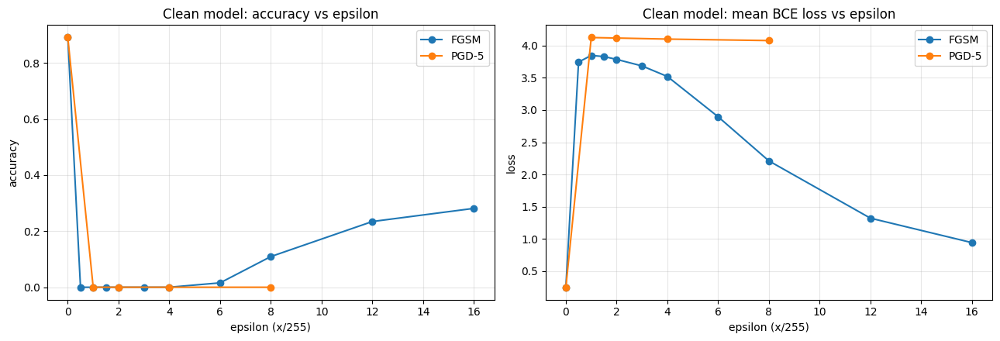


Interpretation:
  FGSM accuracy is non-monotonic in epsilon, but PGD (the stronger attack) is monotonic and at least as strong at every shared epsilon. This is the known single-step overshoot of FGSM at large epsilon (the linearisation stops being valid), NOT an implementation bug. FGSM is therefore never used alone to claim robustness.
Zero-gradient samples: 0 / 2060


In [10]:
# ============================================================
# CELL 10: Attack sanity checks + fine epsilon sweep (review item 15)
# ============================================================
# Verifies (on the CLEAN model, VALIDATION subset only, fp32): epsilon=0 is a no-op, perturbations stay inside
# the epsilon ball and the valid pixel range, gradients are non-zero for every sample, and the loss rises.
# Then sweeps epsilon on a finer grid for FGSM and PGD (accuracy AND loss) and explains the non-monotonic
# FGSM curve that triggered the v4 warning (single-step overshoot) by checking it against PGD.

reset_attack_diag()
std_t5 = torch.tensor(IMAGENET_STD, device=CONFIG["device"]).view(1, 1, 3, 1, 1)
mean_t5 = torch.tensor(IMAGENET_MEAN, device=CONFIG["device"]).view(1, 1, 3, 1, 1)

sv, sl = next(iter(sanity_loader))
sv, sl = sv.to(CONFIG["device"]), sl.to(CONFIG["device"])
clean_model.eval()

print("=" * 60)
print("ATTACK UNIT CHECKS (clean model, fp32)")
print("=" * 60)
# 1) epsilon = 0 -> identity
adv0 = pgd_attack(clean_model, sv, sl, epsilon=0.0, alpha=1 / 255, steps=3, random_start=False, use_amp=False)
assert (adv0 - sv).abs().max().item() < 1e-5, "PGD at epsilon=0 must not move the input"
print("epsilon=0 identity check passed.")

for eps in (2 / 255, 4 / 255):
    for label, adv in [("FGSM", fgsm_attack(clean_model, sv, sl, eps, use_amp=False)),
                       ("PGD-5", pgd_attack(clean_model, sv, sl, eps, CONFIG["pgd_step_mult"] * eps / 5, 5, use_amp=False)),
                       ("PGD-5 x2 restarts", pgd_attack(clean_model, sv, sl, eps, CONFIG["pgd_step_mult"] * eps / 5, 5,
                                                         use_amp=False, restarts=2))]:
        linf = ((adv - sv) * std_t5).abs().max().item()
        pix = adv * std_t5 + mean_t5
        in_range = bool((pix.min() >= -1e-5) and (pix.max() <= 1 + 1e-5))
        with torch.no_grad():
            l_clean = Fn.binary_cross_entropy_with_logits(clean_model(sv).float(), sl.float()).item()
            l_adv = Fn.binary_cross_entropy_with_logits(clean_model(adv).float(), sl.float()).item()
        print(f"  {label:<18} eps={eps * 255:.0f}/255: L-inf={linf * 255:.3f}/255 (bound {eps * 255:.3f})  "
              f"valid-pixel-range={'OK' if in_range else 'VIOLATION'}  loss {l_clean:.3f}->{l_adv:.3f}")
        assert linf <= eps + 1e-5 and in_range, "Attack violated its epsilon ball or the valid pixel range"
print(f"Zero-gradient samples so far: {ATTACK_DIAG['zero_grad_samples']} / {ATTACK_DIAG['samples']}")
assert ATTACK_DIAG["zero_grad_samples"] == 0, "Some samples received an all-zero input gradient -- attacks would be too weak"


# ---- Fine epsilon sweep on the validation subset ----
def _acc_loss(labels, logits):
    acc = float(np.mean((logits >= 0.0).astype(int) == labels))        # threshold 0.5 on probability == logit >= 0
    loss = float(Fn.binary_cross_entropy_with_logits(torch.tensor(logits), torch.tensor(labels).float()))
    return acc, loss


rows = []
print("\nFine epsilon sweep (clean model, validation subset of "
      f"{len(sanity_records)} videos, fp32). FGSM on the full grid; PGD-{CONFIG['sanity_pgd_steps']} on a coarser grid.")
for eps in CONFIG["sanity_fgsm_eps_grid"]:
    if eps == 0:
        l_, z_ = get_logits(clean_model, sanity_loader, None, desc="eps=0")
    else:
        l_, z_ = get_logits(clean_model, sanity_loader,
                            lambda m, v, l, eps=eps: fgsm_attack(m, v, l, epsilon=eps, use_amp=False), desc=f"FGSM {eps * 255:.1f}")
    a, lo = _acc_loss(l_, z_)
    rows.append({"attack": "FGSM", "eps_255": eps * 255, "accuracy": a, "loss": lo})
for eps in [0.0] + CONFIG["sanity_pgd_eps"]:
    if eps == 0:
        l_, z_ = get_logits(clean_model, sanity_loader, None, desc="eps=0")
    else:
        st = CONFIG["sanity_pgd_steps"]
        l_, z_ = get_logits(clean_model, sanity_loader,
                            lambda m, v, l, eps=eps, st=st: pgd_attack(m, v, l, eps, CONFIG["pgd_step_mult"] * eps / st, st,
                                                                       use_amp=False), desc=f"PGD {eps * 255:.1f}")
    a, lo = _acc_loss(l_, z_)
    rows.append({"attack": f"PGD-{CONFIG['sanity_pgd_steps']}", "eps_255": eps * 255, "accuracy": a, "loss": lo})

sweep_df = pd.DataFrame(rows)
print(sweep_df.pivot(index="eps_255", columns="attack", values="accuracy").round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, g in sweep_df.groupby("attack"):
    g = g.sort_values("eps_255")
    axes[0].plot(g["eps_255"], g["accuracy"], marker="o", label=name)
    axes[1].plot(g["eps_255"], g["loss"], marker="o", label=name)
axes[0].set_title("Clean model: accuracy vs epsilon")
axes[1].set_title("Clean model: mean BCE loss vs epsilon")
for ax in axes:
    ax.set_xlabel("epsilon (x/255)")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("accuracy")
axes[1].set_ylabel("loss")
plt.tight_layout()
plt.savefig("/kaggle/working/fgsm_pgd_epsilon_sweep.png", dpi=150)
plt.show()

fg = sweep_df[sweep_df["attack"] == "FGSM"].sort_values("eps_255").reset_index(drop=True)
pg = sweep_df[sweep_df["attack"].str.startswith("PGD")].sort_values("eps_255").reset_index(drop=True)
fgsm_nonmono = any(fg["accuracy"].iloc[i + 1] > fg["accuracy"].iloc[i] + 0.05 for i in range(len(fg) - 1))
pgd_mono = all(pg["accuracy"].iloc[i + 1] <= pg["accuracy"].iloc[i] + 0.05 for i in range(len(pg) - 1))
merged = pg.merge(fg, on="eps_255", suffixes=("_pgd", "_fgsm"))
pgd_stronger = bool((merged["accuracy_pgd"] <= merged["accuracy_fgsm"] + 0.05).all()) if len(merged) else True

print("\nInterpretation:")
if fgsm_nonmono and pgd_mono and pgd_stronger:
    print("  FGSM accuracy is non-monotonic in epsilon, but PGD (the stronger attack) is monotonic and at least as strong "
          "at every shared epsilon. This is the known single-step overshoot of FGSM at large epsilon (the linearisation "
          "stops being valid), NOT an implementation bug. FGSM is therefore never used alone to claim robustness.")
elif not fgsm_nonmono:
    print("  FGSM accuracy decreases monotonically with epsilon -- nothing to explain.")
else:
    print("  WARNING: FGSM is non-monotonic AND PGD is not cleanly monotonic / stronger. Investigate the attack "
          "implementation before trusting any robustness number.")
print(f"Zero-gradient samples: {ATTACK_DIAG['zero_grad_samples']} / {ATTACK_DIAG['samples']}")


Using clean_w=0.5, adv_w=0.5 (v6 default 0.5/0.5; v5's 0.7/0.3 let the model hedge).

ART fine-tune (pgd_at): loss=pgd_at eps=2.0/255 attack=PGD-5 clean_w=0.5 adv_w=0.5  epochs=14 x 350 batches (eps ramp 2.0 epochs)



Epoch 1/14  [659s, train 448s]  elapsed ART 11 min
  Train: total=0.8895 clean=0.4045 adv=1.3744 acc(clean part)=0.9293
  Val (EMA, 200 videos, fp32 attacks eps=2/255): clean acc=0.840 AUC=0.885 | FGSM acc=0.505 | PGD-10 acc=0.210 AUC=0.080 | selection score=0.4021
  --> Best ART fine-tune (pgd_at) model saved (selection score=0.4021) -> /kaggle/working/best_art_model.pth



Epoch 2/14  [656s, train 445s]  elapsed ART 22 min
  Train: total=0.5692 clean=0.3742 adv=0.7641 acc(clean part)=0.8821
  Val (EMA, 200 videos, fp32 attacks eps=2/255): clean acc=0.875 AUC=0.904 | FGSM acc=0.400 | PGD-10 acc=0.120 AUC=0.044 | selection score=0.3883



Epoch 3/14  [654s, train 443s]  elapsed ART 33 min
  Train: total=0.5042 clean=0.3040 adv=0.7044 acc(clean part)=0.8764
  Val (EMA, 200 videos, fp32 attacks eps=2/255): clean acc=0.845 AUC=0.912 | FGSM acc=0.500 | PGD-10 acc=0.320 AUC=0.020 | selection score=0.3771
  !! HEDGING WARNING: adversarial training loss is ~ln 2 (0.693): the model outputs ~0.5 on adversarial inputs instead of resisting them. Consider CONFIG['art_loss']='trades' or a smaller epsilon.



Epoch 4/14  [651s, train 442s]  elapsed ART 44 min
  Train: total=0.5038 clean=0.3041 adv=0.7036 acc(clean part)=0.8771
  Val (EMA, 200 videos, fp32 attacks eps=2/255): clean acc=0.845 AUC=0.909 | FGSM acc=0.505 | PGD-10 acc=0.260 AUC=0.033 | selection score=0.3834
  !! HEDGING WARNING: adversarial training loss is ~ln 2 (0.693): the model outputs ~0.5 on adversarial inputs instead of resisting them. Consider CONFIG['art_loss']='trades' or a smaller epsilon.


...


Epoch 10/14  [653s, train 443s]  elapsed ART 109 min
  Train: total=0.4548 clean=0.2137 adv=0.6959 acc(clean part)=0.9143
  Val (EMA, 200 videos, fp32 attacks eps=2/255): clean acc=0.860 AUC=0.928 | FGSM acc=0.500 | PGD-10 acc=0.260 AUC=0.122 | selection score=0.4442
  !! HEDGING WARNING: adversarial training loss is ~ln 2 (0.693): the model outputs ~0.5 on adversarial inputs instead of resisting them. Consider CONFIG['art_loss']='trades' or a smaller epsilon.



Epoch 11/14  [655s, train 444s]  elapsed ART 120 min
  Train: total=0.4645 clean=0.2277 adv=0.7012 acc(clean part)=0.9114
  Val (EMA, 200 videos, fp32 attacks eps=2/255): clean acc=0.860 AUC=0.929 | FGSM acc=0.570 | PGD-10 acc=0.230 AUC=0.093 | selection score=0.4275
  !! LABEL-LEAK WARNING: FGSM accuracy exceeds clean accuracy (or is >30 points above PGD). The model is probably learning to detect the attack, not resisting it.
  !! HEDGING WARNING: adversarial training loss is ~ln 2 (0.693): the model outputs ~0.5 on adversarial inputs instead of resisting them. Consider CONFIG['art_loss']='trades' or a smaller epsilon.



Epoch 12/14  [655s, train 445s]  elapsed ART 131 min
  Train: total=0.4657 clean=0.2377 adv=0.6937 acc(clean part)=0.9014
  Val (EMA, 200 videos, fp32 attacks eps=2/255): clean acc=0.860 AUC=0.930 | FGSM acc=0.530 | PGD-10 acc=0.305 AUC=0.142 | selection score=0.4572
  !! HEDGING WARNING: adversarial training loss is ~ln 2 (0.693): the model outputs ~0.5 on adversarial inputs instead of resisting them. Consider CONFIG['art_loss']='trades' or a smaller epsilon.



Epoch 13/14  [655s, train 443s]  elapsed ART 142 min
  Train: total=0.4540 clean=0.2153 adv=0.6926 acc(clean part)=0.9157
  Val (EMA, 200 videos, fp32 attacks eps=2/255): clean acc=0.855 AUC=0.930 | FGSM acc=0.530 | PGD-10 acc=0.315 AUC=0.134 | selection score=0.4525
  !! HEDGING WARNING: adversarial training loss is ~ln 2 (0.693): the model outputs ~0.5 on adversarial inputs instead of resisting them. Consider CONFIG['art_loss']='trades' or a smaller epsilon.



Epoch 14/14  [653s, train 443s]  elapsed ART 153 min
  Train: total=0.4654 clean=0.2335 adv=0.6974 acc(clean part)=0.9036
  Val (EMA, 200 videos, fp32 attacks eps=2/255): clean acc=0.855 AUC=0.930 | FGSM acc=0.525 | PGD-10 acc=0.320 AUC=0.117 | selection score=0.4418
  !! HEDGING WARNING: adversarial training loss is ~ln 2 (0.693): the model outputs ~0.5 on adversarial inputs instead of resisting them. Consider CONFIG['art_loss']='trades' or a smaller epsilon.

Adversarial fine-tuning complete. Best selection score (0.4*clean AUC + 0.6*PGD-10 AUC, val subset): 0.5999
NOTE: the label-leak detector fired in epochs [6, 7, 9, 11]. Do not trust single-step FGSM numbers from those epochs.


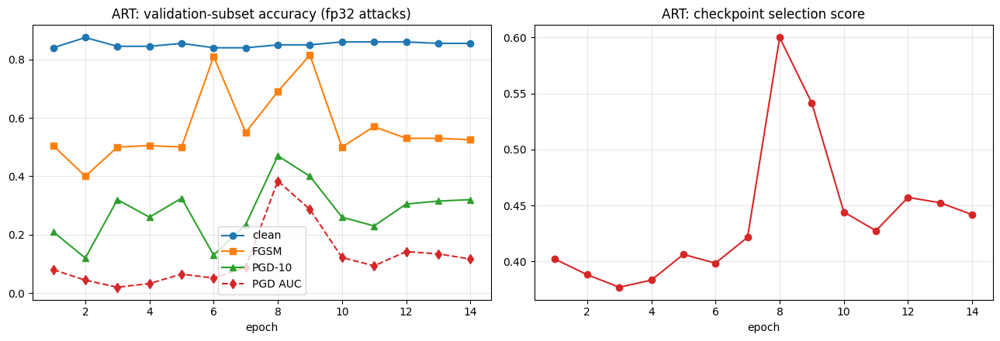

In [11]:
# ============================================================
# CELL 11: Adversarial fine-tuning (PGD-AT or TRADES) with robust checkpoint selection
# ============================================================
# v5 diagnosis: ART learned to HEDGE (adversarial loss stalled at ~0.675 = ln 2), was still improving at its last epoch
# (6 of 6), and its checkpoint was selected with PGD-5 although it was tested with PGD-10 x2 restarts (val PGD AUC
# 0.417 vs test 0.002). v6 therefore: trains up to 14 x 350 batches with PGD-5 and a 0.5/0.5 loss, ramps epsilon over
# 2 epochs, selects the checkpoint on PGD-10 (fp32, 200 balanced val videos), warns when the adversarial loss sits at
# ln 2, and stops starting new epochs once the wall-clock deadline is reached (the best checkpoint is already saved).
#  * attack: PGD-5, random start, alpha = 2.5*eps/steps (or TRADES via CONFIG["art_loss"]); train eps == eval eps;
#  * adversarial examples generated in attack mode, then ONE train-mode forward on [clean ; adversarial];
#  * checkpoint score = w*clean_val_AUC + (1-w)*PGD_val_AUC;
#  * label-leak detector every epoch: FGSM accuracy above clean accuracy, or a huge FGSM-PGD gap.

ART_DEADLINE_S = (CONFIG["art_deadline_hours"] or (CONFIG["time_budget_hours"] - 2.3)) * 3600.0

def robust_validation(model, epsilon):
    """Clean / FGSM / PGD-k on the fixed balanced validation subset, all fp32. Returns a metrics dict."""
    st = CONFIG["val_robust_pgd_steps"]
    labels, z_clean = get_logits(model, val_robust_loader, None, desc="val clean")
    _, z_fgsm = get_logits(model, val_robust_loader,
                           lambda m, v, l: fgsm_attack(m, v, l, epsilon=epsilon, use_amp=False), desc="val FGSM")
    _, z_pgd = get_logits(model, val_robust_loader,
                          lambda m, v, l: pgd_attack(m, v, l, epsilon=epsilon, alpha=CONFIG["pgd_step_mult"] * epsilon / st,
                                                     steps=st, use_amp=False), desc=f"val PGD-{st}")
    acc = lambda z: float(np.mean((z >= 0).astype(int) == labels))
    auc = lambda z: float(roc_auc_score(labels, z))
    out = {"clean_acc": acc(z_clean), "clean_auc": auc(z_clean),
           "fgsm_acc": acc(z_fgsm), "fgsm_auc": auc(z_fgsm),
           "pgd_acc": acc(z_pgd), "pgd_auc": auc(z_pgd)}
    out["leak_flag"] = (out["fgsm_acc"] > out["clean_acc"] + 0.02) or (out["fgsm_acc"] - out["pgd_acc"] > 0.30)
    w = CONFIG["robust_select_weight"]
    out["select_score"] = w * out["clean_auc"] + (1.0 - w) * out["pgd_auc"]
    return out


def finetune_adversarial(epsilon, clean_w, adv_w, epochs, tag, init_state, save_path=None, seed=None, deadline_s=None):
    """Initialise a FRESH model from `init_state` (the best clean checkpoint), unfreeze the same blocks, then
    fine-tune with the adversarial objective. Returns (ema_model, history_df, best_select_score)."""
    set_global_seed(CONFIG["seed"] if seed is None else seed)

    ft_model = build_model()
    ft_model.load_state_dict(init_state)
    ft_model.unfreeze_last_n_blocks(CONFIG["unfreeze_last_n_blocks"])

    optimizer = build_optimizer(ft_model)
    for g in optimizer.param_groups:
        g["lr"] *= CONFIG["art_lr_scale"]
    steps_per_epoch = min(len(train_loader_art), CONFIG["art_steps_per_epoch"])
    scheduler = build_scheduler(optimizer, epochs * steps_per_epoch, CONFIG["art_warmup_steps"], CONFIG["min_lr_ratio"])
    scaler = torch.amp.GradScaler("cuda") if USE_AMP else None
    ema = ModelEMA(ft_model, CONFIG["ema_decay_art"])

    adv_cfg = {"epsilon": epsilon, "ramp_steps": int(CONFIG["art_eps_ramp_epochs"] * steps_per_epoch),
               "state": {"step": 0}, "loss": CONFIG["art_loss"], "attack": CONFIG["art_attack"],
               "steps": CONFIG["art_pgd_steps"], "mult": CONFIG["pgd_step_mult"], "clean_w": clean_w, "adv_w": adv_w,
               "beta": CONFIG["trades_beta"]}

    history = []
    best_score = -1.0
    t_start = time.time()
    deadline_s = ART_DEADLINE_S if deadline_s is None else deadline_s
    print(f"\n{'=' * 60}\n{tag}: loss={CONFIG['art_loss']} eps={epsilon * 255:.1f}/255 attack=PGD-{CONFIG['art_pgd_steps']} "
          f"clean_w={clean_w} adv_w={adv_w}  epochs={epochs} x {steps_per_epoch} batches "
          f"(eps ramp {CONFIG['art_eps_ramp_epochs']} epochs)\n{'=' * 60}")

    for epoch in range(1, epochs + 1):
        if epoch > 1 and time.time() - NOTEBOOK_START > deadline_s:      # always finish epoch 1 so a checkpoint exists
            print(f"\n!! DEADLINE: {(time.time() - NOTEBOOK_START) / 3600:.2f} h since notebook start >= "
                  f"{deadline_s / 3600:.2f} h. Stopping ART after {epoch - 1}/{epochs} epochs; the best checkpoint "
                  f"so far is already saved. (The cosine schedule had not finished decaying.)")
            break
        t_ep = time.time()
        train_metrics = train_epoch(
            ft_model, train_loader_art, optimizer, criterion, scaler, USE_AMP, scheduler=scheduler, ema=ema,
            adversarial=True, adv_cfg=adv_cfg, grad_clip_norm=CONFIG["grad_clip_norm"], desc=f"ART epoch {epoch}",
            max_steps=steps_per_epoch,
        )
        t_train = time.time() - t_ep
        rv = robust_validation(ema.module, epsilon)

        print(f"\nEpoch {epoch}/{epochs}  [{time.time() - t_ep:.0f}s, train {t_train:.0f}s]  "
              f"elapsed ART {(time.time() - t_start) / 60:.0f} min")
        print(f"  Train: total={train_metrics['loss']:.4f} clean={train_metrics['clean_loss']:.4f} "
              f"{'KL' if CONFIG['art_loss'] == 'trades' else 'adv'}={train_metrics['adv_loss']:.4f} "
              f"acc(clean part)={train_metrics['acc']:.4f}")
        print(f"  Val (EMA, {len(val_robust_records)} videos, fp32 attacks eps={epsilon * 255:.0f}/255): "
              f"clean acc={rv['clean_acc']:.3f} AUC={rv['clean_auc']:.3f} | FGSM acc={rv['fgsm_acc']:.3f} | "
              f"PGD-{CONFIG['val_robust_pgd_steps']} acc={rv['pgd_acc']:.3f} AUC={rv['pgd_auc']:.3f} | "
              f"selection score={rv['select_score']:.4f}")
        if rv["leak_flag"]:
            print("  !! LABEL-LEAK WARNING: FGSM accuracy exceeds clean accuracy (or is >30 points above PGD). "
                  "The model is probably learning to detect the attack, not resisting it.")
        if CONFIG["art_loss"] != "trades" and abs(train_metrics["adv_loss"] - math.log(2)) < 0.03 and epoch >= 3:
            print("  !! HEDGING WARNING: adversarial training loss is ~ln 2 (0.693): the model outputs ~0.5 on "
                  "adversarial inputs instead of resisting them. Consider CONFIG['art_loss']='trades' or a smaller epsilon.")

        history.append({"epoch": epoch, "tag": tag, **{f"train_{k}": v for k, v in train_metrics.items()},
                        **{f"val_{k}": v for k, v in rv.items()}})

        if rv["select_score"] > best_score:
            best_score = rv["select_score"]
            if save_path:
                torch.save({"model_state_dict": ema.module.state_dict(), "val_score": best_score, "epoch": epoch,
                            "epsilon": epsilon, "clean_w": clean_w, "adv_w": adv_w, "weights": "ema",
                            "val_clean_auc": rv["clean_auc"], "val_pgd_auc": rv["pgd_auc"]}, save_path)
                print(f"  --> Best {tag} model saved (selection score={best_score:.4f}) -> {save_path}")
        free_cuda_memory()

    del optimizer, scheduler, scaler
    free_cuda_memory()
    return ema.module, pd.DataFrame(history), best_score


# ---- Optional: compare loss-weight trade-offs (validation only; slow, off by default) ----
if CONFIG["run_loss_weight_comparison"]:
    print("CONFIG['run_loss_weight_comparison']=True -- comparing 0.7/0.3, 0.5/0.5, 0.3/0.7 (each a full ART run: SLOW) ...")
    weight_comparison_rows, best_candidate, best_cand_score = [], None, -1.0
    for cw, aw in [(0.7, 0.3), (0.5, 0.5), (0.3, 0.7)]:
        _, _, sc = finetune_adversarial(CONFIG["art_epsilon"], cw, aw, CONFIG["art_finetune_epochs"],
                                        tag=f"ART trial ({cw}/{aw})", init_state=clean_checkpoint["model_state_dict"])
        weight_comparison_rows.append({"clean_w": cw, "adv_w": aw, "best_selection_score": sc})
        if sc > best_cand_score:
            best_cand_score, best_candidate = sc, (cw, aw)
        free_cuda_memory()
    print(pd.DataFrame(weight_comparison_rows).to_string(index=False))
    art_clean_w, art_adv_w = best_candidate
    print(f"Selected: clean_w={art_clean_w}, adv_w={art_adv_w}")
else:
    art_clean_w, art_adv_w = CONFIG["art_clean_loss_weight"], CONFIG["art_adv_loss_weight"]
    print(f"Using clean_w={art_clean_w}, adv_w={art_adv_w} (v6 default 0.5/0.5; v5's 0.7/0.3 let the model hedge).")

# ---- Final adversarial fine-tuning run, saved as the ART checkpoint ----
art_model, art_history, art_best_score = finetune_adversarial(
    CONFIG["art_epsilon"], art_clean_w, art_adv_w, CONFIG["art_finetune_epochs"],
    tag=f"ART fine-tune ({CONFIG['art_loss']})", init_state=clean_checkpoint["model_state_dict"],
    save_path=CONFIG["save_art_checkpoint"],
)

print(f"\nAdversarial fine-tuning complete. Best selection score "
      f"({CONFIG['robust_select_weight']}*clean AUC + {1 - CONFIG['robust_select_weight']:.1f}*PGD-{CONFIG['val_robust_pgd_steps']} AUC, val subset): {art_best_score:.4f}")
if len(art_history) and int(art_history["val_select_score"].idxmax()) == len(art_history) - 1 and len(art_history) >= 3:
    print("NOTE: the best epoch is the LAST one, so training was still improving when it stopped. If time allows, "
          "raise CONFIG['art_finetune_epochs'] (and the deadline) and re-run the ART cell.")
if clean_best_val_auc < 0.65:
    print("WARNING: the clean baseline is close to chance (val ROC-AUC < 0.65). Adversarial fine-tuning of a model "
          "that has not learned the task says nothing about robustness -- fix the clean model first.")
if art_history["val_leak_flag"].any():
    bad = art_history.loc[art_history["val_leak_flag"], "epoch"].tolist()
    print(f"NOTE: the label-leak detector fired in epochs {bad}. Do not trust single-step FGSM numbers from those epochs.")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(art_history["epoch"], art_history["val_clean_acc"], marker="o", label="clean")
axes[0].plot(art_history["epoch"], art_history["val_fgsm_acc"], marker="s", label="FGSM")
axes[0].plot(art_history["epoch"], art_history["val_pgd_acc"], marker="^", label=f"PGD-{CONFIG['val_robust_pgd_steps']}")
axes[0].plot(art_history["epoch"], art_history["val_pgd_auc"], marker="d", linestyle="--", label="PGD AUC")
axes[0].set_title("ART: validation-subset accuracy (fp32 attacks)")
axes[1].plot(art_history["epoch"], art_history["val_select_score"], marker="o", color="tab:red")
axes[1].set_title("ART: checkpoint selection score")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.savefig("/kaggle/working/art_training_curves.png", dpi=150)
plt.show()


In [12]:
# ============================================================
# CELL 12: Robustness evaluation (fp32, strong attacks, statistics)
# ============================================================
# Review items 4, 5, 7, 11. Reloads the BEST ART checkpoint, calibrates it and picks its own threshold on
# validation, then evaluates BOTH models under: Clean / FGSM (2,4,8 /255) / PGD-10 (2 and 4 /255, 2 random
# restarts) / PGD-20 (4/255) / BestMargin-25 (2 and 4 /255; momentum + best-iterate PGD on the logit-margin loss).
# Everything runs in fp32. Every attacked condition uses the SAME balanced test
# subset for both models, so McNemar tests are paired. FGSM is reported but never used alone to claim robustness.

free_cuda_memory()
art_checkpoint = torch.load(CONFIG["save_art_checkpoint"], map_location=CONFIG["device"], weights_only=False)
art_model.load_state_dict(art_checkpoint["model_state_dict"])
art_model.eval()
print(f"Loaded best ART checkpoint (epoch {art_checkpoint['epoch']}, selection score={art_checkpoint['val_score']:.4f}, "
      f"val clean AUC={art_checkpoint['val_clean_auc']:.4f}, val PGD AUC={art_checkpoint['val_pgd_auc']:.4f}, "
      f"eps={art_checkpoint['epsilon'] * 255:.0f}/255)")

print("\nCalibration + threshold for the ART model (validation set only):")
art_T, art_selected_threshold, art_thr_info = calibrate_and_threshold(art_model, "ART fine-tuned")
print(f"Thresholds -- clean-trained: {clean_selected_threshold:.3f} | ART: {art_selected_threshold:.3f}")

n_atk_videos = len(test_attack_records)
print(f"\nAttacked conditions use a balanced test subset of {n_atk_videos} videos "
      f"({n_atk_videos // 2} real + {n_atk_videos // 2} fake); 'Clean (full test)' uses all {len(test_records)}.")

CONDITIONS = make_conditions(CONFIG["robustness_fgsm_epsilons"], CONFIG["robustness_pgd_configs"],
                              CONFIG["robustness_margin_configs"])
raw_cache = {}      # {(model_tag, condition): (labels, logits)}   -- reused by later cells, no attack is run twice


def evaluate_all_conditions(model, T, threshold, model_tag, conditions, store=raw_cache, loader=None):
    """Clean (full test) + Clean (attack subset) + every attack condition. Returns a DataFrame."""
    loader = loader or test_attack_loader
    reset_attack_diag()
    t0 = time.time()
    rows = []

    full_l, full_z = get_logits(model, test_loader, None, desc=f"{model_tag} clean full")
    store[(model_tag, "Clean (full test)")] = (full_l, full_z)
    sub_l, sub_z = get_logits(model, loader, None, desc=f"{model_tag} clean subset")
    store[(model_tag, "Clean")] = (sub_l, sub_z)
    sub_probs = sigmoid_np(sub_z, T)
    clean_correct = ((sub_probs >= threshold).astype(int) == sub_l)
    n_init_correct = int(clean_correct.sum())

    def _row(name, labels, logits, is_attack):
        probs = sigmoid_np(logits, T)
        m = compute_metrics(labels, probs, threshold=threshold)
        correct = ((probs >= threshold).astype(int) == labels)
        lo, hi = wilson_ci(int(correct.sum()), len(labels))
        m["acc_ci_lo"], m["acc_ci_hi"] = lo, hi
        m["asr"] = (int((clean_correct & ~correct).sum()) / n_init_correct) if (is_attack and n_init_correct > 0) else np.nan
        m["n_videos"] = len(labels)
        return {"Condition": name, **m}

    rows.append(_row("Clean (full test)", full_l, full_z, False))
    rows.append(_row("Clean", sub_l, sub_z, False))
    for cname, attack_fn in conditions:
        l_, z_ = get_logits(model, loader, attack_fn, desc=f"{model_tag} {cname}")
        assert np.array_equal(l_, sub_l), "sample order mismatch between clean and attacked passes"
        store[(model_tag, cname)] = (l_, z_)
        rows.append(_row(cname, l_, z_, True))
        free_cuda_memory()
    df = pd.DataFrame(rows)
    df["Model"] = model_tag
    print(f"[{model_tag}] done in {(time.time() - t0) / 60:.1f} min | zero-gradient samples: "
          f"{ATTACK_DIAG['zero_grad_samples']}/{ATTACK_DIAG['samples']}")
    assert ATTACK_DIAG["zero_grad_samples"] == 0, "zero input-gradient samples found -- attacks are weaker than reported"
    return df


clean_model_results = evaluate_all_conditions(clean_model, clean_T, clean_selected_threshold, "Clean-trained", CONDITIONS)
art_model_results = evaluate_all_conditions(art_model, art_T, art_selected_threshold, "ART fine-tuned", CONDITIONS)

METRIC_COLS = ["accuracy", "acc_ci_lo", "acc_ci_hi", "precision", "recall", "f1", "roc_auc", "pr_auc", "balanced_accuracy",
               "recall_real", "recall_fake", "asr", "n_videos"]
comparison_df = pd.concat([clean_model_results, art_model_results], ignore_index=True)
comparison_df = comparison_df[["Model", "Condition"] + METRIC_COLS]

for model_name in ["Clean-trained", "ART fine-tuned"]:
    sub = comparison_df[comparison_df["Model"] == model_name]
    ref = sub[sub["Condition"] == "Clean"].iloc[0]
    comparison_df.loc[sub.index, "Accuracy Drop"] = ref["accuracy"] - sub["accuracy"]
    comparison_df.loc[sub.index, "F1 Drop"] = ref["f1"] - sub["f1"]
    comparison_df.loc[sub.index, "F1 Retention %"] = np.where(ref["f1"] > 0, sub["f1"] / ref["f1"] * 100.0, 0.0)
    # Review item 1: robust accuracy ABOVE clean accuracy is a red flag, never a result
    comparison_df.loc[sub.index, "Reading"] = np.where(
        (sub["Condition"] != "Clean") & (~sub["Condition"].str.startswith("Clean")) &
        (sub["accuracy"] > ref["accuracy"] + 0.02), "SUSPICIOUS (> clean)", "")

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
show_cols = ["Model", "Condition", "accuracy", "acc_ci_lo", "acc_ci_hi", "roc_auc", "f1", "recall_real", "recall_fake",
             "asr", "Reading"]
print("\n" + "=" * 100)
print("CLEAN-TRAINED vs ART FINE-TUNED -- ROBUSTNESS COMPARISON (fp32 attacks)")
print("=" * 100)
print(comparison_df[show_cols].round(4).to_string(index=False))


def _val(model_name, condition, col):
    return comparison_df[(comparison_df["Model"] == model_name) & (comparison_df["Condition"] == condition)][col].iloc[0]


# ---- Paired significance: ART vs clean-trained, per condition (McNemar, exact) ----
print("\nPaired comparison ART vs clean-trained (exact McNemar on per-video correctness):")
mc_rows = []
for cname in ["Clean (full test)", "Clean"] + [c for c, _ in CONDITIONS]:
    lc, zc = raw_cache[("Clean-trained", cname)]
    la, za = raw_cache[("ART fine-tuned", cname)]
    assert np.array_equal(lc, la)
    cor_c = ((sigmoid_np(zc, clean_T) >= clean_selected_threshold).astype(int) == lc)
    cor_a = ((sigmoid_np(za, art_T) >= art_selected_threshold).astype(int) == la)
    b, c, p = mcnemar_exact(cor_c, cor_a)
    mc_rows.append({"Condition": cname, "clean-only correct": b, "ART-only correct": c, "p-value": p,
                    "significant (p<0.05)": p < 0.05})
mcnemar_df = pd.DataFrame(mc_rows)
print(mcnemar_df.round(4).to_string(index=False))

# ---- Attack-strength ordering (a weaker attack must not look stronger) ----
print("\nSanity: stronger attack should not leave HIGHER accuracy than a weaker one (same epsilon):")
for model_name in ["Clean-trained", "ART fine-tuned"]:
    a10 = _val(model_name, "PGD-10 4/255 (r2)", "accuracy")
    a20 = _val(model_name, "PGD-20 4/255 (r1)", "accuracy")
    af = _val(model_name, "FGSM 4/255", "accuracy")
    print(f"  {model_name:<15}: FGSM 4/255={af:.3f}  PGD-10 r2={a10:.3f}  PGD-20={a20:.3f}  "
          f"{'OK' if (a10 <= af + 0.03 and a20 <= a10 + 0.03) else 'WARNING: ordering violated -- investigate'}")

clean_cost = _val("Clean-trained", "Clean (full test)", "accuracy") - _val("ART fine-tuned", "Clean (full test)", "accuracy")
print(f"\nClean-accuracy cost of adversarial fine-tuning (full test): {clean_cost * 100:+.2f} points "
      f"(clean-trained {_val('Clean-trained', 'Clean (full test)', 'accuracy'):.4f} -> ART {_val('ART fine-tuned', 'Clean (full test)', 'accuracy'):.4f})")
fg_art = _val("ART fine-tuned", "FGSM 2/255", "accuracy")
pg_art = _val("ART fine-tuned", "PGD-10 2/255 (r2)", "accuracy")
if fg_art > _val("ART fine-tuned", "Clean", "accuracy") + 0.02 or fg_art - pg_art > 0.30:
    print("!! FGSM accuracy of the ART model is above its clean accuracy or far above its PGD accuracy: the v4 "
          "label-leaking pattern is still present. Report PGD numbers only.")
else:
    print("FGSM vs PGD for the ART model look consistent (no label-leaking signature).")

# ---- Per-method robustness for both models under the main attack ----
main_cond = CONFIG["main_attack_label"]
print(f"\nPer-method results under '{main_cond}' (attack subset, validation-selected thresholds):")
for model_name, T_, thr_ in [("Clean-trained", clean_T, clean_selected_threshold), ("ART fine-tuned", art_T, art_selected_threshold)]:
    for cname in ("Clean", main_cond):
        l_, z_ = raw_cache[(model_name, cname)]
        df_ = per_method_report(test_attack_records, l_, sigmoid_np(z_, T_), thr_)
        print(f"\n  {model_name} -- {cname}")
        print(df_.round(3).to_string(index=False))

# ---- Confidence under attack ----
def mean_confidence(probs):
    probs = np.asarray(probs)
    return float(np.mean(np.maximum(probs, 1 - probs)))


confidence_rows = []
for model_tag, T_ in [("Clean-trained", clean_T), ("ART fine-tuned", art_T)]:
    c0 = mean_confidence(sigmoid_np(raw_cache[(model_tag, "Clean")][1], T_))
    for cname, _ in CONDITIONS:
        c1 = mean_confidence(sigmoid_np(raw_cache[(model_tag, cname)][1], T_))
        confidence_rows.append({"Model": model_tag, "Condition": cname, "Mean Clean Confidence": c0,
                                "Mean Adversarial Confidence": c1, "Confidence Drop": c0 - c1})
confidence_df = pd.DataFrame(confidence_rows)
print("\nConfidence degradation under attack:")
print(confidence_df.round(4).to_string(index=False))

print(f"\nElapsed since notebook start: {(time.time() - NOTEBOOK_START) / 3600:.2f} h (budget {CONFIG['time_budget_hours']} h).")


Loaded best ART checkpoint (epoch 8, selection score=0.5999, val clean AUC=0.9239, val PGD AUC=0.3839, eps=2/255)

Calibration + threshold for the ART model (validation set only):


[ART fine-tuned] temperature T=1.620  val NLL 0.3936->0.3489  ECE 0.0720->0.0607  | threshold EER=0.387 (EER=0.163)  F1-opt=0.600  -> using eer=0.387
Thresholds -- clean-trained: 0.369 | ART: 0.387

Attacked conditions use a balanced test subset of 200 videos (100 real + 100 fake); 'Clean (full test)' uses all 400.


[Clean-trained] done in 34.4 min | zero-gradient samples: 0/22600


[ART fine-tuned] done in 34.4 min | zero-gradient samples: 0/22600

CLEAN-TRAINED vs ART FINE-TUNED -- ROBUSTNESS COMPARISON (fp32 attacks)
         Model           Condition  accuracy  acc_ci_lo  acc_ci_hi  roc_auc     f1  recall_real  recall_fake    asr Reading
 Clean-trained   Clean (full test)    0.8750     0.8390     0.9039   0.9456 0.8749         0.85        0.900    NaN        
 Clean-trained               Clean    0.8700     0.8163     0.9097   0.9487 0.8700         0.86        0.880    NaN        
 Clean-trained          FGSM 2/255    0.0000     0.0000     0.0188   0.0000 0.0000         0.00        0.000 1.0000        
 Clean-trained          FGSM 4/255    0.0100     0.0027     0.0357   0.0008 0.0100         0.01        0.010 0.9885        
 Clean-trained          FGSM 8/255    0.0350     0.0171     0.0705   0.0037 0.0344         0.01        0.060 0.9598        
 Clean-trained   PGD-10 2/255 (r2)    0.0000     0.0000     0.0188   0.0000 0.0000         0.00        0.000 1.0000 

WORST-CASE ROBUSTNESS (a video is robust only if correct under EVERY attack at that epsilon; AUC = minimum over attacks)
         Model        Condition  accuracy  acc_ci_lo  acc_ci_hi  roc_auc  recall_real  recall_fake    asr
 Clean-trained WORST-CASE 2/255     0.000     0.0000     0.0188      0.0          0.0         0.00 1.0000
 Clean-trained WORST-CASE 4/255     0.000     0.0000     0.0188      0.0          0.0         0.00 1.0000
ART fine-tuned WORST-CASE 2/255     0.285     0.2269     0.3512      0.0          0.0         0.57 0.6821
ART fine-tuned WORST-CASE 4/255     0.205     0.1549     0.2663      0.0          0.0         0.41 0.7803



PGD-10 epsilon sweep on 100 test videos (21.2 min, zero-grad samples 0/14000):
Model    ART fine-tuned  Clean-trained
eps_255                               
0.0                0.86           0.86
1.0                0.08           0.00
2.0                0.40           0.00
3.0                0.51           0.00
4.0                0.49           0.00
6.0                0.50           0.00
8.0                0.50           0.00
16.0               0.51           0.00
Model    ART fine-tuned  Clean-trained
eps_255                               
0.0               0.941          0.944
1.0               0.008          0.000
2.0               0.401          0.000
3.0               0.593          0.000
4.0               0.602          0.000
6.0               0.517          0.000
8.0               0.562          0.000
16.0              0.532          0.000


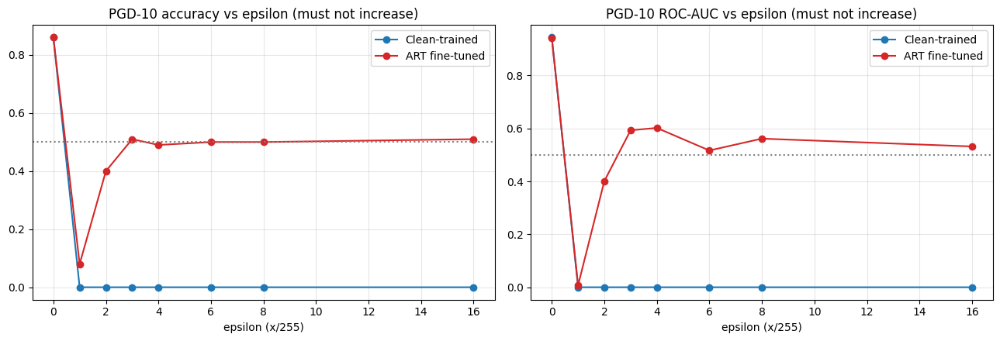


Transfer attack (PGD-10 4/255 crafted on the CLEAN-trained model, tested on ART, black-box): accuracy=0.500  ROC-AUC=1.000

GRADIENT-MASKING / ATTACK-VALIDITY CHECKS  (tolerance +/-0.05)
         Model                                            Check Result                                                                                                                                 Detail
 Clean-trained   (a) PGD accuracy/AUC non-increasing in epsilon   PASS                                                                                                                               monotone
 Clean-trained              (b) 16/255 attack drives AUC < 0.15   PASS                                                                                                                    AUC=0.000 acc=0.000
 Clean-trained                      (c) PGD-10 <= FGSM at 2/255   PASS                                                                                        AUC PGD=0.000 vs FGSM=0.000; acc 0.0

In [13]:
# ============================================================
# CELL 12b: Worst-case robustness, epsilon sweep, transfer attack, gradient-masking checks
# ============================================================
# v5 reported ART accuracy that ROSE with epsilon (24.7% at 2/255 -> 38.7% at 4/255) and FGSM AUC that rose from 0.44 to
# 0.75. A bigger budget can never help the defender, so those numbers meant the attack was not finding the worst case.
# This cell makes that kind of failure impossible to miss. It computes:
#   1. WORST-CASE rows: a video counts as robust only if it is correct under EVERY attack at that epsilon
#      (accuracy), and the MINIMUM ROC-AUC over those attacks;
#   2. a PGD-10 epsilon sweep (1..16 /255) on a smaller subset, for both models;
#   3. a transfer attack (crafted on the clean-trained model, tested on ART): white-box must be at least as strong;
#   4. automatic PASS/FAIL checks (Athalye et al. style). A FAIL means: do NOT report the robustness numbers as final.

tol = CONFIG["mask_check_tol"]
MODELS = {"Clean-trained": (clean_model, clean_T, clean_selected_threshold),
          "ART fine-tuned": (art_model, art_T, art_selected_threshold)}


def _correct(model_tag, cond):
    _, T_, thr_ = MODELS[model_tag][0], MODELS[model_tag][1], MODELS[model_tag][2]
    l_, z_ = raw_cache[(model_tag, cond)]
    return ((sigmoid_np(z_, T_) >= thr_).astype(int) == l_)


def _auc(model_tag, cond):
    l_, z_ = raw_cache[(model_tag, cond)]
    return float(roc_auc_score(l_, z_))


def _acc(model_tag, cond):
    return float(np.mean(_correct(model_tag, cond)))


# ---------------- 1. Worst case across attacks, per epsilon ----------------
eps_groups = {}
for name, eps, steps, restarts in CONFIG["robustness_pgd_configs"]:
    eps_groups.setdefault(round(eps * 255), []).append(f"{name} {round(eps * 255)}/255 (r{restarts})")
for eps, steps in CONFIG["robustness_margin_configs"]:
    eps_groups.setdefault(round(eps * 255), []).append(f"BestMargin-{steps} {round(eps * 255)}/255")

worst_rows = []
for model_tag in MODELS:
    labels_ = raw_cache[(model_tag, "Clean")][0]
    clean_ok = _correct(model_tag, "Clean")
    for e255, conds in sorted(eps_groups.items()):
        ok_all = np.all([_correct(model_tag, c) for c in conds], axis=0)
        lo, hi = wilson_ci(int(ok_all.sum()), len(ok_all))
        worst_rows.append({
            "Model": model_tag, "Condition": f"WORST-CASE {e255}/255", "accuracy": float(ok_all.mean()),
            "acc_ci_lo": lo, "acc_ci_hi": hi, "roc_auc": float(min(_auc(model_tag, c) for c in conds)),
            "recall_real": float(ok_all[labels_ == 0].mean()), "recall_fake": float(ok_all[labels_ == 1].mean()),
            "asr": float((clean_ok & ~ok_all).sum() / max(clean_ok.sum(), 1)), "n_videos": len(ok_all),
            "Reading": f"worst of: {', '.join(conds)}"})
worst_df = pd.DataFrame(worst_rows)
comparison_df = pd.concat([comparison_df, worst_df], ignore_index=True)
print("=" * 100)
print("WORST-CASE ROBUSTNESS (a video is robust only if correct under EVERY attack at that epsilon; AUC = minimum over attacks)")
print("=" * 100)
print(worst_df[["Model", "Condition", "accuracy", "acc_ci_lo", "acc_ci_hi", "roc_auc", "recall_real", "recall_fake", "asr"]]
      .round(4).to_string(index=False))

# ---------------- 2. Epsilon sweep (PGD-10, 1 restart) ----------------
n_sw = CONFIG["eps_sweep_per_class"]
sweep_records = ([r for r in test_attack_records if r[1] == 0][:n_sw] + [r for r in test_attack_records if r[1] == 1][:n_sw])
sweep_eval_loader = make_eval_loader(
    PreextractedVideoDataset(sweep_records, seq_len=CONFIG["seq_len"], img_size=CONFIG["img_size"], is_train=False),
    CONFIG["eval_attack_batch_size"])
t_sw = time.time()
reset_attack_diag()
sweep_rows = []
for model_tag, (mdl, T_, thr_) in MODELS.items():
    l0, z0 = get_logits(mdl, sweep_eval_loader, None, desc=f"{model_tag} sweep clean")
    raw_cache[(model_tag, "SWEEP clean")] = (l0, z0)
    sweep_rows.append({"Model": model_tag, "eps_255": 0.0, "accuracy": float(np.mean((sigmoid_np(z0, T_) >= thr_).astype(int) == l0)),
                       "roc_auc": float(roc_auc_score(l0, z0))})
    for eps in CONFIG["eps_sweep"]:
        fn = lambda m, v, l, eps=eps: pgd_attack(m, v, l, epsilon=eps, alpha=CONFIG["pgd_step_mult"] * eps / 10, steps=10,
                                                  restarts=1, random_start=True, use_amp=False)
        l_, z_ = get_logits(mdl, sweep_eval_loader, fn, desc=f"{model_tag} sweep {eps * 255:g}/255")
        raw_cache[(model_tag, f"SWEEP {eps * 255:g}")] = (l_, z_)
        sweep_rows.append({"Model": model_tag, "eps_255": round(eps * 255, 3),
                           "accuracy": float(np.mean((sigmoid_np(z_, T_) >= thr_).astype(int) == l_)),
                           "roc_auc": float(roc_auc_score(l_, z_))})
        free_cuda_memory()
sweep_df2 = pd.DataFrame(sweep_rows)
print(f"\nPGD-10 epsilon sweep on {len(sweep_records)} test videos ({(time.time() - t_sw) / 60:.1f} min, "
      f"zero-grad samples {ATTACK_DIAG['zero_grad_samples']}/{ATTACK_DIAG['samples']}):")
print(sweep_df2.pivot(index="eps_255", columns="Model", values="accuracy").round(3).to_string())
print(sweep_df2.pivot(index="eps_255", columns="Model", values="roc_auc").round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for model_tag, color in [("Clean-trained", "tab:blue"), ("ART fine-tuned", "tab:red")]:
    g = sweep_df2[sweep_df2["Model"] == model_tag].sort_values("eps_255")
    axes[0].plot(g["eps_255"], g["accuracy"], marker="o", label=model_tag, color=color)
    axes[1].plot(g["eps_255"], g["roc_auc"], marker="o", label=model_tag, color=color)
axes[0].axhline(0.5, color="gray", linestyle=":")
axes[1].axhline(0.5, color="gray", linestyle=":")
axes[0].set_title("PGD-10 accuracy vs epsilon (must not increase)")
axes[1].set_title("PGD-10 ROC-AUC vs epsilon (must not increase)")
for ax in axes:
    ax.set_xlabel("epsilon (x/255)")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig("/kaggle/working/pgd_epsilon_sweep_both_models.png", dpi=150)
plt.show()

# ---------------- 3. Transfer attack: clean-trained -> ART (black-box) ----------------
def get_transfer_logits(source_model, target_model, eps, loader, desc="transfer"):
    all_l, all_z = [], []
    target_model.eval()
    for videos, labels in tqdm(loader, desc=desc, leave=False):
        videos = videos.to(CONFIG["device"], non_blocking=True)
        labels_dev = labels.to(CONFIG["device"], non_blocking=True)
        adv = pgd_attack(source_model, videos, labels_dev, epsilon=eps, alpha=CONFIG["pgd_step_mult"] * eps / 10, steps=10,
                         restarts=1, random_start=True, use_amp=False)
        with torch.no_grad():
            z = target_model(adv).float()
        all_l.append(labels.numpy())
        all_z.append(z.cpu().numpy())
    return np.concatenate(all_l).astype(int), np.concatenate(all_z)


tr_eps = CONFIG["transfer_eps"]
tr_l, tr_z = get_transfer_logits(clean_model, art_model, tr_eps, test_attack_loader, desc="transfer clean->ART")
raw_cache[("ART fine-tuned", "TRANSFER")] = (tr_l, tr_z)
tr_acc = float(np.mean((sigmoid_np(tr_z, art_T) >= art_selected_threshold).astype(int) == tr_l))
tr_auc = float(roc_auc_score(tr_l, tr_z))
print(f"\nTransfer attack (PGD-10 {tr_eps * 255:.0f}/255 crafted on the CLEAN-trained model, tested on ART, black-box): "
      f"accuracy={tr_acc:.3f}  ROC-AUC={tr_auc:.3f}")
free_cuda_memory()

# ---------------- 4. Automatic gradient-masking / attack-validity checks ----------------
masking_results = []


def _check(model_tag, name, passed, detail):
    masking_results.append({"Model": model_tag, "Check": name, "Result": "PASS" if passed else "FAIL", "Detail": detail})


for model_tag in MODELS:
    g = sweep_df2[sweep_df2["Model"] == model_tag].sort_values("eps_255").reset_index(drop=True)
    # (a) monotone in epsilon (accuracy and AUC may not rise by more than tol)
    bad = [(g.eps_255[i], g.eps_255[i + 1]) for i in range(len(g) - 1)
           if g.roc_auc[i + 1] > g.roc_auc[i] + tol or g.accuracy[i + 1] > g.accuracy[i] + tol]
    _check(model_tag, "(a) PGD accuracy/AUC non-increasing in epsilon", not bad,
           "monotone" if not bad else f"rises between eps pairs {bad[:3]} (a larger budget helped the defender)")
    # (b) very large epsilon should break any model
    big = g[g.eps_255 == g.eps_255.max()].iloc[0]
    _check(model_tag, f"(b) {big.eps_255:g}/255 attack drives AUC < 0.15", big.roc_auc < 0.15,
           f"AUC={big.roc_auc:.3f} acc={big.accuracy:.3f}")
    # (c) iterative at least as strong as single step (same eps, main subset)
    for e255 in (2, 4):
        f_, p_ = f"FGSM {e255}/255", [c for c in eps_groups[e255] if c.startswith("PGD-10")][0]
        ok = _auc(model_tag, p_) <= _auc(model_tag, f_) + tol and _acc(model_tag, p_) <= _acc(model_tag, f_) + tol
        _check(model_tag, f"(c) PGD-10 <= FGSM at {e255}/255", ok,
               f"AUC PGD={_auc(model_tag, p_):.3f} vs FGSM={_auc(model_tag, f_):.3f}; acc {_acc(model_tag, p_):.3f} vs {_acc(model_tag, f_):.3f}")
    # (d) margin-loss attack must not be much stronger than the BCE attack (else BCE saturation masked the gradient)
    for e255 in (2, 4):
        p_ = [c for c in eps_groups[e255] if c.startswith("PGD-10")][0]
        m_ = [c for c in eps_groups[e255] if c.startswith("BestMargin")][0]
        ok = _auc(model_tag, m_) >= _auc(model_tag, p_) - tol and _acc(model_tag, m_) >= _acc(model_tag, p_) - tol
        _check(model_tag, f"(d) BestMargin not stronger than CE-PGD at {e255}/255", ok,
               f"AUC margin={_auc(model_tag, m_):.3f} vs CE={_auc(model_tag, p_):.3f}; acc {_acc(model_tag, m_):.3f} vs {_acc(model_tag, p_):.3f}")
# (e) transfer (black-box) must be weaker than white-box on the same model
wb = [c for c in eps_groups[round(tr_eps * 255)] if c.startswith("PGD-10")][0]
ok = _auc("ART fine-tuned", wb) <= tr_auc + tol
_check("ART fine-tuned", "(e) white-box at least as strong as transfer", ok,
       f"white-box AUC={_auc('ART fine-tuned', wb):.3f} vs transfer AUC={tr_auc:.3f}")

masking_df = pd.DataFrame(masking_results)
print("\n" + "=" * 100)
print("GRADIENT-MASKING / ATTACK-VALIDITY CHECKS  (tolerance +/-" + f"{tol})")
print("=" * 100)
print(masking_df.to_string(index=False))
n_fail_art = int((masking_df[masking_df.Model == "ART fine-tuned"].Result == "FAIL").sum())
if n_fail_art:
    print(f"\n!! {n_fail_art} check(s) FAILED for the ART model: its robustness numbers are UNRELIABLE and probably "
          f"optimistic. Treat the worst of the attacks as the result, and do not claim robustness yet.")
else:
    print("\nAll attack-validity checks passed for the ART model: the attacks behave like proper worst-case attacks, so "
          "the robust numbers can be taken at face value (still bounded by the attacks we ran).")

# ---------------- Honest verdict on usefulness ----------------
w2 = worst_df[(worst_df.Model == "ART fine-tuned") & (worst_df.Condition == "WORST-CASE 2/255")].iloc[0]
w4 = worst_df[(worst_df.Model == "ART fine-tuned") & (worst_df.Condition == "WORST-CASE 4/255")].iloc[0]
print(f"\nART worst-case: 2/255 acc={w2.accuracy:.3f} (real recall {w2.recall_real:.2f}, fake recall {w2.recall_fake:.2f}), "
      f"min AUC={w2.roc_auc:.3f} | 4/255 acc={w4.accuracy:.3f}, min AUC={w4.roc_auc:.3f}")
if w2.recall_real < 0.05 or w2.roc_auc < 0.5:
    print("VERDICT: still NOT robust at 2/255 -- either every real video is flagged fake, or the ranking is inverted "
          "(AUC < 0.5). Accuracy above 0 here is not meaningful.")
elif w2.roc_auc >= 0.7:
    print("VERDICT: meaningful robustness at 2/255 (min AUC >= 0.7 over every attack). Check 4/255 and the checks above.")
else:
    print("VERDICT: partial robustness at 2/255 (0.5 <= min AUC < 0.7): better than chance under attack but far from solved.")

if n_fail_art:
    print(f"(The verdict above is PROVISIONAL: {n_fail_art} attack-validity check(s) failed, so the true worst case may be worse.)")

MAIN_RUN_SECONDS = time.time() - T_MAIN_START      # used by the multi-seed time guard (last cell)
print(f"\nMain pipeline (clean train + ART + evaluation) took {MAIN_RUN_SECONDS / 60:.0f} min; "
      f"{(time.time() - NOTEBOOK_START) / 3600:.2f} h since notebook start (budget {CONFIG['time_budget_hours']} h).")


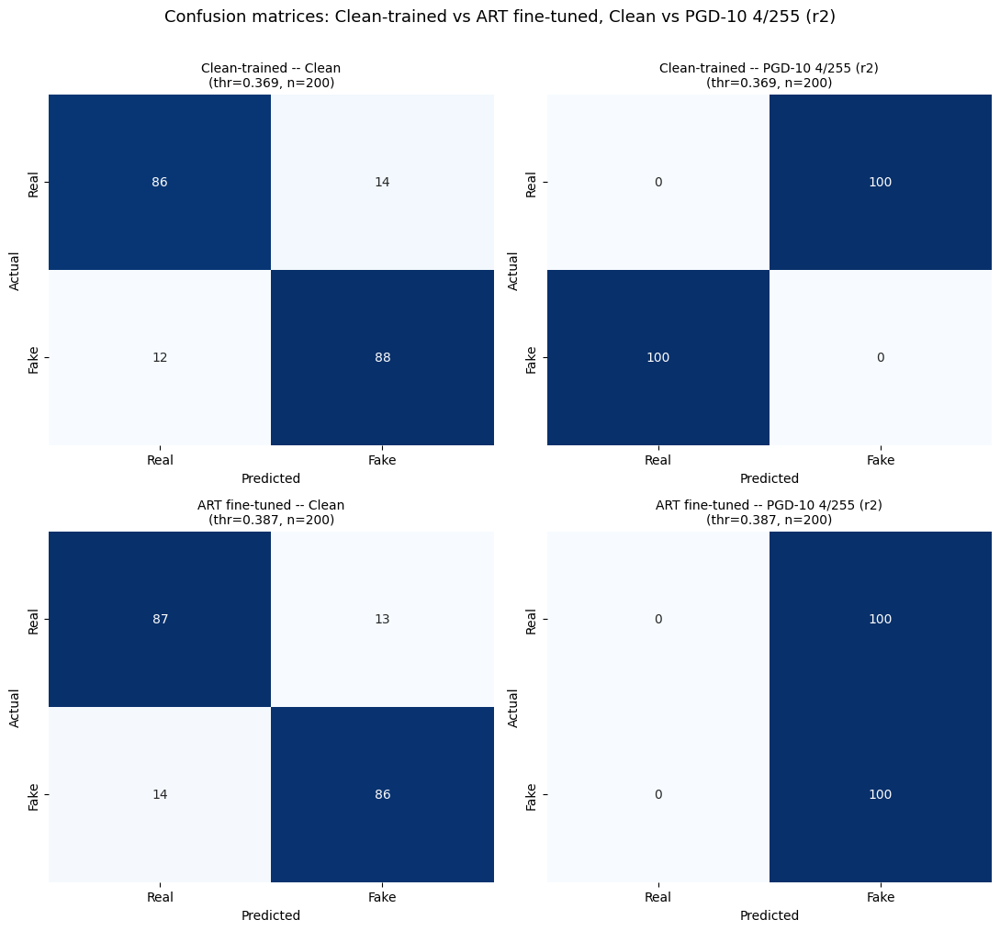

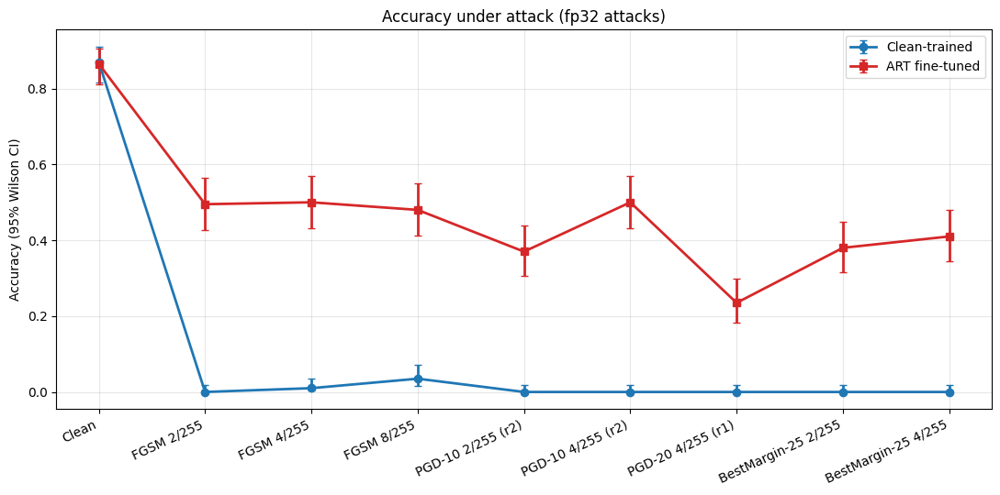

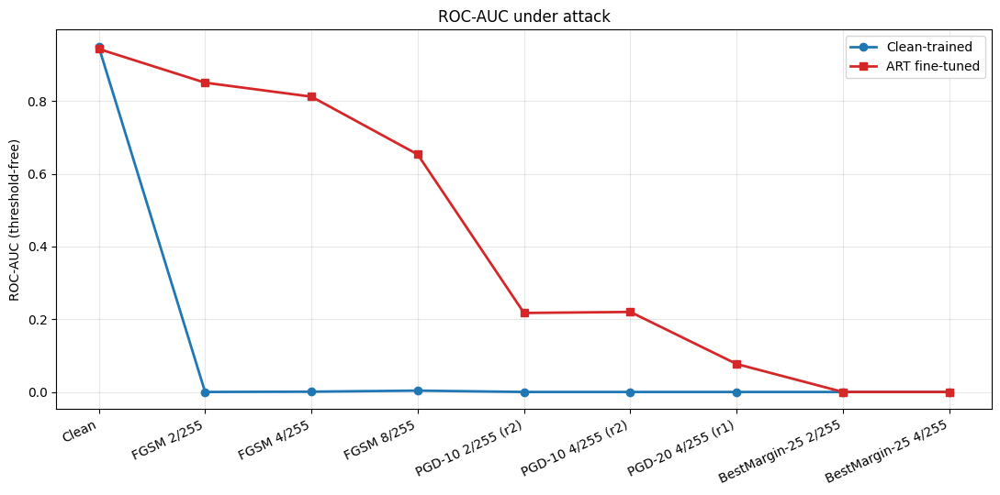

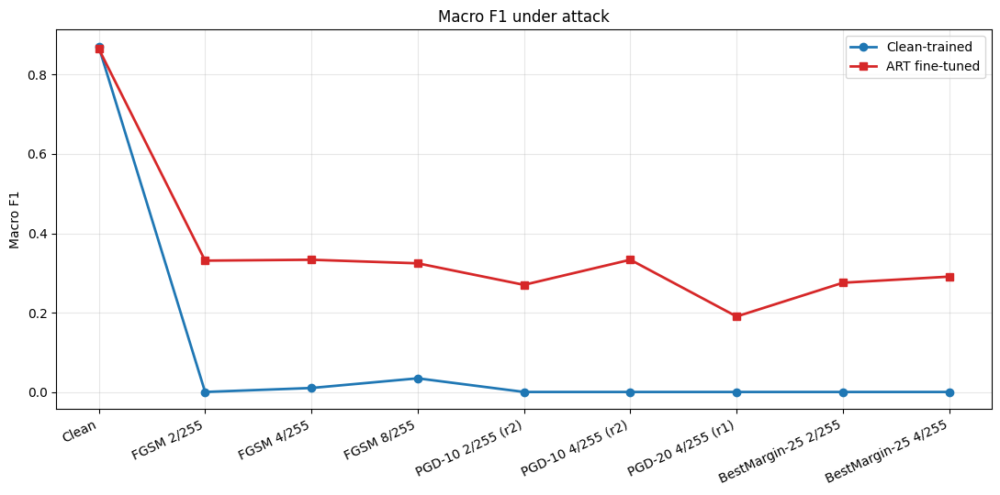

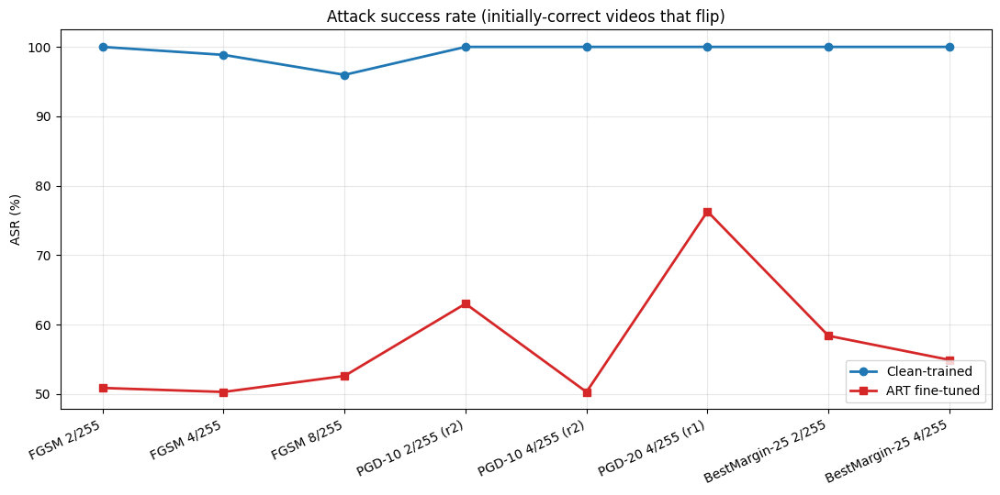

Saved robustness_accuracy.png, robustness_roc_auc.png, robustness_macro_f1.png, robustness_asr.png


In [14]:
# ============================================================
# CELL 13: Confusion matrices (clean-trained & ART, Clean & main PGD attack)
# ============================================================
# Reuses the cached logits from Cell 12 (no attack is re-run). Each model uses its own calibrated
# probabilities and validation-selected threshold.

main_cond = CONFIG["main_attack_label"]
confusion_conditions = [
    ("Clean-trained", "Clean", clean_T, clean_selected_threshold),
    ("Clean-trained", main_cond, clean_T, clean_selected_threshold),
    ("ART fine-tuned", "Clean", art_T, art_selected_threshold),
    ("ART fine-tuned", main_cond, art_T, art_selected_threshold),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, (model_tag, condition, T_, thr_) in zip(axes.flat, confusion_conditions):
    labels_, logits_ = raw_cache[(model_tag, condition)]
    preds_ = (sigmoid_np(logits_, T_) >= thr_).astype(int)
    cm = confusion_matrix(labels_, preds_, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Real', 'Fake'], yticklabels=['Real', 'Fake'])
    ax.set_title(f"{model_tag} -- {condition}\n(thr={thr_:.3f}, n={len(labels_)})", fontsize=10)
    ax.set_ylabel("Actual")
    ax.set_xlabel("Predicted")
plt.suptitle(f"Confusion matrices: Clean-trained vs ART fine-tuned, Clean vs {main_cond}", y=1.01, fontsize=13)
plt.tight_layout()
plt.savefig("/kaggle/working/confusion_matrices_4condition.png", dpi=150, bbox_inches="tight")
plt.show()

# ============================================================
# CELL 14: Robustness comparison plots (built from comparison_df -- no hard-coded values)
# ============================================================
attack_order = ["Clean"] + [c for c, _ in CONDITIONS]
asr_order = [c for c, _ in CONDITIONS]


def _plot_metric_vs_attack(metric_col, ylabel, title, out_path, conditions=attack_order, ci=False):
    plt.figure(figsize=(11, 5.5))
    for model_name, marker, color in [("Clean-trained", "o", "tab:blue"), ("ART fine-tuned", "s", "tab:red")]:
        sub = comparison_df[comparison_df["Model"] == model_name].set_index("Condition").reindex(conditions)
        y = sub[metric_col] * (100 if metric_col == "asr" else 1)
        if ci:
            yerr = np.vstack([(sub[metric_col] - sub["acc_ci_lo"]).values, (sub["acc_ci_hi"] - sub[metric_col]).values])
            plt.errorbar(range(len(conditions)), y, yerr=yerr, marker=marker, label=model_name, color=color,
                         linewidth=2, capsize=3)
        else:
            plt.plot(range(len(conditions)), y, marker=marker, label=model_name, color=color, linewidth=2)
    plt.xticks(range(len(conditions)), conditions, rotation=25, ha="right")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(out_path, dpi=150)
    plt.show()


_plot_metric_vs_attack("accuracy", "Accuracy (95% Wilson CI)", "Accuracy under attack (fp32 attacks)",
                       "/kaggle/working/robustness_accuracy.png", ci=True)
_plot_metric_vs_attack("roc_auc", "ROC-AUC (threshold-free)", "ROC-AUC under attack",
                       "/kaggle/working/robustness_roc_auc.png")
_plot_metric_vs_attack("f1", "Macro F1", "Macro F1 under attack", "/kaggle/working/robustness_macro_f1.png")
_plot_metric_vs_attack("asr", "ASR (%)", "Attack success rate (initially-correct videos that flip)",
                       "/kaggle/working/robustness_asr.png", conditions=asr_order)
print("Saved robustness_accuracy.png, robustness_roc_auc.png, robustness_macro_f1.png, robustness_asr.png")


INTERPRETATION CAVEAT: Grad-CAM shows which spatial regions contributed to the prediction. It does NOT by itself prove the manipulation artifact -- treat it as a localisation aid, not ground-truth evidence.

  sample 0 (true=fake) | Clean-trained  | clean         | P(fake)=0.287 (thr 0.369) -> predicted real
  sample 0 (true=fake) | Clean-trained  | PGD-10 4/255  | P(fake)=0.027 (thr 0.369) -> predicted real
  sample 0 (true=fake) | ART fine-tuned | clean         | P(fake)=0.332 (thr 0.387) -> predicted real
  sample 0 (true=fake) | ART fine-tuned | PGD-10 4/255  | P(fake)=0.504 (thr 0.387) -> predicted fake


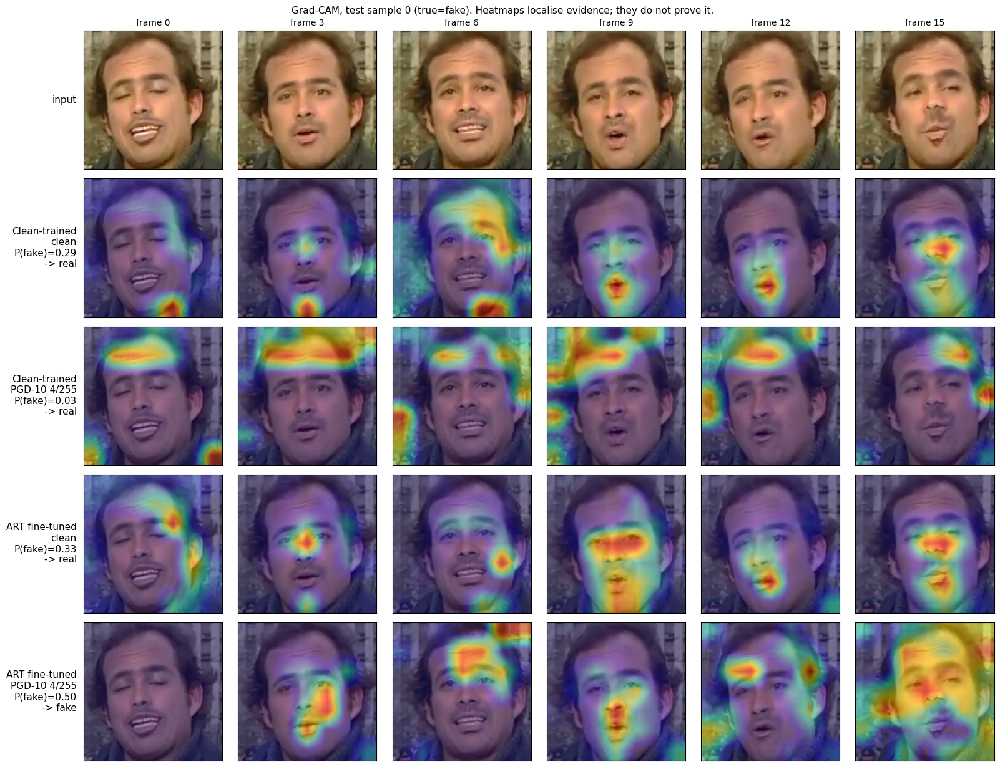

  sample 2 (true=real) | Clean-trained  | clean         | P(fake)=0.094 (thr 0.369) -> predicted real
  sample 2 (true=real) | Clean-trained  | PGD-10 4/255  | P(fake)=0.969 (thr 0.369) -> predicted fake
  sample 2 (true=real) | ART fine-tuned | clean         | P(fake)=0.172 (thr 0.387) -> predicted real
  sample 2 (true=real) | ART fine-tuned | PGD-10 4/255  | P(fake)=0.503 (thr 0.387) -> predicted fake


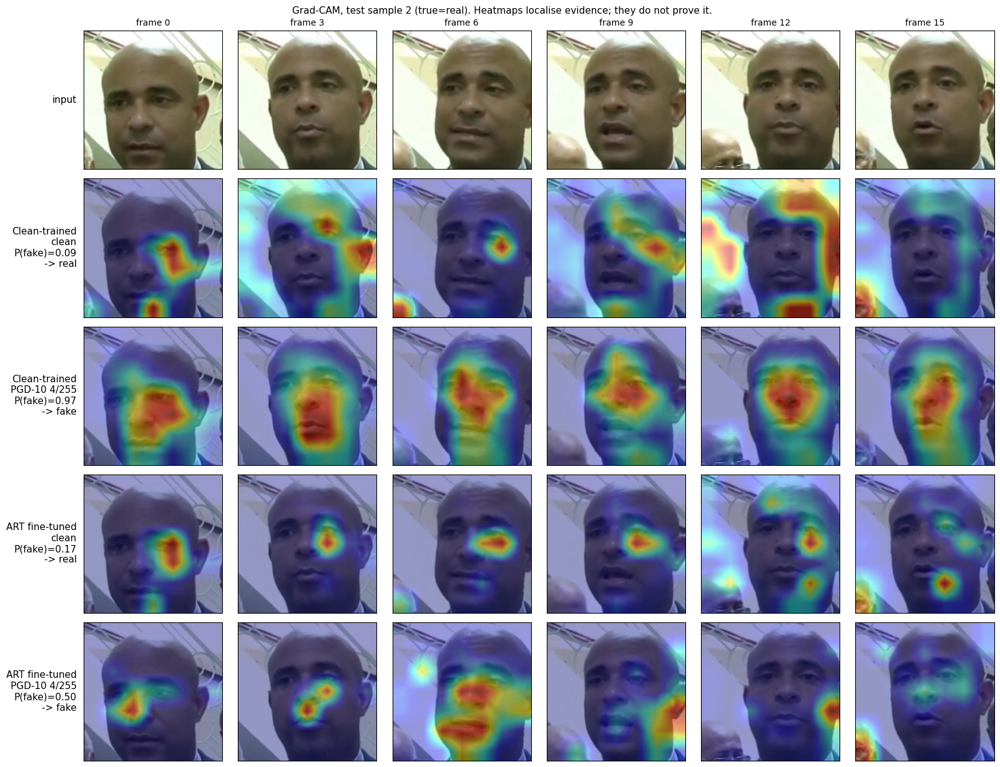

In [15]:
# ============================================================
# CELL 15: Grad-CAM -- both models, clean AND adversarial input (review item 16)
# ============================================================
# Target layer: the final EfficientNet-B1 stage block. fp32, BN/dropout frozen via _prepare_model_for_attack
# (the LSTM keeps cuDNN's training-mode backward). Hooks are removed after every call. CAVEAT: Grad-CAM shows
# where evidence came from; it does not prove the manipulation artifact.

class VideoGradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.gradients = None
        self.activations = None
        self.handles = [target_layer.register_forward_hook(self._save_act),
                        target_layer.register_full_backward_hook(self._save_grad)]

    def _save_act(self, module, inp, out):
        self.activations = out.detach()

    def _save_grad(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def remove(self):
        for h in self.handles:
            h.remove()

    def heatmaps(self, video_tensor):
        """video_tensor: [1, T, 3, H, W] -> (fake probability, per-frame heatmaps [T, h, w])."""
        prev = _prepare_model_for_attack(self.model)
        try:
            x = video_tensor.clone().detach().requires_grad_(True)
            logits = self.model(x)
            prob = torch.sigmoid(logits.float()).item()
            self.model.zero_grad()
            logits.sum().backward()
            weights = self.gradients.mean(dim=(2, 3), keepdim=True)
            cams = Fn.relu((weights * self.activations).sum(dim=1))
            maps = []
            for cam in cams:
                cam = cam - cam.min()
                maps.append((cam / (cam.max() + 1e-7)).cpu().numpy())
        finally:
            _restore_model_modes(self.model, prev)
        return prob, np.array(maps)


def cam_rows_for(model, video, thr, T_):
    cam = VideoGradCAM(model, model.feature_extractor[0][-1])
    try:
        prob, maps = cam.heatmaps(video)
    finally:
        cam.remove()
    return prob, maps


def _overlay(frame_norm, heat):
    img = np.clip(np.array(IMAGENET_STD) * frame_norm + np.array(IMAGENET_MEAN), 0, 1)
    img8 = (img * 255).astype(np.uint8)
    h = cv2.resize(heat, (img8.shape[1], img8.shape[0]))
    colour = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * h), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    return img, cv2.addWeighted(img8, 0.6, colour, 0.4, 0)


def gradcam_comparison(sample_idx, n_show=6):
    video, label = test_dataset[sample_idx]
    video = video.unsqueeze(0).to(CONFIG["device"])
    y = label.view(1).to(CONFIG["device"])
    # adversarial example crafted against EACH model (white-box), PGD-10 at 4/255, fp32
    results = {}
    for name, mdl, T_, thr_ in [("Clean-trained", clean_model, clean_T, clean_selected_threshold),
                                ("ART fine-tuned", art_model, art_T, art_selected_threshold)]:
        adv = pgd_attack(mdl, video, y, epsilon=4 / 255, alpha=CONFIG["pgd_step_mult"] * 4 / 255 / 10, steps=10,
                         use_amp=False)
        for kind, inp in [("clean", video), ("PGD-10 4/255", adv)]:
            with torch.no_grad():
                p = float(torch.sigmoid(mdl(inp).float() / T_).item())
            _, maps = cam_rows_for(mdl, inp, thr_, T_)
            results[(name, kind)] = (inp, p, maps, thr_)
    fidx = np.linspace(0, CONFIG["seq_len"] - 1, n_show, dtype=int)
    fig, axes = plt.subplots(5, n_show, figsize=(2.3 * n_show + 2.5, 12.5))
    base = video[0].cpu().numpy()
    for j, f in enumerate(fidx):
        axes[0, j].imshow(_overlay(base[f].transpose(1, 2, 0), np.zeros((7, 7)))[0])
        axes[0, j].set_title(f"frame {f}", fontsize=10)
    axes[0, 0].set_ylabel("input", fontsize=11, rotation=0, ha="right", va="center", labelpad=8)
    row = 1
    for name in ["Clean-trained", "ART fine-tuned"]:
        for kind in ["clean", "PGD-10 4/255"]:
            inp, p, maps, thr_ = results[(name, kind)]
            arr = inp[0].detach().cpu().numpy()
            for j, f in enumerate(fidx):
                axes[row, j].imshow(_overlay(arr[f].transpose(1, 2, 0), maps[f])[1])
            pred = "fake" if p >= thr_ else "real"
            axes[row, 0].set_ylabel(f"{name}\n{kind}\nP(fake)={p:.2f}\n-> {pred}", fontsize=11, rotation=0,
                                     ha="right", va="center", labelpad=8)
            print(f"  sample {sample_idx} (true={'fake' if int(label.item()) else 'real'}) | {name:<14} | {kind:<13} | "
                  f"P(fake)={p:.3f} (thr {thr_:.3f}) -> predicted {pred}")
            row += 1
    for ax in axes.ravel():
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"Grad-CAM, test sample {sample_idx} (true={'fake' if int(label.item()) else 'real'}). "
                 f"Heatmaps localise evidence; they do not prove it.", fontsize=11)
    plt.tight_layout()
    plt.savefig(f"/kaggle/working/gradcam_comparison_{sample_idx}.png", dpi=130)
    plt.show()


print("INTERPRETATION CAVEAT: Grad-CAM shows which spatial regions contributed to the prediction. It does NOT by "
      "itself prove the manipulation artifact -- treat it as a localisation aid, not ground-truth evidence.\n")
_fake_idx = next(i for i, (_, l) in enumerate(test_records) if l == 1)
_real_idx = next(i for i, (_, l) in enumerate(test_records) if l == 0)
for _i in (_fake_idx, _real_idx):
    gradcam_comparison(_i)
free_cuda_memory()


In [16]:
# ============================================================
# CELL 16: Optional -- consecutive-clip variant (review item 12)
# ============================================================
# The main model sees 16 frames spread over the WHOLE video, so neighbouring frames are far apart in time and
# there is little short-range motion for the LSTM to use. This optional experiment (CONFIG["run_clip_variant"])
# extracts 16 CONSECUTIVE frames (every `clip_stride`-th frame) from the middle of each selected video, trains a
# CLEAN model with the same recipe and compares it against the evenly-spaced model on the same test videos
# (clean AUC / accuracy only, no adversarial part). Off by default: it costs a second extraction and training.

clip_results = None
if not CONFIG["run_clip_variant"]:
    print("Clip variant skipped (CONFIG['run_clip_variant']=False).")
else:
    t_clip = time.time()
    out_root = Path(CONFIG["face_frames_clip_dir"])
    seq, stride = CONFIG["seq_len"], CONFIG["clip_stride"]

    def extract_clip(folder):
        info = record_info[folder]
        name = Path(folder).name
        sub = "real" if Path(folder).parent.name == "real" else "fake"
        dst = out_root / sub / name
        if dst.exists() and len(list(dst.glob("*.jpg"))) >= seq:
            return str(dst)
        cap = cv2.VideoCapture(info["video_path"])
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        start = max(0, total // 2 - (seq * stride) // 2)
        cap.set(cv2.CAP_PROP_POS_FRAMES, start)
        frames, k = [], 0
        while len(frames) < seq and cap.isOpened():
            ok, fr = cap.read()
            if not ok:
                break
            if k % stride == 0:
                frames.append(fr)
            k += 1
        cap.release()
        if len(frames) < seq:
            return None
        meta = FACE_BOXES.get(name)
        if meta and meta["hw"] == [frames[0].shape[0], frames[0].shape[1]]:
            x0, y0, x1, y1 = meta["box"]                      # same stable box as the evenly spaced crops
        else:
            x0, y0, x1, y1, _, _ = _video_face_square(frames, CONFIG["face_margin"])
        dst.mkdir(parents=True, exist_ok=True)
        cs = CONFIG["face_crop_size"]
        for i, fr in enumerate(frames):
            cv2.imwrite(str(dst / f"frame_{i:03d}.jpg"),
                        cv2.resize(fr[y0:y1, x0:x1], (cs, cs), interpolation=cv2.INTER_AREA),
                        [int(cv2.IMWRITE_JPEG_QUALITY), 95])
        return str(dst)

    def to_clip_records(recs):
        out = []
        for f, l in tqdm(recs, desc="clip extraction", leave=False):
            c = extract_clip(f)
            if c is not None:
                record_info.setdefault(c, dict(record_info[f]))
                out.append((c, l))
        return out

    clip_train, clip_val, clip_test = to_clip_records(train_records), to_clip_records(val_records), to_clip_records(test_records)
    print(f"Clip records: train={len(clip_train)} val={len(clip_val)} test={len(clip_test)}")

    # swap the globals used by run_staged_training, then restore them
    _saved = (train_loader, val_loader)
    train_loader = DataLoader(PreextractedVideoDataset(clip_train, CONFIG["seq_len"], CONFIG["img_size"], True),
                              batch_size=CONFIG["batch_size"], shuffle=True, num_workers=CONFIG["num_workers"],
                              worker_init_fn=worker_init_fn, drop_last=True, pin_memory=True)
    val_loader = make_eval_loader(PreextractedVideoDataset(clip_val, CONFIG["seq_len"], CONFIG["img_size"], False),
                                  CONFIG["eval_batch_size"])
    try:
        set_global_seed(CONFIG["seed"])
        clip_model = build_model()
        _, clip_best = run_staged_training(clip_model, "/kaggle/working/best_clip_model.pth", history_tag="clip")
        ck = torch.load("/kaggle/working/best_clip_model.pth", map_location=CONFIG["device"], weights_only=False)
        clip_model.load_state_dict(ck["model_state_dict"])
        T_c, thr_c, _ = calibrate_and_threshold(clip_model, "Clip variant")
        clip_test_loader = make_eval_loader(PreextractedVideoDataset(clip_test, CONFIG["seq_len"], CONFIG["img_size"], False),
                                            CONFIG["eval_batch_size"])
        lc, zc = get_logits(clip_model, clip_test_loader, None, desc="clip test")
        pc = sigmoid_np(zc, T_c)
        mc = compute_metrics(lc, pc, thr_c)
    finally:
        train_loader, val_loader = _saved
    # the evenly spaced model on the SAME test videos (matched by source video path)
    keep = {record_info[f]["video_path"] for f, _ in clip_test}
    sel = [i for i, (f, _) in enumerate(test_records) if record_info[f]["video_path"] in keep]
    me = compute_metrics(clean_test_labels[sel], sigmoid_np(clean_test_logits[sel], clean_T), clean_selected_threshold)
    clip_results = pd.DataFrame([
        {"Variant": "evenly spaced 16 (main)", "Test acc": me["accuracy"], "Test ROC-AUC": me["roc_auc"], "n": len(sel)},
        {"Variant": f"consecutive clip (stride {stride})", "Test acc": mc["accuracy"], "Test ROC-AUC": mc["roc_auc"], "n": len(lc)},
    ])
    print(clip_results.round(4).to_string(index=False))
    print(f"(took {(time.time() - t_clip) / 60:.0f} min; with {len(lc)} videos differences below ~4 points are within noise.)")
    del clip_model
    free_cuda_memory()


Clip variant skipped (CONFIG['run_clip_variant']=False).


In [17]:
# ============================================================
# CELL 17: Final comparison table and saved artifacts
# ============================================================
# Built programmatically from `comparison_df` (Cells 12 and 12b). Attacked rows come from fp32 attacks on the shared
# balanced test subset; 'Clean (full test)' uses every test video. Suspicious rows (robust accuracy above
# clean accuracy) are flagged, not hidden.

PUBLICATION_CONDITIONS = (["Clean (full test)", "Clean"] + [c for c, _ in CONDITIONS]
                          + sorted(worst_df["Condition"].unique().tolist()))

publication_table = comparison_df[comparison_df["Condition"].isin(PUBLICATION_CONDITIONS)].copy()
publication_table["Condition"] = pd.Categorical(publication_table["Condition"], categories=PUBLICATION_CONDITIONS, ordered=True)
publication_table = publication_table.sort_values(["Model", "Condition"]).reset_index(drop=True)
publication_table["Accuracy (95% CI)"] = publication_table.apply(
    lambda r: f"{r['accuracy']:.3f} [{r['acc_ci_lo']:.3f}, {r['acc_ci_hi']:.3f}]", axis=1)
publication_table["ASR (%)"] = publication_table["asr"].apply(lambda x: "N/A" if pd.isna(x) else f"{x * 100:.1f}")
publication_table = publication_table.rename(columns={
    "f1": "Macro F1", "balanced_accuracy": "Balanced Acc.", "roc_auc": "ROC-AUC", "pr_auc": "PR-AUC",
    "F1 Retention %": "F1 Retention (%)", "n_videos": "n"})
publication_table = publication_table[[
    "Model", "Condition", "n", "Accuracy (95% CI)", "ROC-AUC", "Macro F1", "Balanced Acc.", "PR-AUC",
    "F1 Retention (%)", "ASR (%)", "Reading"]]

print("=" * 150)
print("FINAL ADVERSARIAL ROBUSTNESS TABLE (identity-disjoint test set, fp32 attacks, each model at its own validation-selected threshold)")
print("=" * 150)
print(publication_table.round(4).to_string(index=False))
print(f"\nSelected thresholds ({CONFIG['threshold_method']}, calibrated probabilities, validation only) -- "
      f"Clean-trained: {clean_selected_threshold:.3f} (T={clean_T:.2f}) | ART: {art_selected_threshold:.3f} (T={art_T:.2f})")
print("\nHow to read this table:")
print("  * ROC-AUC under attack is threshold-free and the most reliable robustness number; accuracy depends on the threshold.")
print("  * A row marked SUSPICIOUS means robust accuracy exceeds clean accuracy: that is a sign of label leaking, not robustness.")
print("  * 'F1 Retention' above 100% is not a result; treat it as a diagnostic flag.")
print("  * WORST-CASE rows: a video counts only if correct under EVERY attack at that epsilon; AUC is the minimum over attacks.")
print("  * Differences smaller than the confidence intervals / McNemar p-values in Cell 12 are not evidence of an effect.")
if clip_results is not None:
    print("\nClip-variant comparison (clean models only):")
    print(clip_results.round(4).to_string(index=False))


# ---- Persist run artifacts ----
def _json_safe(v):
    if isinstance(v, torch.device):
        return str(v)
    return v


run_summary = {
    "config": {k: _json_safe(v) for k, v in CONFIG.items()},
    "clean_best_val_auc": clean_best_val_auc,
    "art_best_selection_score": art_best_score,
    "clean_temperature": clean_T, "art_temperature": art_T,
    "clean_selected_threshold": clean_selected_threshold,
    "art_selected_threshold": art_selected_threshold,
    "identity_split": {s: {"videos": len(split_records[s]), "identities": len(ids_by_split[s])} for s in SPLITS},
    "publication_table": publication_table.to_dict(orient="records"),
    "full_robustness_comparison": comparison_df.to_dict(orient="records"),
    "mcnemar_clean_vs_art": mcnemar_df.to_dict(orient="records"),
    "confidence_degradation": confidence_df.to_dict(orient="records"),
    "clean_per_method": clean_method_df.to_dict(orient="records"),
    "clip_variant": None if clip_results is None else clip_results.to_dict(orient="records"),
    "worst_case": worst_df.to_dict(orient="records"),
    "pgd_epsilon_sweep": sweep_df2.to_dict(orient="records"),
    "transfer_clean_to_art": {"eps": CONFIG["transfer_eps"], "accuracy": tr_acc, "roc_auc": tr_auc},
    "gradient_masking_checks": masking_df.to_dict(orient="records"),
    "art_history": art_history.to_dict(orient="records"),
}
with open(CONFIG["save_best_metrics_path"], "w") as f:
    json.dump(run_summary, f, indent=2, default=str)
with open(CONFIG["save_run_config_path"], "w") as f:
    json.dump({k: _json_safe(v) for k, v in CONFIG.items()}, f, indent=2, default=str)
print(f"\nSaved final metrics to {CONFIG['save_best_metrics_path']}")
print(f"Saved run configuration to {CONFIG['save_run_config_path']}")


FINAL ADVERSARIAL ROBUSTNESS TABLE (identity-disjoint test set, fp32 attacks, each model at its own validation-selected threshold)
         Model           Condition   n    Accuracy (95% CI)  ROC-AUC  Macro F1  Balanced Acc.  PR-AUC  F1 Retention (%) ASR (%)                                                             Reading
ART fine-tuned   Clean (full test) 400 0.858 [0.820, 0.888]   0.9373    0.8575         0.8575  0.9456           99.1324     N/A                                                                    
ART fine-tuned               Clean 200 0.865 [0.811, 0.906]   0.9430    0.8650         0.8650  0.9527          100.0000     N/A                                                                    
ART fine-tuned          FGSM 2/255 200 0.495 [0.426, 0.564]   0.8503    0.3311         0.4950  0.7441           38.2780    50.9                                                                    
ART fine-tuned          FGSM 4/255 200 0.500 [0.431, 0.569]   0.8119    0.3333       

In [18]:
# ============================================================
# CELL 18: Extra training seeds (review item 7) -- time-guarded
# ============================================================
# v6 targets ONE ~6 h run inside an 8 h Kaggle budget, so CONFIG["extra_seeds"] is [] by default and this cell is a no-op
# (the time guard below would skip extra seeds anyway). To get a spread, run the notebook again in a new session with
# CONFIG["seed"] changed (the identity split uses split_seed and stays the same), then compare best_metrics.json files.
# If enabled it repeats clean training + ART + evaluation for each seed in CONFIG["extra_seeds"], on the
# SAME identity-disjoint split and the same attack subset, using CONFIG["multiseed_pgd_configs"]. A new seed only
# starts if it is expected to finish inside CONFIG["time_budget_hours"] (estimated from the main run's duration).
# Set CONFIG["extra_seeds"] = [] to skip. Results: mean +/- std across seeds (seed 42 is the main run above).

def _summarise(model_tag, T_, thr_, store, seed):
    rows = []
    for cname in ["Clean (full test)", "Clean"] + [f"{n} {round(e * 255)}/255 (r{r})" for n, e, s, r in CONFIG["multiseed_pgd_configs"]]:
        l_, z_ = store[(model_tag, cname)]
        p_ = sigmoid_np(z_, T_)
        m = compute_metrics(l_, p_, thr_)
        rows.append({"seed": seed, "Model": model_tag, "Condition": cname, "accuracy": m["accuracy"], "roc_auc": m["roc_auc"]})
    return rows


seed_rows = (_summarise("Clean-trained", clean_T, clean_selected_threshold, raw_cache, CONFIG["seed"]) +
             _summarise("ART fine-tuned", art_T, art_selected_threshold, raw_cache, CONFIG["seed"]))

ms_conditions = make_conditions([], CONFIG["multiseed_pgd_configs"], ())
budget_s = CONFIG["time_budget_hours"] * 3600.0
done_seeds = [CONFIG["seed"]]

for sd in CONFIG["extra_seeds"]:
    elapsed = time.time() - NOTEBOOK_START
    # the extra seed skips Grad-CAM/plots and one PGD config, so ~0.85x of the main run is a safe estimate
    if elapsed + 0.85 * MAIN_RUN_SECONDS > budget_s:      # (an extra seed needs ~the main run again)
        print(f"Seed {sd}: SKIPPED -- {elapsed / 3600:.1f} h elapsed + ~{0.85 * MAIN_RUN_SECONDS / 3600:.1f} h needed "
              f"exceeds the {CONFIG['time_budget_hours']} h budget.")
        continue
    print("\n" + "#" * 70 + f"\n# EXTRA SEED {sd}\n" + "#" * 70)
    ck_clean = f"/kaggle/working/seed{sd}_clean.pth"
    ck_art = f"/kaggle/working/seed{sd}_art.pth"
    m_clean, _, best_auc = train_clean_model(sd, ck_clean)
    state = torch.load(ck_clean, map_location=CONFIG["device"], weights_only=False)
    m_clean.load_state_dict(state["model_state_dict"])
    m_clean.eval()
    T_c, thr_c, _ = calibrate_and_threshold(m_clean, f"seed {sd} clean")

    m_art, _, _ = finetune_adversarial(CONFIG["art_epsilon"], art_clean_w, art_adv_w, CONFIG["art_finetune_epochs"],
                                       tag=f"ART seed {sd}", init_state=state["model_state_dict"], save_path=ck_art, seed=sd)
    ck_a = torch.load(ck_art, map_location=CONFIG["device"], weights_only=False)
    m_art.load_state_dict(ck_a["model_state_dict"])
    m_art.eval()
    T_a, thr_a, _ = calibrate_and_threshold(m_art, f"seed {sd} ART")

    store = {}
    evaluate_all_conditions(m_clean, T_c, thr_c, "Clean-trained", ms_conditions, store=store)
    evaluate_all_conditions(m_art, T_a, thr_a, "ART fine-tuned", ms_conditions, store=store)
    seed_rows += _summarise("Clean-trained", T_c, thr_c, store, sd) + _summarise("ART fine-tuned", T_a, thr_a, store, sd)
    done_seeds.append(sd)
    del m_clean, m_art, store
    free_cuda_memory()

seed_df = pd.DataFrame(seed_rows)
print("\n" + "=" * 80)
print(f"MULTI-SEED SUMMARY (seeds run: {done_seeds})" + ("" if CONFIG["extra_seeds"] else "  -- single seed (extra_seeds=[]); re-run with another CONFIG['seed'] for a spread"))
print("=" * 80)
agg = (seed_df.groupby(["Model", "Condition"])[["accuracy", "roc_auc"]]
       .agg(["mean", "std"]).round(4))
print(agg.to_string())
if len(done_seeds) < 3 and CONFIG["extra_seeds"]:
    print(f"\nNOTE: only {len(done_seeds)} seed(s) completed; the review asks for >= 3 for a meaningful spread. "
          f"Increase CONFIG['time_budget_hours'] or run the notebook again with other seeds.")
with open("/kaggle/working/multiseed_results.json", "w") as f:
    json.dump({"seeds": done_seeds, "rows": seed_df.to_dict(orient="records")}, f, indent=2, default=str)
print("Saved /kaggle/working/multiseed_results.json")



MULTI-SEED SUMMARY (seeds run: [42])  -- single seed (extra_seeds=[]); re-run with another CONFIG['seed'] for a spread
                                 accuracy     roc_auc    
                                     mean std    mean std
Model          Condition                                 
ART fine-tuned Clean               0.8650 NaN  0.9430 NaN
               Clean (full test)   0.8575 NaN  0.9373 NaN
               PGD-10 2/255 (r2)   0.3700 NaN  0.2172 NaN
               PGD-10 4/255 (r2)   0.5000 NaN  0.2200 NaN
Clean-trained  Clean               0.8700 NaN  0.9487 NaN
               Clean (full test)   0.8750 NaN  0.9456 NaN
               PGD-10 2/255 (r2)   0.0000 NaN  0.0000 NaN
               PGD-10 4/255 (r2)   0.0000 NaN  0.0000 NaN
Saved /kaggle/working/multiseed_results.json
